
## Smart Attendance System – Face Recognition

The self-collected student face dataset is available under `dataset/`. This notebook calculates EDA results at run time and excludes GUI assets in `collage_images/`.

**Extended project:** Comparative Analysis of CNN, SimpleRNN and LSTM for Student Face Recognition with a Local Attendance Demonstration. Original EDA outputs are preserved as historical observations; new cells are unexecuted. Restart and run top to bottom for a coherent current result. NN-10A–D trains/selects recurrent models before any test evaluation; NN-22–42 supplies comparative reporting, saving and demonstration guidance.

## Setup — Anaconda base, automatic downloads, CUDA only

On your friend's Windows computer, select the **Anaconda base** Python kernel, restart it, and press **Run All**. Keep this notebook and all project `.py`/requirements files together. The cell below installs missing packages into that kernel's base environment using its exact Python executable; it keeps an existing compatible CUDA PyTorch build. Internet access and a working NVIDIA driver are required for first-time setup. Nothing is installed in another environment.

Setup runs before EDA imports. Download time depends on the connection (the CUDA wheel can be large). When dependencies are already present, they are reused. If an already-loaded native library must be replaced, a restart is necessary; it is not safe to promise hot-reloading. If CUDA is unavailable, execution stops rather than training on CPU. No external face dataset is downloaded: supply the consented local `dataset/`.


In [1]:
from pathlib import Path
import sys
import os

# Must precede NumPy/torch imports; no unsafe duplicate-OpenMP override is used.
os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

PROJECT_ROOT_OVERRIDE = None  # Set only if the kernel starts outside the shared project folder.
PROJECT_ROOT = (Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve() if PROJECT_ROOT_OVERRIDE
                else next((p for p in [Path.cwd(), *Path.cwd().parents]
                           if (p / "project_setup.py").is_file()), Path.cwd()))
if not (PROJECT_ROOT / "project_setup.py").is_file():
    raise FileNotFoundError("Keep project_setup.py and the other project files beside this notebook.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from project_setup import ensure_environment
GPU_SETUP = ensure_environment(PROJECT_ROOT)


Anaconda base: c:\Users\Asus\anaconda3\python.exe
Ready: PyTorch 2.14.1+cu126 | CUDA 12.6 | NVIDIA GeForce RTX 3050 Ti Laptop GPU
Dependencies ready. Continuing with EDA and CUDA training; no CPU fallback.


In [2]:
from pathlib import Path
import hashlib
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError

# PROJECT_ROOT was resolved by the Setup cell before any numerical imports.
DATASET_DIR = PROJECT_ROOT / "dataset"
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

def discover_images(root=DATASET_DIR):
    """Find supported images without ever scanning the GUI asset directory."""
    root = Path(root)
    if not root.exists() or not root.is_dir():
        return []
    return sorted(p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS)

def class_from_path(path, root=DATASET_DIR):
    try:
        relative = Path(path).relative_to(root)
        return relative.parts[0] if len(relative.parts) > 1 else ""
    except ValueError:
        return ""

image_paths = discover_images()
dataset_available = DATASET_DIR.exists() and bool(image_paths)
if not dataset_available:
    print("Dataset has not been collected yet. Add student face images to the dataset/ directory to populate this section.")

## 1. Dataset Card

- **Dataset name:** Smart Attendance System – Student Face Dataset
- **Source:** Self-collected for the TECH 405 Smart Attendance System project
- **Source link:** Not applicable – self-collected dataset
- **Licence:** Private academic dataset; not publicly licensed
- **Data type:** Grayscale student face images
- **Task:** Student face identification / recognition for automated attendance
- **Target:** Student identity
- **Current enrolled identities:** The current collection contains five student folders (calculated and verified below).
- **Size on disk, number of samples, and number of classes:** Calculated automatically below.

Observed current properties include five represented identities and a relatively small academic dataset. Possible risks include limited environmental diversity, similar collection conditions, lighting or pose bias, and limited generalization to unseen students. Privacy and informed-consent requirements remain important. These are limitations and risks to consider; equal image counts do not guarantee equal image quality or recognition difficulty.

In [3]:
def format_bytes(n):
    units = ["B", "KB", "MB", "GB"]
    value = float(n)
    for unit in units:
        if value < 1024 or unit == units[-1]:
            return f"{value:.2f} {unit}"
        value /= 1024

if image_paths:
    total_bytes = sum(p.stat().st_size for p in image_paths)
    classes = sorted({class_from_path(p) for p in image_paths if class_from_path(p)})
    card = pd.DataFrame({"Metric": ["Size on disk", "Number of samples", "Number of classes/students"],
                         "Value": [format_bytes(total_bytes), len(image_paths), len(classes)]})
    display(card)
else:
    print("Size, sample count, and class count: Pending dataset collection.")

,Metric,Value
0,Size on disk,2.28 MB
1,Number of samples,251
2,Number of classes/students,6


## 2. Data Loading and Initial Inspection

The expected layout is `dataset/student_id/image.ext`. The loader accepts JPG, JPEG, PNG, and WEBP files and records image metadata when Pillow can read it.

In [4]:
records = []
for path in image_paths:
    record = {"filepath": str(path), "filename": path.name, "class_name": class_from_path(path),
              "extension": path.suffix.lower(), "size_bytes": path.stat().st_size,
              "width": np.nan, "height": np.nan, "channels": np.nan, "image_mode": None}
    try:
        with Image.open(path) as img:
            record.update(width=img.width, height=img.height, image_mode=img.mode,
                          channels=len(img.getbands()))
    except (OSError, UnidentifiedImageError):
        pass
    records.append(record)

df = pd.DataFrame(records, columns=["filepath", "filename", "class_name", "extension", "size_bytes", "width", "height", "channels", "image_mode"])
print(f"Dataset shape: {df.shape}")
print(f"Number of classes: {df['class_name'].nunique() if not df.empty else 0}")
print("\nColumn data types:")
display(df.dtypes.to_frame("dtype"))
print("Directory/file structure summary:")
if df.empty:
    print("No supported dataset images found; structure summary is pending dataset collection.")
else:
    display(df.groupby("class_name", dropna=False).size().rename("image_count").to_frame())

Dataset shape: (251, 9)
Number of classes: 6

Column data types:


,dtype
filepath,object
filename,object
class_name,object
extension,object
size_bytes,int64
width,int64
height,int64
channels,int64
image_mode,object


Directory/file structure summary:


,image_count
class_name,
Amit,50
Shreejal,50
Subhash,1
Susman,50
Udhav,50
Uttam,50


Random sample metadata:


,filepath,filename,class_name,extension,size_bytes,width,height,channels,image_mode
155,c:\Users\Asus\OneDrive\Pictures\Smart_Attendance_System\dataset\Udhav\13.jpg,13.jpg,Udhav,.jpg,9111,200,200,1,L
6,c:\Users\Asus\OneDrive\Pictures\Smart_Attendance_System\dataset\Amit\15.jpg,15.jpg,Amit,.jpg,10283,200,200,1,L
164,c:\Users\Asus\OneDrive\Pictures\Smart_Attendance_System\dataset\Udhav\21.jpg,21.jpg,Udhav,.jpg,9353,200,200,1,L
60,c:\Users\Asus\OneDrive\Pictures\Smart_Attendance_System\dataset\Shreejal\19.jpg,19.jpg,Shreejal,.jpg,8291,200,200,1,L
113,c:\Users\Asus\OneDrive\Pictures\Smart_Attendance_System\dataset\Susman\20.jpg,20.jpg,Susman,.jpg,7658,200,200,1,L


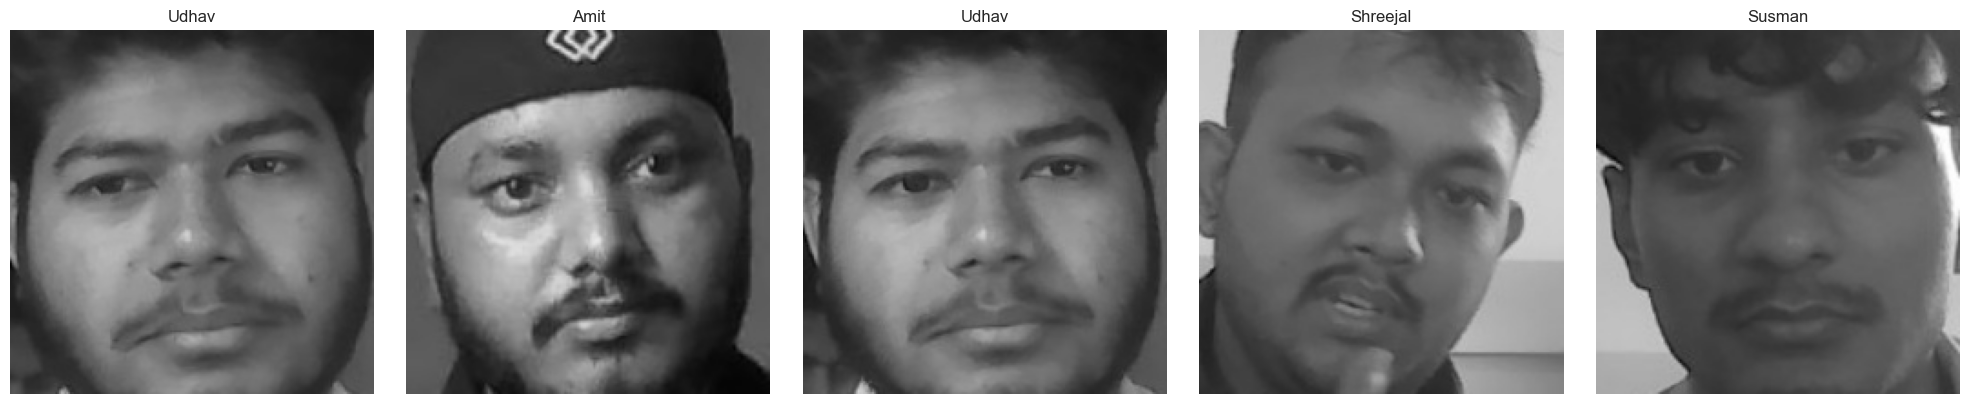

In [5]:
sample = df.sample(n=min(5, len(df)), random_state=RANDOM_STATE) if not df.empty else df
print("Random sample metadata:")
display(sample)
if sample.empty:
    print("Five random samples: Pending dataset collection.")
else:
    fig, axes = plt.subplots(1, len(sample), figsize=(4 * len(sample), 4), squeeze=False)
    for ax, (_, row) in zip(axes[0], sample.iterrows()):
        try:
            with Image.open(row["filepath"]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(row["class_name"] or "Unlabelled")
        except (OSError, UnidentifiedImageError):
            ax.text(0.5, 0.5, "Unreadable image", ha="center", va="center")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

## 3. Data Quality Audit

Traditional tabular missing values are not the only concern for image data. This audit checks empty labels/folders, zero-byte files, missing image metadata, unreadable files, and exact duplicate files.

In [6]:
empty_class_labels = int((df["class_name"] == "").sum()) if not df.empty else 0
zero_byte_files = int((df["size_bytes"] == 0).sum()) if not df.empty else 0
missing_metadata = int(df[["width", "height", "channels", "image_mode"]].isna().any(axis=1).sum()) if not df.empty else 0
empty_class_folders = []
if DATASET_DIR.exists():
    empty_class_folders = [str(p) for p in DATASET_DIR.iterdir() if p.is_dir() and not any(q.is_file() and q.suffix.lower() in SUPPORTED_EXTENSIONS for q in p.rglob("*"))]
quality_summary = pd.DataFrame({"Check": ["Missing/empty class labels", "Empty class folders", "Zero-byte files", "Rows with missing image metadata"],
                                 "Count": [empty_class_labels, len(empty_class_folders), zero_byte_files, missing_metadata]})
display(quality_summary)
if empty_class_folders:
    print("Empty class folders:", empty_class_folders)
if df.empty:
    print("Data quality counts are pending dataset collection.")

,Check,Count
0,Missing/empty class labels,0
1,Empty class folders,0
2,Zero-byte files,0
3,Rows with missing image metadata,0


In [7]:
corrupt_rows = []
hash_to_paths = {}
for path in image_paths:
    try:
        with Image.open(path) as img:
            img.verify()
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        hash_to_paths.setdefault(digest, []).append(str(path))
    except (OSError, UnidentifiedImageError, ValueError) as exc:
        corrupt_rows.append({"filepath": str(path), "error": type(exc).__name__})
corrupt_df = pd.DataFrame(corrupt_rows, columns=["filepath", "error"])
duplicate_groups = [paths for paths in hash_to_paths.values() if len(paths) > 1]
duplicate_files = sum(len(paths) - 1 for paths in duplicate_groups)
print(f"Valid images: {len(image_paths) - len(corrupt_df)}")
print(f"Corrupt/unreadable images: {len(corrupt_df)}")
display(corrupt_df if not corrupt_df.empty else pd.DataFrame({"Result": ["No corrupt files found in available data."]}))
print(f"Unique file-content hashes: {len(hash_to_paths)}")
print(f"Duplicate files beyond the first in each exact group: {duplicate_files}")
if duplicate_groups:
    display(pd.DataFrame({"duplicate_group": range(1, len(duplicate_groups) + 1), "paths": duplicate_groups}))
else:
    print("No exact duplicate groups found in available data." if image_paths else "Duplicate analysis is pending dataset collection.")
print("Intended treatment: Corrupt or unreadable images will be excluded from modelling and, where possible, recollected.")
print("Intended treatment: Exact duplicate images will be removed before model training to prevent artificial inflation of the dataset and leakage between data splits.")
print("Perceptual/near-duplicate detection may later be useful for almost identical consecutive webcam frames.")

Valid images: 251
Corrupt/unreadable images: 0


,Result
0,No corrupt files found in available data.


Unique file-content hashes: 251
Duplicate files beyond the first in each exact group: 0
No exact duplicate groups found in available data.
Intended treatment: Corrupt or unreadable images will be excluded from modelling and, where possible, recollected.
Intended treatment: Exact duplicate images will be removed before model training to prevent artificial inflation of the dataset and leakage between data splits.
Perceptual/near-duplicate detection may later be useful for almost identical consecutive webcam frames.


## 4. Class Distribution

The target variable is **student identity**. Counts and interpretation below are computed from the available dataset; no imbalance is assumed before collection.

,image_count
class_name,
Subhash,1
Amit,50
Susman,50
Shreejal,50
Udhav,50
Uttam,50


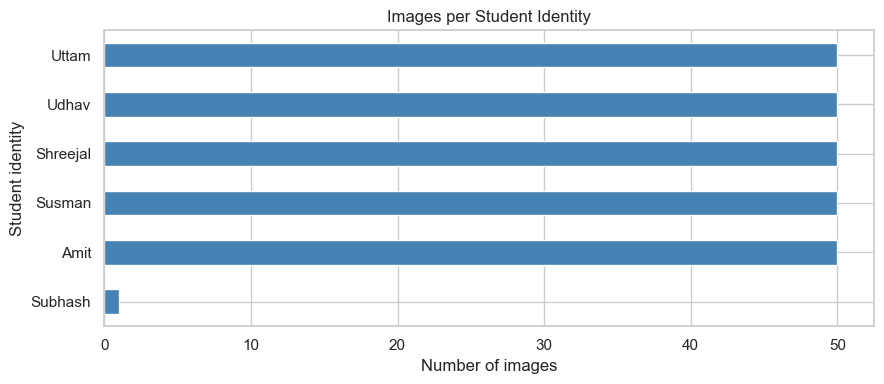

,Statistic,Value
0,Smallest class,1.000000
1,Largest class,50.000000
2,Mean,41.833333
3,Median,50.000000
4,Maximum/minimum ratio,50.000000


Computed interpretation: unequal class counts; maximum/minimum ratio = 50.00.
Imbalance matters because classes with more samples can dominate training, while students with fewer images may have poorer recognition accuracy. Consider similar collection targets, more data for underrepresented students, appropriate augmentation, class weighting, or balanced sampling.


In [8]:
class_counts = df["class_name"].value_counts().sort_values(ascending=True) if not df.empty else pd.Series(dtype="int64", name="image_count")
if class_counts.empty:
    print("Class distribution will be evaluated after face-image collection.")
else:
    display(class_counts.rename("image_count").to_frame())
    fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(class_counts))))
    class_counts.plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title("Images per Student Identity")
    ax.set_xlabel("Number of images")
    ax.set_ylabel("Student identity")
    plt.tight_layout(); plt.show(); plt.close(fig)
    smallest, largest = class_counts.min(), class_counts.max()
    ratio = largest / smallest if smallest else np.nan
    stats = pd.DataFrame({"Statistic": ["Smallest class", "Largest class", "Mean", "Median", "Maximum/minimum ratio"],
                         "Value": [smallest, largest, class_counts.mean(), class_counts.median(), ratio]})
    display(stats)
    if smallest == largest:
        print(f"Computed interpretation: the current class counts are perfectly balanced at {int(class_counts.iloc[0])} images per identity.")
    else:
        print(f"Computed interpretation: unequal class counts; maximum/minimum ratio = {ratio:.2f}.")
    print("Imbalance matters because classes with more samples can dominate training, while students with fewer images may have poorer recognition accuracy. Consider similar collection targets, more data for underrepresented students, appropriate augmentation, class weighting, or balanced sampling.")

## 5. Train / Validation / Test Split Plan

A starting plan is 70% training, 15% validation, and 15% test, adjusted for the final dataset size. For a closed-set enrolled-student identification system, every student should have sufficient representation in each split.

A naive random image-level split is risky when many images come from one webcam burst: nearly identical frames can appear in training and test, producing unrealistically high accuracy. The preferred approach is session-aware splitting within each student, for example `session_1 → train`, `session_2 → validation`, and `session_3 → test`. Collection should use multiple occasions and vary lighting, head pose, expression, distance, background, and time.

If the future goal changes to recognizing completely unseen identities with a verification/embedding model, evaluation by unseen identities may also be required. For this attendance system, the current assumption is enrolled-student identification.

In [9]:
def session_aware_split(metadata, session_col="session_id", class_col="class_name", seed=RANDOM_STATE):
    """Template: split complete capture sessions within each student.
    Requires one row per image and a session identifier; it does not perform a
    split without session metadata."""
    required = {session_col, class_col}
    missing = required.difference(metadata.columns)
    if missing:
        raise ValueError(f"Missing required metadata columns: {sorted(missing)}")
    rng = np.random.default_rng(seed)
    output = metadata.copy()
    output["split"] = None
    for student, group in output.groupby(class_col):
        sessions = list(group[session_col].dropna().unique())
        rng.shuffle(sessions)
        n = len(sessions)
        if group[session_col].isna().any() or n < 3:
            raise ValueError(f"Student {student} needs at least three complete capture sessions.")
        train_count = min(n - 2, max(1, round(0.70 * n)))
        validation_count = min(n - train_count - 1, max(1, round(0.15 * n)))
        boundaries = [train_count, train_count + validation_count]
        train_sessions, val_sessions = set(sessions[:boundaries[0]]), set(sessions[boundaries[0]:boundaries[1]])
        output.loc[group.index[group[session_col].isin(train_sessions)], "split"] = "train"
        output.loc[group.index[group[session_col].isin(val_sessions)], "split"] = "validation"
        output.loc[group.index[group[session_col].isin(set(sessions) - train_sessions - val_sessions)], "split"] = "test"
    return output

per_student = int(class_counts.iloc[0]) if not class_counts.empty else 0
train_n = round(0.70 * per_student); validation_n = round(0.15 * per_student); test_n = per_student - train_n - validation_n
print(f"Current split example per student: approximately {train_n} training, {validation_n} validation, and {test_n} test images from {per_student} images, following 70/15/15. No artificial split was performed in this notebook.")
print("Use session_aware_split(metadata) after adding a session_id column to the image metadata.")

Current split example per student: approximately 1 training, 0 validation, and 0 test images from 1 images, following 70/15/15. No artificial split was performed in this notebook.
Use session_aware_split(metadata) after adding a session_id column to the image metadata.


## 6. Model-Design Findings

### Findings status

The current dataset supports the following evidence-based model-design findings. These statements are based on the automatically computed EDA results for the present collection and should be revisited if the dataset changes.

- **Finding 1 – Resolution consistency:** All current images are 200 × 200 pixels. A 200 × 200 input is a reasonable initial preprocessing choice; resizing is not currently necessary, avoiding unnecessary interpolation.
- **Finding 2 – Balanced identities:** Each of the five student identities currently contributes 50 images, so class-count imbalance is not a current concern. Equal counts do not guarantee equal image quality, diversity, or recognition difficulty.
- **Finding 3 – Grayscale input:** All current images are grayscale with one channel. A one-channel model input is appropriate where supported; an RGB-only pretrained model would require channel repetition or conversion, and no color information is available.

The notebook continues to calculate these properties rather than relying on hard-coded values.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
width,251.0,NaN,NaN,NaN,204.932271,78.141867,200.0,200.0,200.0,200.0,1438.0
height,251.0,NaN,NaN,NaN,205.577689,88.367216,200.0,200.0,200.0,200.0,1600.0
aspect_ratio,251.0,NaN,NaN,NaN,0.999597,0.006391,0.89875,1.0,1.0,1.0,1.0
channels,251.0,NaN,NaN,NaN,1.007968,0.126239,1.0,1.0,1.0,1.0,3.0
image_mode,251,2,L,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN


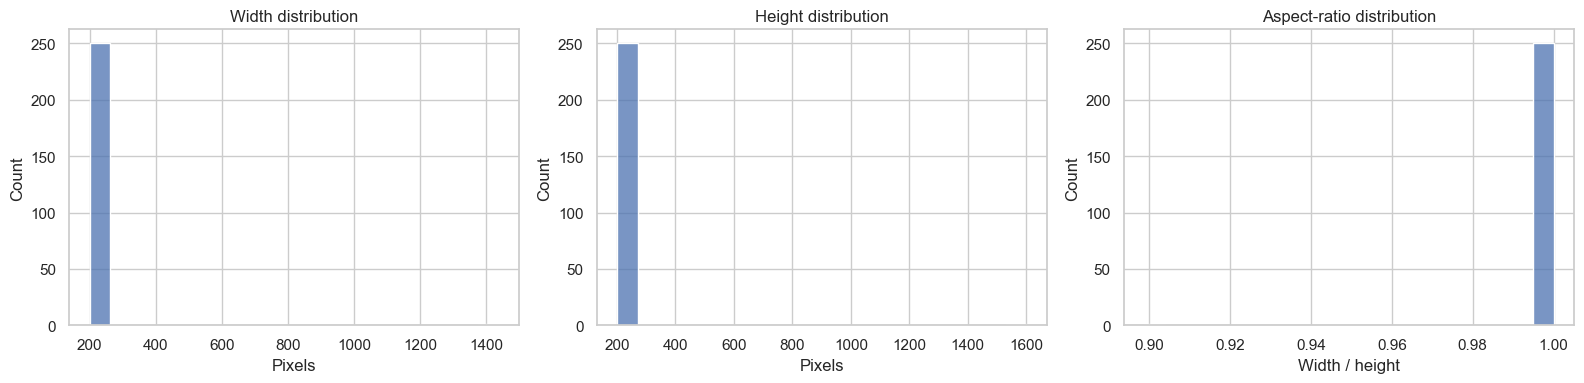

Image modes/channels:


,count
image_mode,
L,250
RGB,1


Computed hook: inspect these distributions before selecting a final target resolution; no resolution is recommended automatically without reviewing the collected data.
Computed evidence hook: no exact duplicates or unreadable metadata were detected in the available files; near-duplicate/session checks still require capture metadata.


In [10]:
if df.empty or df[["width", "height"]].dropna().empty:
    print("Resolution, aspect-ratio, channel, and mode findings are pending dataset collection.")
else:
    dimensions = df.dropna(subset=["width", "height"]).copy()
    dimensions["aspect_ratio"] = dimensions["width"] / dimensions["height"]
    display(dimensions[["width", "height", "aspect_ratio", "channels", "image_mode"]].describe(include="all").T)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    sns.histplot(dimensions["width"], ax=axes[0], bins=20); axes[0].set_title("Width distribution"); axes[0].set_xlabel("Pixels")
    sns.histplot(dimensions["height"], ax=axes[1], bins=20); axes[1].set_title("Height distribution"); axes[1].set_xlabel("Pixels")
    sns.histplot(dimensions["aspect_ratio"], ax=axes[2], bins=20); axes[2].set_title("Aspect-ratio distribution"); axes[2].set_xlabel("Width / height")
    plt.tight_layout(); plt.show(); plt.close(fig)
    print("Image modes/channels:")
    display(dimensions["image_mode"].value_counts(dropna=False).rename("count").to_frame())
    print("Computed hook: inspect these distributions before selecting a final target resolution; no resolution is recommended automatically without reviewing the collected data.")
    if duplicate_files or len(dimensions) != len(df):
        print("Computed evidence hook: duplicate or unreadable-file risk is present and should inform session-aware collection/evaluation.")
    else:
        print("Computed evidence hook: no exact duplicates or unreadable metadata were detected in the available files; near-duplicate/session checks still require capture metadata.")

## One-Page EDA Summary

The Smart Attendance System uses self-collected face images to identify enrolled students for automated attendance. The current dataset contains 250 images across five student identities, with 50 images per class. The class distribution is therefore balanced at the sample-count level.

All current images are JPG files, 200 × 200 pixels, grayscale, and one-channel. The audit found 250 valid images, no corrupt or unreadable files, and no exact duplicate files. These checks remain implemented so future additions are audited automatically.

A 70%/15%/15% plan gives approximately 35 training images and 7–8 validation/test images per student. If images were captured as consecutive frames in one session, a naive image-level split could leak near-identical frames across train and test. Session-aware splitting is preferred; session metadata is not currently recorded, so leakage cannot be claimed to be eliminated.

The current 200 × 200 grayscale format simplifies preprocessing. Future evaluation should still consider capture diversity, lighting, pose, background, privacy, consent, and generalization beyond the five represented identities.

## Part A Completion Checklist

1. Dataset card — completed with current dataset details and automatically calculated metrics.
2. Shape/dtypes/file structure and five random samples — completed from the real dataset.
3. Missing, duplicate, and corrupt audit — completed; current audit found no corrupt or exact duplicate files.
4. Class distribution and imbalance discussion — completed; current sample counts are balanced.
5. Train/validation/test split plan — completed with session-leakage warning.
6. Three evidence-based model-design findings — completed for resolution, identity balance, and grayscale input.

## Part B – Image / Vision

This section analyzes the real student face dataset discovered in Part A. It reuses the existing metadata and excludes GUI assets in `collage_images/`.

### 1. Image Size and Channel Distribution

Image dimensions, aspect ratios, modes, and channel counts are summarized below when valid dataset images are available. These results will help determine preprocessing requirements.


,width,height,aspect_ratio
count,251.000000,251.000000,251.000000
mean,204.932271,205.577689,0.999597
std,78.141867,88.367216,0.006391
min,200.000000,200.000000,0.898750
25%,200.000000,200.000000,1.000000
50%,200.000000,200.000000,1.000000
75%,200.000000,200.000000,1.000000
max,1438.000000,1600.000000,1.000000


,class_name,filepath,width,height,aspect_ratio,mode,channels
0,Amit,c:\Users\Asus\OneDrive\Pictures\Smart_Attendance_System\dataset\Amit\1.jpg,200,200,1.0,L,1
1,Amit,c:\Users\Asus\OneDrive\Pictures\Smart_Attendance_System\dataset\Amit\10.jpg,200,200,1.0,L,1
2,Amit,c:\Users\Asus\OneDrive\Pictures\Smart_Attendance_System\dataset\Amit\11.jpg,200,200,1.0,L,1
3,Amit,c:\Users\Asus\OneDrive\Pictures\Smart_Attendance_System\dataset\Amit\12.jpg,200,200,1.0,L,1
4,Amit,c:\Users\Asus\OneDrive\Pictures\Smart_Attendance_System\dataset\Amit\13.jpg,200,200,1.0,L,1


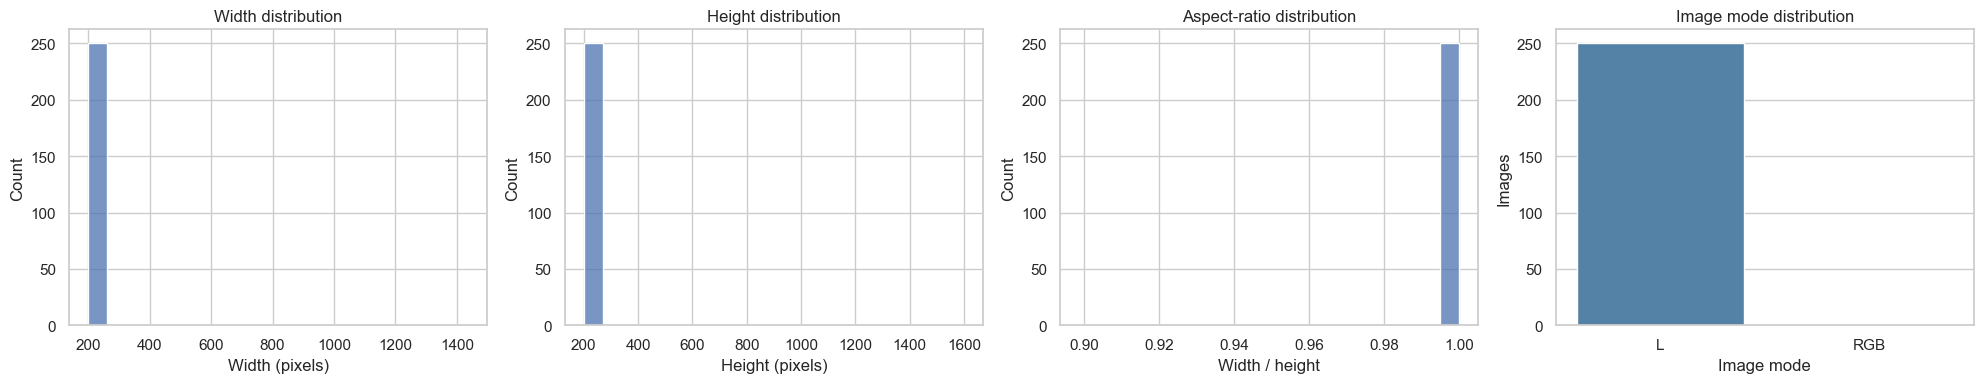

,image_count
channels,
1,250
3,1


In [11]:
vision_columns = ["class_name", "filepath", "width", "height", "aspect_ratio", "mode", "channels"]
vision_df = df.copy() if "df" in globals() else pd.DataFrame()
if not vision_df.empty:
    vision_df = vision_df.rename(columns={"image_mode": "mode"})
    for column in vision_columns:
        if column not in vision_df.columns:
            vision_df[column] = np.nan
    vision_df["aspect_ratio"] = vision_df["width"] / vision_df["height"]
    vision_df = vision_df[vision_columns]
    valid_vision_df = vision_df.dropna(subset=["width", "height", "channels"]).copy()
else:
    vision_df = pd.DataFrame(columns=vision_columns)
    valid_vision_df = vision_df.copy()

if valid_vision_df.empty:
    print("Image size and channel analysis is pending dataset collection.")
else:
    display(valid_vision_df[["width", "height", "aspect_ratio"]].describe())
    display(valid_vision_df[vision_columns].head())
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    sns.histplot(valid_vision_df["width"], bins=20, ax=axes[0]); axes[0].set_title("Width distribution"); axes[0].set_xlabel("Width (pixels)")
    sns.histplot(valid_vision_df["height"], bins=20, ax=axes[1]); axes[1].set_title("Height distribution"); axes[1].set_xlabel("Height (pixels)")
    sns.histplot(valid_vision_df["aspect_ratio"], bins=20, ax=axes[2]); axes[2].set_title("Aspect-ratio distribution"); axes[2].set_xlabel("Width / height")
    mode_counts = valid_vision_df["mode"].fillna("Unknown").value_counts()
    sns.barplot(x=mode_counts.index.astype(str), y=mode_counts.values, ax=axes[3], color="steelblue"); axes[3].set_title("Image mode distribution"); axes[3].set_xlabel("Image mode"); axes[3].set_ylabel("Images")
    plt.tight_layout(); plt.show(); plt.close(fig)
    display(valid_vision_df["channels"].value_counts().sort_index().rename("image_count").to_frame())

#### Target Resolution Decision

The final model input resolution must be selected after inspecting the real dimensions, aspect ratios, face detail, computational budget, and whether resizing or aspect-preserving cropping is appropriate. The EDA resolution below is only a decision aid; it is not automatically the final training resolution.


In [12]:
if valid_vision_df.empty:
    print("Final target resolution will be selected after the real face dataset is collected and inspected.")
else:
    dimension_summary = valid_vision_df[["width", "height"]].round().astype(int).mode()
    median_width = int(valid_vision_df["width"].median())
    median_height = int(valid_vision_df["height"].median())
    print(f"Most common width/height values, where available: {dimension_summary.to_dict(orient='records')}")
    print(f"Median dimensions: {median_width} × {median_height} pixels.")
    if (valid_vision_df["width"] == 200).all() and (valid_vision_df["height"] == 200).all():
        print("Evidence-based target resolution: 200 × 200 pixels. All current images already have this size, so resizing is unnecessary and avoidable interpolation can be minimized.")
    else:
        print("Recommendation hook: use a practical, aspect-preserving input size supported by the common dimensions and available face detail; do not stretch images. Review the actual distributions before finalizing it.")

Most common width/height values, where available: [{'width': 200, 'height': 200}]
Median dimensions: 200 × 200 pixels.
Recommendation hook: use a practical, aspect-preserving input size supported by the common dimensions and available face detail; do not stretch images. Review the actual distributions before finalizing it.


### 2. Sample Images Per Class

Visual inspection helps identify whether each student has enough variation in lighting, pose, expression, camera distance, background, blur, and occlusion. No dataset-specific visual claim is made until real images are available.


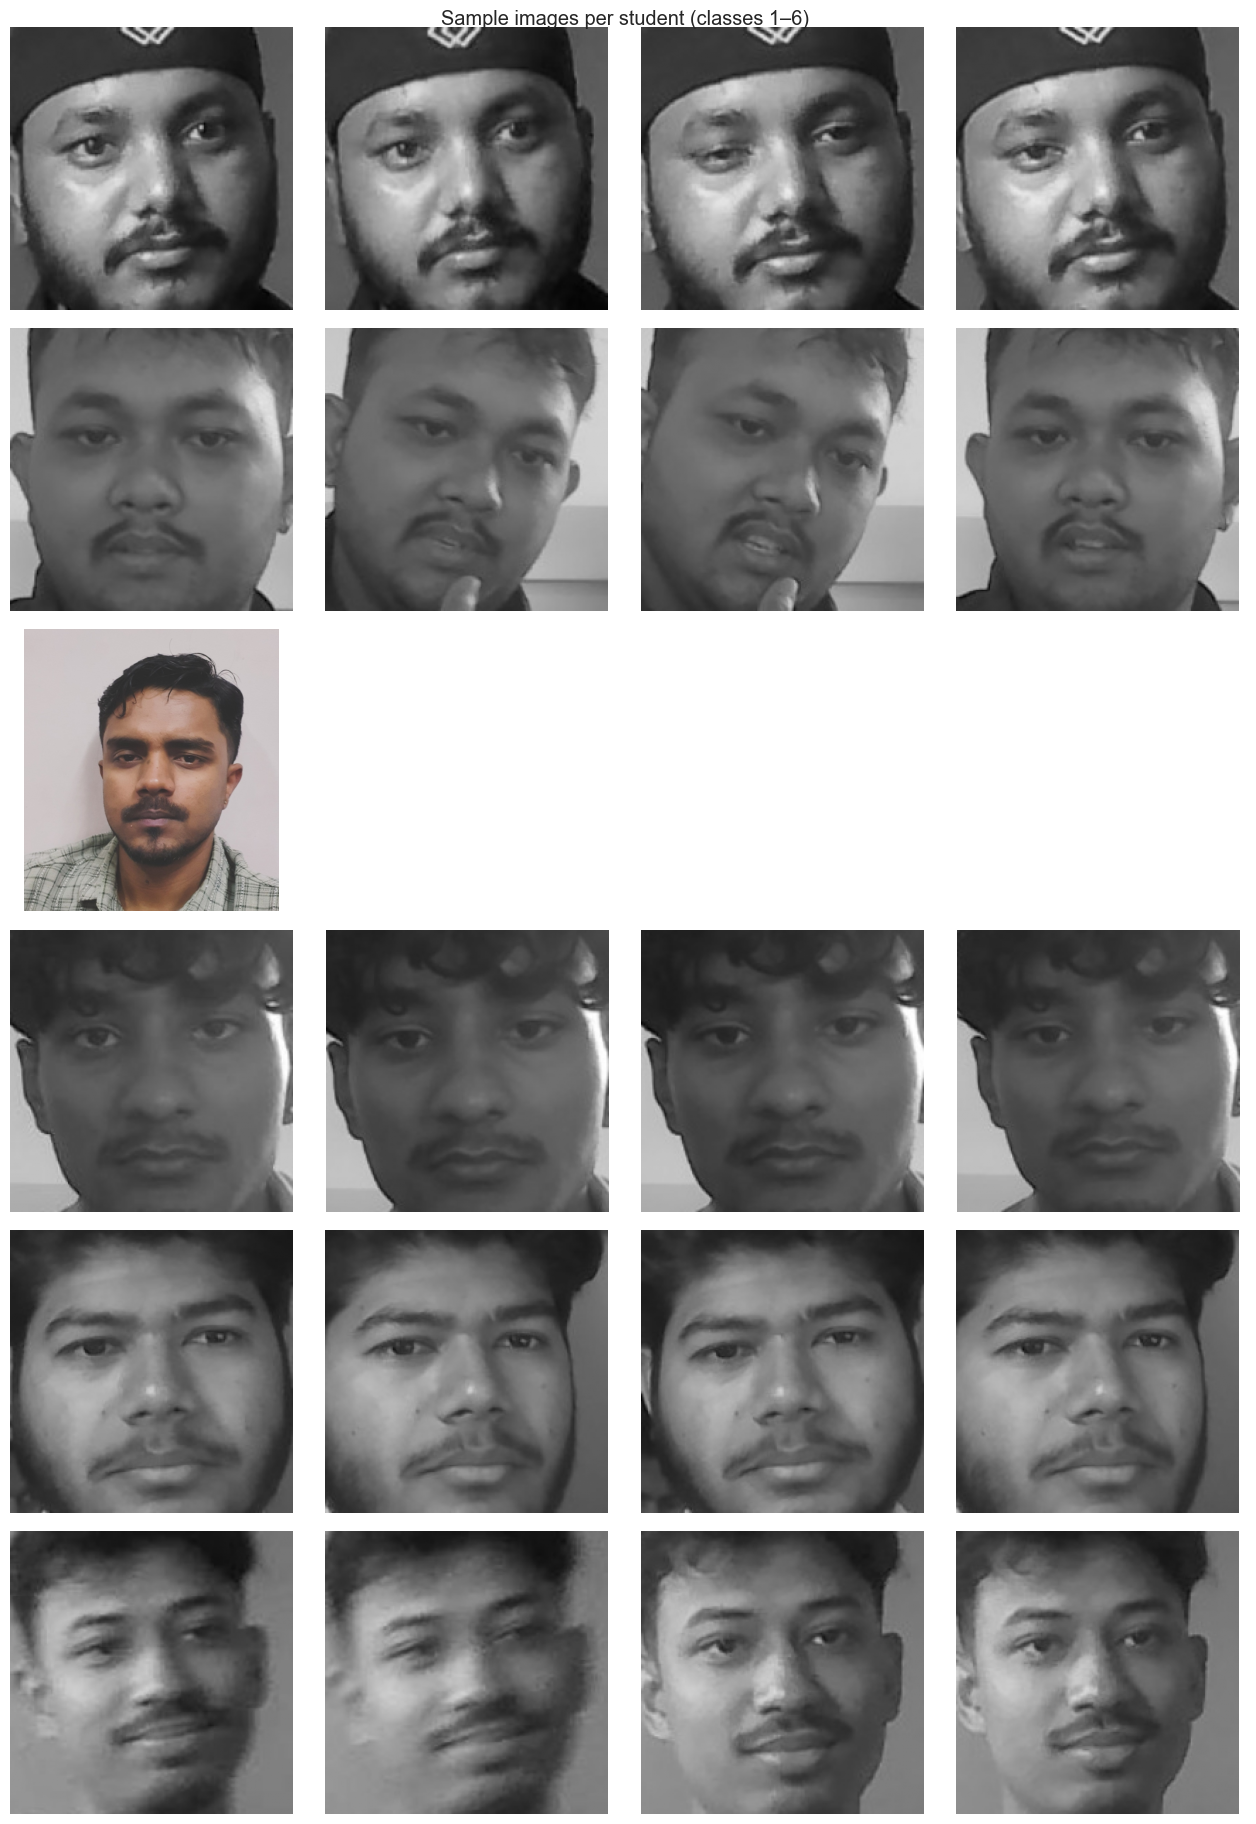

In [13]:
def show_samples_per_class(metadata, samples_per_class=4, classes_per_batch=6, seed=RANDOM_STATE):
    if metadata.empty or "class_name" not in metadata.columns:
        print("Sample grid pending dataset collection.")
        return
    rng = np.random.default_rng(seed)
    class_names = sorted(c for c in metadata["class_name"].dropna().unique() if str(c))
    for batch_start in range(0, len(class_names), classes_per_batch):
        batch = class_names[batch_start:batch_start + classes_per_batch]
        fig, axes = plt.subplots(len(batch), samples_per_class, figsize=(3.2 * samples_per_class, 3.1 * len(batch)), squeeze=False)
        for row_index, class_name in enumerate(batch):
            rows = metadata[metadata["class_name"] == class_name]
            selected = rows.iloc[rng.choice(len(rows), size=min(samples_per_class, len(rows)), replace=False)] if len(rows) else rows
            for col_index, (_, item) in enumerate(selected.iterrows()):
                ax = axes[row_index, col_index]
                try:
                    with Image.open(item["filepath"]) as image:
                        ax.imshow(image, cmap="gray" if image.mode == "L" else None, vmin=0 if image.mode == "L" else None, vmax=255 if image.mode == "L" else None)
                except (OSError, UnidentifiedImageError):
                    ax.text(0.5, 0.5, "Unreadable", ha="center", va="center")
                ax.axis("off")
            axes[row_index, 0].set_ylabel(str(class_name), rotation=0, labelpad=45, va="center")
            for col_index in range(len(selected), samples_per_class):
                axes[row_index, col_index].axis("off")
        fig.suptitle(f"Sample images per student (classes {batch_start + 1}–{batch_start + len(batch)})")
        plt.tight_layout(); plt.show(); plt.close(fig)

show_samples_per_class(vision_df)

### 3. Pixel Intensity Distribution Per Class

For a computationally manageable comparison, each readable image is converted to grayscale and resized to a small analysis size before its intensity values are summarized. Pixel values use a consistent 0–255 range. Differences can motivate later normalization or augmentation, but no issue is claimed without evidence.


,class_name,mean_intensity,std_intensity,min_intensity,max_intensity
0,Amit,91.105903,49.811062,2,238
1,Shreejal,108.328765,37.508379,30,226
2,Subhash,150.081543,53.218692,41,207
3,Susman,85.202549,39.720782,18,255
4,Udhav,98.044248,38.481852,18,225
5,Uttam,108.289282,42.597589,16,217


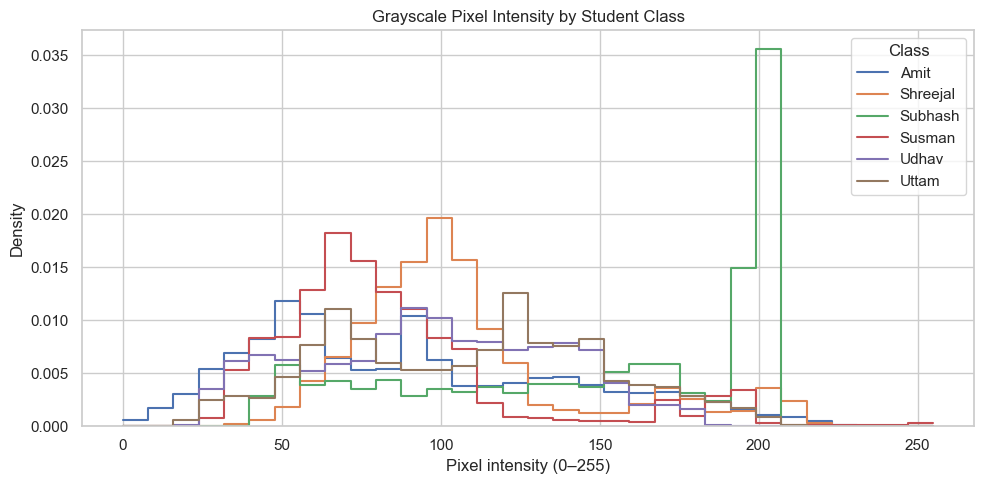

In [14]:
def intensity_statistics_by_class(metadata, max_images_per_class=50, analysis_size=(64, 64), seed=RANDOM_STATE):
    if metadata.empty:
        return pd.DataFrame(columns=["class_name", "mean_intensity", "std_intensity", "min_intensity", "max_intensity"]), {}
    rng = np.random.default_rng(seed)
    stats, values_by_class = [], {}
    for class_name, group in metadata.groupby("class_name"):
        chosen = group.iloc[rng.choice(len(group), size=min(max_images_per_class, len(group)), replace=False)]
        values = []
        for _, item in chosen.iterrows():
            try:
                with Image.open(item["filepath"]) as image:
                    values.append(np.asarray(image.convert("L").resize(analysis_size), dtype=np.uint8).ravel())
            except (OSError, UnidentifiedImageError):
                continue
        if values:
            pixels = np.concatenate(values)
            values_by_class[str(class_name)] = pixels
            stats.append({"class_name": class_name, "mean_intensity": pixels.mean(), "std_intensity": pixels.std(), "min_intensity": pixels.min(), "max_intensity": pixels.max()})
    return pd.DataFrame(stats), values_by_class

intensity_df, intensity_values = intensity_statistics_by_class(vision_df)
if intensity_df.empty:
    print("Pixel intensity analysis pending dataset collection.")
else:
    display(intensity_df)
    class_names = list(intensity_values)
    for start in range(0, len(class_names), 6):
        batch = class_names[start:start + 6]
        fig, ax = plt.subplots(figsize=(10, 5))
        for class_name in batch:
            sns.histplot(intensity_values[class_name], bins=32, binrange=(0, 255), stat="density", element="step", fill=False, label=class_name, ax=ax)
        ax.set_title("Grayscale Pixel Intensity by Student Class")
        ax.set_xlabel("Pixel intensity (0–255)"); ax.set_ylabel("Density"); ax.legend(title="Class")
        plt.tight_layout(); plt.show(); plt.close(fig)

### 4. Mean Image Per Class

A mean image requires equal spatial dimensions. Because face images may differ in size, each readable image is converted to RGB and resized to the fixed EDA-only resolution `MEAN_IMAGE_SIZE = (128, 128)` before pixel-wise averaging. This visualization resolution is not the final training resolution. Mean images can reveal alignment, background, lighting, pose, and variation patterns, but dataset-specific conclusions require real images.


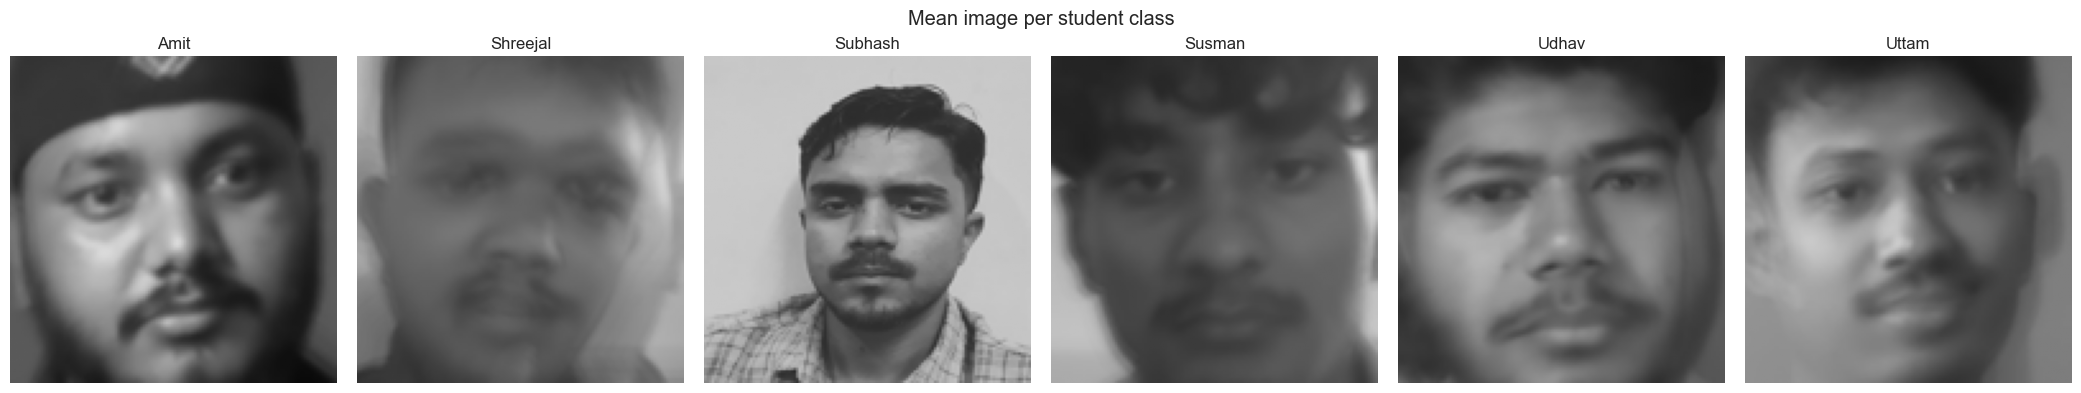

In [15]:
MEAN_IMAGE_SIZE = (128, 128)
def compute_mean_image(filepaths, size=MEAN_IMAGE_SIZE):
    arrays = []
    for filepath in filepaths:
        try:
            with Image.open(filepath) as image:
                arrays.append(np.asarray(image.convert("L").resize(size), dtype=np.float32))
        except (OSError, UnidentifiedImageError):
            continue
    return np.mean(arrays, axis=0).astype(np.uint8) if arrays else None

def show_mean_images_per_class(metadata, classes_per_batch=6):
    if metadata.empty:
        print("Mean-image analysis pending dataset collection.")
        return
    grouped = list(metadata.groupby("class_name"))
    for start in range(0, len(grouped), classes_per_batch):
        batch = grouped[start:start + classes_per_batch]
        fig, axes = plt.subplots(1, len(batch), figsize=(3.5 * len(batch), 4), squeeze=False)
        for index, (class_name, group) in enumerate(batch):
            mean_image = compute_mean_image(group["filepath"].tolist())
            if mean_image is not None:
                axes[0, index].imshow(mean_image, cmap="gray", vmin=0, vmax=255)
            else:
                axes[0, index].text(0.5, 0.5, "No readable images", ha="center", va="center")
            axes[0, index].set_title(str(class_name)); axes[0, index].axis("off")
        fig.suptitle("Mean image per student class")
        plt.tight_layout(); plt.show(); plt.close(fig)

show_mean_images_per_class(vision_df)

### Implications for Face Recognition

The Image/Vision results can guide preprocessing and model design: inconsistent dimensions may require resizing; inconsistent aspect ratios call for aspect-preserving transforms rather than uncontrolled stretching; grayscale/RGB differences require standardized channels; lighting differences may motivate brightness/contrast augmentation; low within-student variation may require more diverse collection; overly consistent backgrounds can create background shortcuts; large images may need resizing for computational efficiency; and blurry or unreadable images should be excluded or recollected. The statements above are design considerations, not claims about this dataset.


In [16]:
if valid_vision_df.empty:
    print("Face-recognition preprocessing implications are pending dataset collection.")
else:
    if valid_vision_df[["width", "height"]].nunique().max() > 1:
        print("Observed implication: image dimensions vary; resizing will be required, with aspect-preserving transforms considered.")
    if valid_vision_df["aspect_ratio"].nunique() > 1:
        print("Observed implication: aspect ratios vary; avoid uncontrolled stretching during preprocessing.")
    if valid_vision_df["channels"].nunique() > 1:
        print("Observed implication: channel counts vary; standardize all inputs to a common channel format.")
    if intensity_df.empty:
        print("No readable intensity data is available for further interpretation.")
    else:
        print("Computed intensity summaries are available above; inspect class differences before choosing normalization or augmentation.")
    print("These observations should be combined with visual inspection and capture-session metadata before changing the model pipeline.")

Observed implication: image dimensions vary; resizing will be required, with aspect-preserving transforms considered.
Observed implication: aspect ratios vary; avoid uncontrolled stretching during preprocessing.
Observed implication: channel counts vary; standardize all inputs to a common channel format.
Computed intensity summaries are available above; inspect class differences before choosing normalization or augmentation.
These observations should be combined with visual inspection and capture-session metadata before changing the model pipeline.


# TECH 405 – Neural Network Classification

## Smart Attendance System – CNN Face Classifier

**Student: Amit**

This section continues directly from the Week 2 EDA above. It reuses the same
`dataset/` directory, the same discovered image metadata (`df`), the same class
names (student identity folders), and the same `RANDOM_STATE` seed.

Plan for this part of the assignment:

1. Preprocess the same images into a CNN-ready tensor (resize, normalize, encode labels).
2. Split the data into stratified training / validation / test sets.
3. Augment the training data only.
4. Build a configurable CNN with reusable helper functions.
5. Train a baseline model and four hyperparameter experiments.
6. Select the final model on **validation** performance.
7. Evaluate the selected model on the held-out test set with a confusion matrix,
   precision, recall, and F-score.

## PyTorch, Seeds, and CUDA

The Setup cell has checked your friend's Anaconda base environment and installed missing dependencies. This cell reports the actual interpreter, PyTorch/CUDA versions, NVIDIA GPU and VRAM on **the computer running the notebook**. No GPU model, username or installation path is hardcoded.

All neural-network training, validation and inference use CUDA. If the NVIDIA GPU/driver is unavailable, execution stops with a diagnostic; there is no CPU fallback. CPU data loading, plotting and storage remain necessary and do not mean the models train on CPU.

Restart the Anaconda base kernel before Run All. The setup uses MKL's supported sequential CPU BLAS layer to avoid the duplicate OpenMP-runtime conflict found during environment verification, without disabling runtime safety checks. The friend's complete training run remains to be executed.

Seed 42, float32 precision and deterministic-kernel preferences are shared. EDA and all five CNN configurations remain unchanged in purpose, but old TensorFlow results must not be mixed with new PyTorch measurements.


In [17]:
# Dependencies and the Anaconda native-library settings were prepared by Setup.
import time
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from attendance_models import (AttendanceCNN, RowRecurrentClassifier, choose_device,
                               count_parameters, print_model_summary)
from attendance_training import (seed_everything, TrainingAugmentation, make_loader,
                                 fit_model, evaluate_model, benchmark_model, prepare_inputs)

print("Kernel Python:", sys.executable)
print("PyTorch:", torch.__version__, "| CUDA runtime:", torch.version.cuda)
DEVICE = choose_device()  # CUDA only: never fall back to CPU.
TRAIN_DEVICE = str(DEVICE)
seed_everything(RANDOM_STATE)
print("Training device:", TRAIN_DEVICE)
gpu_properties = torch.cuda.get_device_properties(DEVICE)
print("GPU:", gpu_properties.name)
print(f"VRAM: {gpu_properties.total_memory / 1024**3:.1f} GiB")
print("Precision: float32. Completed models are stored on CPU to conserve VRAM; computation uses CUDA.")


Kernel Python: c:\Users\Asus\anaconda3\python.exe
PyTorch: 2.14.1+cu126 | CUDA runtime: 12.6
Training device: cuda:0
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
VRAM: 4.0 GiB
Precision: float32. Completed models are stored on CPU to conserve VRAM; computation uses CUDA.


## 1. Preparing the Week 2 Dataset for the CNN

The same images analysed in the EDA are loaded again, this time as a numeric array.

Preprocessing decisions, and the EDA evidence behind each one:

- **Target size 128 x 128.** EDA Finding 1 showed every image is 200 x 200, so a
  square resize introduces no aspect-ratio distortion. 128 x 128 keeps enough facial
  detail while reducing the pixels per image by about 59%, which keeps the CNN
  experiments fast.
- **Grayscale, 1 channel.** EDA Finding 3 showed every image is single-channel
  grayscale, so the model input shape is `(128, 128, 1)`. There is no colour
  information to discard.
- **Normalization to 0–1.** Pixel values are divided by 255.0 so the inputs match the
  scale on which the ReLU/Adam combination trains most stably.
- **Label encoding.** The class folder names (student IDs) are encoded to integers
  0..N-1 with `LabelEncoder`, which is what `CrossEntropyLoss` expects.

NumPy source arrays remain NHWC so EDA and split logic are unchanged. The DataLoader converts CNN inputs to PyTorch NCHW `(N, 1, 128, 128)`; recurrent inputs become `(N, 128, 128)`. The loss consumes logits, while displayed confidence comes from inference softmax.

In [18]:
IMG_SIZE = (128, 128)      # CNN input height and width
IMG_CHANNELS = 1           # grayscale, confirmed by EDA Finding 3
INPUT_SHAPE = (IMG_SIZE[0], IMG_SIZE[1], IMG_CHANNELS)

# Reuse the metadata table built in the EDA section; keep only readable, labelled images.
model_df = df.dropna(subset=["width", "height"]).copy()
model_df = model_df[model_df["class_name"].astype(str) != ""].reset_index(drop=True)
# A stratified 70/15/15 split needs multiple examples of every student in
# both holdout subsets. Tiny/accidental folders cannot be valid identities.
# Show all counts before any filtering so exclusions are transparent.
MIN_IMAGES_PER_CLASS = 7
original_counts = model_df["class_name"].astype(str).value_counts()
print("Original image counts per identity:")
print(original_counts.to_string())
excluded_counts = original_counts[original_counts < MIN_IMAGES_PER_CLASS]
if not excluded_counts.empty:
    print(f"\nExcluding identities with fewer than {MIN_IMAGES_PER_CLASS} usable images:")
    print(excluded_counts.to_string())
    print("Collect more labeled images for these identities to include them.")
valid_classes = set(original_counts[original_counts >= MIN_IMAGES_PER_CLASS].index)
model_df = model_df[model_df["class_name"].astype(str).isin(valid_classes)].reset_index(drop=True)
if model_df["class_name"].nunique() < 2:
    raise ValueError("At least two classes with >=7 readable images each are required. Check dataset folders / capture more images.")
print(f"Images available for modelling: {len(model_df)} of {len(df)} discovered files")

from attendance_utils import preprocess_image

def load_image_array(filepath, size=IMG_SIZE):
    """Use the same Pillow preprocessing as saved-model and webcam inference."""
    return preprocess_image(filepath, {"height": size[0], "width": size[1]})

if model_df.empty:
    raise ValueError(f"No readable labelled images in {DATASET_DIR}.")
if len(corrupt_df) or duplicate_files:
    raise ValueError("Resolve corrupt files and exact duplicates identified in EDA before training; data is not silently dropped.")
X = np.stack([load_image_array(path) for path in model_df["filepath"]]).astype("float32")

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(model_df["class_name"].astype(str)).astype("int32")
CLASS_NAMES = [str(name) for name in label_encoder.classes_]
NUM_CLASSES = len(CLASS_NAMES)
if NUM_CLASSES < 2:
    raise ValueError("At least two enrolled identities are required.")

print(f"\nX shape            : {X.shape}  (samples, height, width, channels)")
print(f"y shape            : {y.shape}")
print(f"X dtype            : {X.dtype}")
print(f"Pixel value range  : {X.min():.3f} to {X.max():.3f}")
print(f"Number of classes  : {NUM_CLASSES}")
print(f"Class names        : {CLASS_NAMES}")

label_mapping = pd.DataFrame({
    "encoded_label": range(NUM_CLASSES),
    "class_name (student id)": CLASS_NAMES,
    "images_in_dataset": [int((y == index).sum()) for index in range(NUM_CLASSES)],
})
print("\nLabel mapping:")
display(label_mapping)

Original image counts per identity:
class_name
Amit        50
Shreejal    50
Susman      50
Udhav       50
Uttam       50
Subhash      1

Excluding identities with fewer than 7 usable images:
class_name
Subhash    1
Collect more labeled images for these identities to include them.
Images available for modelling: 250 of 251 discovered files

X shape            : (250, 128, 128, 1)  (samples, height, width, channels)
y shape            : (250,)
X dtype            : float32
Pixel value range  : 0.004 to 1.000
Number of classes  : 5
Class names        : ['Amit', 'Shreejal', 'Susman', 'Udhav', 'Uttam']

Label mapping:


,encoded_label,class_name (student id),images_in_dataset
0,0,Amit,50
1,1,Shreejal,50
2,2,Susman,50
3,3,Udhav,50
4,4,Uttam,50


## 2. Train / Validation / Test Split (70 / 15 / 15)

The split follows the plan written in EDA section 5: roughly 70% training, 15%
validation, and 15% test. Two stratified `train_test_split` calls are used so each
student keeps the same proportion in every split, and `random_state=RANDOM_STATE`
makes the split reproducible.

The **test set is touched only once**, in the final evaluation. Model selection uses
the validation set only.

Classes with fewer than seven readable images are **reported and excluded before label encoding**; this prevents an invalid stratified split. If an excluded student should be recognized, collect more images and rerun the notebook. ROC-AUC is calculated only for classes retained in the experiment.

In [19]:
# Same original stratified split, retaining shared indices for all architectures.
# Optional dataset/capture_sessions.csv: filepath (relative to dataset), session_id.
# Enable session mode only before training ALL models in a fresh run.
USE_SESSION_SPLIT = False
all_indices = np.arange(len(X))
if USE_SESSION_SPLIT:
    sessions = pd.read_csv(DATASET_DIR / "capture_sessions.csv", dtype=str)
    sessions["filepath"] = sessions["filepath"].map(lambda p: str((DATASET_DIR / p).resolve()))
    metadata = model_df.copy()
    metadata["filepath"] = metadata["filepath"].map(lambda p: str(Path(p).resolve()))
    metadata = metadata.merge(sessions[["filepath", "session_id"]],
                              on="filepath", how="left", validate="one_to_one")
    assigned = session_aware_split(metadata)
    train_indices = assigned.index[assigned["split"] == "train"].to_numpy()
    val_indices = assigned.index[assigned["split"] == "validation"].to_numpy()
    test_indices = assigned.index[assigned["split"] == "test"].to_numpy()
else:
    print("Class counts used for stratified splitting:", dict(zip(*np.unique(y, return_counts=True))))
    train_indices, holdout_indices = train_test_split(
        all_indices, test_size=0.30, stratify=y, random_state=RANDOM_STATE, shuffle=True)
    val_indices, test_indices = train_test_split(
        holdout_indices, test_size=0.50, stratify=y[holdout_indices],
        random_state=RANDOM_STATE, shuffle=True)
X_train, y_train = X[train_indices], y[train_indices]
X_val, y_val = X[val_indices], y[val_indices]
X_test, y_test = X[test_indices], y[test_indices]
for indices in (train_indices, val_indices, test_indices):
    if set(y[indices]) != set(range(NUM_CLASSES)):
        raise ValueError("Every split must contain every enrolled identity.")
assert not set(train_indices) & set(val_indices)
assert not set(train_indices) & set(test_indices)
assert not set(val_indices) & set(test_indices)
SPLIT_PROTOCOL = "session-aware within identity" if USE_SESSION_SPLIT else "stratified image-level 70/15/15"

total_images = len(X)
split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test", "Total"],
    "Images": [len(X_train), len(X_val), len(X_test), total_images],
    "Percentage": [f"{100 * len(X_train) / total_images:.1f}%",
                   f"{100 * len(X_val) / total_images:.1f}%",
                   f"{100 * len(X_test) / total_images:.1f}%",
                   "100.0%"],
})
print("Split sizes:")
display(split_summary)

distribution = pd.DataFrame(
    {"Train": [int((y_train == i).sum()) for i in range(NUM_CLASSES)],
     "Validation": [int((y_val == i).sum()) for i in range(NUM_CLASSES)],
     "Test": [int((y_test == i).sum()) for i in range(NUM_CLASSES)]},
    index=pd.Index(CLASS_NAMES, name="class_name (student id)"))
distribution["Total"] = distribution.sum(axis=1)
print(f"\nClass distribution per split ({SPLIT_PROTOCOL}):")
display(distribution)

print(f"Shapes -> X_train {X_train.shape}, X_val {X_val.shape}, X_test {X_test.shape}")
print(f"Shapes -> y_train {y_train.shape}, y_val {y_val.shape}, y_test {y_test.shape}")
assert len(X_train) + len(X_val) + len(X_test) == total_images, "Splits must sum to the dataset size"

Class counts used for stratified splitting: {np.int32(0): np.int64(50), np.int32(1): np.int64(50), np.int32(2): np.int64(50), np.int32(3): np.int64(50), np.int32(4): np.int64(50)}
Split sizes:


,Split,Images,Percentage
0,Train,175,70.0%
1,Validation,37,14.8%
2,Test,38,15.2%
3,Total,250,100.0%



Class distribution per split (stratified image-level 70/15/15):


,Train,Validation,Test,Total
class_name (student id),,,,
Amit,35,7,8,50
Shreejal,35,8,7,50
Susman,35,7,8,50
Udhav,35,7,8,50
Uttam,35,8,7,50


Shapes -> X_train (175, 128, 128, 1), X_val (37, 128, 128, 1), X_test (38, 128, 128, 1)
Shapes -> y_train (175,), y_val (37,), y_test (38,)


## 3. Dataset Limitation: Image-Level Splitting

The images in `dataset/` were captured as **consecutive webcam frames** for each
student in the historical collection, which did not record `session_id` metadata. The default is an **image-level** split. If you explicitly enabled `USE_SESSION_SPLIT`, use the actual session-based protocol printed in NN-2 when discussing the results.

Why this matters:

- Neighbouring frames from one capture burst are nearly identical: same lighting,
  same background, same pose, same clothing, and only milliseconds apart.
- A random image-level split can place frame *n* in the training set and frame
  *n + 1* in the test set. The model can then score highly by recognizing the capture
  session rather than the person's face.
- The resulting image-level test accuracy may be optimistic: it can measure re-identification of frames from a familiar session without demonstrating recognition on a different day.

A **session-based split** — whole capture sessions assigned to train, validation, or
test, as implemented by `session_aware_split()` in EDA section 5 — would give a far
more independent session-level estimate. The function requires at least three complete sessions per identity and must be used before training all models. Every accuracy reported below should be read with this
caveat in mind.

## 4. Data Augmentation (Training Data Only)

Augmentation is applied **only to the training set**. The validation and test sets are
left untouched so that the reported metrics measure performance on unmodified images.

The transformations are deliberately conservative and chosen to match real webcam
attendance conditions:

| Transformation | Setting | Reason |
|---|---|---|
| Horizontal flip | on | A mirrored face is still a valid face, so this is safe and doubles the effective pose variety. |
| Rotation | ±6% (about ±22°) | Students tilt their head slightly at the camera. |
| Translation | ±8% of height and width | The face is not always perfectly centred in the frame. |
| Zoom | ±10% | Students sit closer to or further from the webcam. |
| Brightness | ±15% | The EDA pixel-intensity histograms showed lighting differences between students. |

Augmentation is implemented as seeded PyTorch tensor operations on the GPU inside the training loop. Geometric transforms use one combined bilinear warp with border padding, followed by additive brightness and clipping. This is the same policy for all three architectures, but is not pixel-identical to the earlier Keras transforms.

In [20]:
data_augmentation = TrainingAugmentation(DEVICE, seed=RANDOM_STATE)

def make_dataset(features, labels, batch_size=32, augment=False, shuffle=False,
                 seed=RANDOM_STATE):
    """Create a Windows-safe CPU DataLoader; training augmentation runs on DEVICE."""
    loader = make_loader(features, labels, batch_size=batch_size, shuffle=shuffle,
                         seed=seed, pin_memory=DEVICE.type == "cuda")
    # The shared training loop checks this flag; evaluation never augments inputs.
    loader.apply_augmentation = bool(augment)
    return loader

print("Training only: flip, +/-21.6 degree rotation, +/-8% translation, +/-10% zoom, +/-0.15 brightness.")
print("Geometric transforms use a combined bilinear warp; validation/test inputs remain clean.")


Training only: flip, +/-21.6 degree rotation, +/-8% translation, +/-10% zoom, +/-0.15 brightness.
Geometric transforms use a combined bilinear warp; validation/test inputs remain clean.


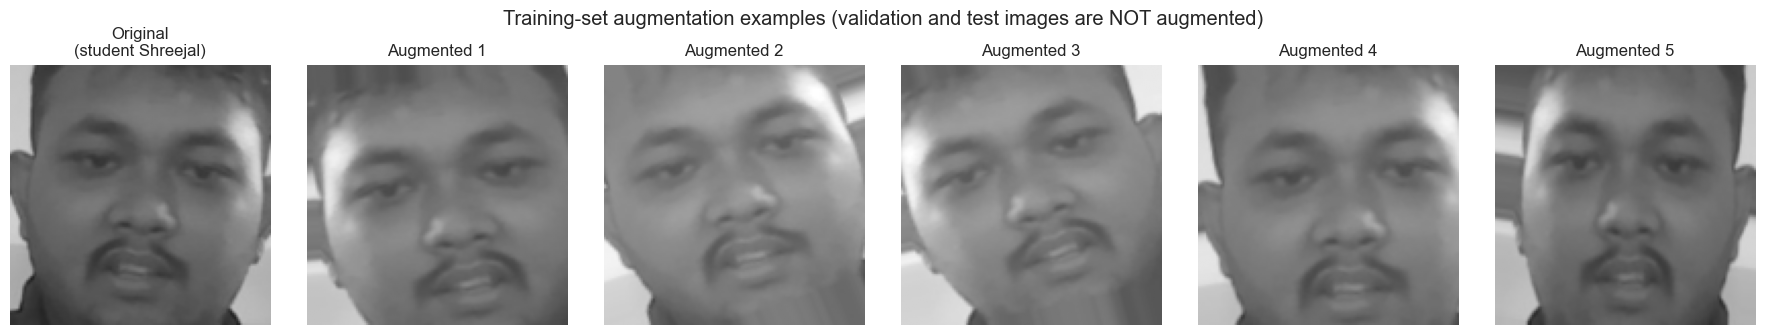

In [21]:
# Preview only training images; move the display result back to CPU.
sample_image = X_train[0:1]
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
axes[0].imshow(sample_image[0, :, :, 0], cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Original\n(student {CLASS_NAMES[y_train[0]]})")
axes[0].axis("off")
for index in range(1, 6):
    augmented = data_augmentation(prepare_inputs(sample_image, DEVICE))
    axes[index].imshow(augmented[0, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    axes[index].set_title(f"Augmented {index}")
    axes[index].axis("off")
fig.suptitle("Training-set augmentation examples (validation and test images are NOT augmented)")
plt.tight_layout(); plt.show(); plt.close(fig)


## 5 / 6. Reusable PyTorch CNN Builder and Experiment Runner

The notebook keeps `build_model()`, `run_experiment()`, `make_dataset()` and `plot_training_history()`. Shared implementations live in `attendance_models.py` and `attendance_training.py` so notebook training and local inference reconstruct the same architecture.

- **CNN:** three `Conv2d → ReLU → Conv2d → ReLU → MaxPool2d → Dropout` blocks, `AdaptiveAvgPool2d(1)`, a ReLU linear head, dropout and class logits. The default filter widths remain 32/64/128.
- **Loss:** `CrossEntropyLoss` consumes logits and integer labels. It incorporates log-softmax; do not add a softmax layer before this loss. Softmax is applied only when generating prediction scores.
- **Training:** Adam, a 120-epoch ceiling, manual minimum-validation-loss early stopping (patience 25) with restored weights, and `ReduceLROnPlateau` (factor 0.5, patience 10, minimum learning rate 1e-6).
- **CUDA:** each active model and batch move to `DEVICE`. Completed runs move to CPU to avoid retaining seven models/optimizers on the laptop GPU; evaluation temporarily moves each selected model back to `DEVICE`.
- **Timing:** synchronized fit duration includes augmentation, validation, logging and best-weight snapshots, but excludes initial model construction/transfer and the final restored-weight evaluation.
- **Recurrent reuse:** the same training loop squeezes the channel after augmentation, giving 128 spatial rows × 128 features.

All runs remain float32. The PyTorch port preserves the experimental design, not numerical equivalence with earlier TensorFlow runs. Do not compare a cached TensorFlow result against a new PyTorch run as an architecture experiment.


In [22]:
def build_model(input_shape=INPUT_SHAPE, num_classes=None, filters=(32, 64, 128),
                dropout=0.3, learning_rate=1e-3, dense_units=128, name="cnn"):
    """Build the original CNN topology in PyTorch; optimizer belongs to the runner."""
    if tuple(input_shape) != (128, 128, 1):
        raise ValueError("The supported source image shape is (128, 128, 1).")
    model = AttendanceCNN(NUM_CLASSES if num_classes is None else num_classes,
                          filters=filters, dropout=dropout, dense_units=dense_units)
    model.name = name
    return model


def run_experiment(name, learning_rate=1e-3, batch_size=32, dropout=0.3,
                   filters=(32, 64, 128), dense_units=128, epochs=120,
                   patience=25, verbose=2, model_builder=None, recurrent_units=64):
    """Run a shared GPU training loop, preserving the original result dictionary."""
    seed_everything(RANDOM_STATE)
    model = (build_model(filters=filters, dropout=dropout, dense_units=dense_units, name=name)
             if model_builder is None else model_builder(
                 units=recurrent_units, dropout=dropout, dense_units=dense_units, name=name))
    train_ds = make_dataset(X_train, y_train, batch_size=batch_size, augment=True, shuffle=True)
    val_ds = make_dataset(X_val, y_val, batch_size=batch_size, augment=False, shuffle=False)
    print(f"\nExperiment: {name} | device={DEVICE} | learning_rate={learning_rate} | "
          f"batch={batch_size} | dropout={dropout} | max_epochs={epochs}")
    fitted = fit_model(model, train_ds, val_ds, device=DEVICE, epochs=epochs,
                       patience=patience, learning_rate=learning_rate,
                       sequence=model_builder is not None, seed=RANDOM_STATE, verbose=verbose)
    hist, best_index = fitted["history"], fitted["best_index"]
    restored_accuracy, restored_loss = fitted["restored"]["accuracy"], fitted["restored"]["loss"]
    result = {
        "Experiment": name, "Learning Rate": learning_rate, "Batch Size": batch_size,
        "Dropout": dropout, "Filters": "-".join(str(f) for f in filters) if model_builder is None else "-",
        "Epoch Budget": epochs, "Patience": patience, "Dense Units": dense_units,
        "Recurrent Units": recurrent_units if model_builder is not None else None,
        "Parameters": fitted["parameters"], "Epochs Trained": len(hist["loss"]),
        "Best Epoch": best_index + 1, "Best Train Acc": float(np.max(hist["accuracy"])),
        "Train Acc @ Best Epoch": float(hist["accuracy"][best_index]),
        "Val Acc @ Best Epoch": float(restored_accuracy),
        "Restored Val Accuracy": float(restored_accuracy), "Restored Val Loss": float(restored_loss),
        "Best Val Acc": float(np.max(hist["val_accuracy"])), "Min Val Loss": float(restored_loss),
        "Train Time (s)": fitted["seconds"], "Framework": "PyTorch",
        "Training Device": TRAIN_DEVICE, "Precision": "float32",
    }
    print(f"Restored epoch {best_index+1}: val_acc={restored_accuracy:.4f}, "
          f"val_loss={restored_loss:.4f}; training={fitted['seconds']:.1f}s")
    return {"name": name, "model": model, "history": hist, "result": result}


def plot_training_history(history, title="Training history"):
    """Plot training vs validation accuracy and loss for one run."""
    epochs_range = range(1, len(history["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

    axes[0].plot(epochs_range, history["accuracy"], "o-", label="Training accuracy", markersize=3)
    axes[0].plot(epochs_range, history["val_accuracy"], "s-", label="Validation accuracy", markersize=3)
    axes[0].set_title(f"{title} – Accuracy")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
    axes[0].set_ylim(0, 1.05); axes[0].legend(loc="lower right"); axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs_range, history["loss"], "o-", label="Training loss", markersize=3)
    axes[1].plot(epochs_range, history["val_loss"], "s-", label="Validation loss", markersize=3)
    axes[1].set_title(f"{title} – Loss")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
    axes[1].legend(loc="upper right"); axes[1].grid(True, alpha=0.3)

    plt.tight_layout(); plt.show(); plt.close(fig)

print("Reusable functions defined: build_model(), run_experiment(), plot_training_history()")

Reusable functions defined: build_model(), run_experiment(), plot_training_history()


## 7. Baseline Model

The baseline configuration is the starting point every later experiment is compared
against:

| Hyperparameter | Value |
|---|---|
| Learning rate | 0.001 (Adam default) |
| Batch size | 32 |
| Dropout | 0.3 in the head, 0.15 after each conv block |
| Filters | 32 → 64 → 128 |
| Max epochs | 120 (EarlyStopping decides the real stopping point) |
| Callbacks | EarlyStopping (patience 25, restores best weights), ReduceLROnPlateau (factor 0.5, patience 10) |

`print_model_summary(model)` is printed first so the architecture and parameter count are
available for the report.

In [23]:
baseline_model = build_model(filters=(32, 64, 128), dropout=0.3, learning_rate=1e-3,
                             name="baseline_cnn")
print_model_summary(baseline_model)

AttendanceCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.15, inplace=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout(p=0.15, inplace=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU()
    (14): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU()
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (17): Dropout(p=0.15, inplace=False)
  )
  (head): Sequential(
    (

In [24]:
EPOCHS = 120
experiments = {}

experiments["Baseline"] = run_experiment(
    "Baseline", learning_rate=1e-3, batch_size=32, dropout=0.3,
    filters=(32, 64, 128), epochs=EPOCHS)


Experiment: Baseline | device=cuda:0 | learning_rate=0.001 | batch=32 | dropout=0.3 | max_epochs=120
Training parameter device: cuda:0
Epoch 1/120 | loss 1.6114 acc 0.1943 | val_loss 1.6129 val_acc 0.1892 | lr 0.001
Epoch 2/120 | loss 1.6106 acc 0.2114 | val_loss 1.6125 val_acc 0.1892 | lr 0.001
Epoch 3/120 | loss 1.6112 acc 0.1943 | val_loss 1.6113 val_acc 0.1892 | lr 0.001
Epoch 4/120 | loss 1.6109 acc 0.1714 | val_loss 1.6119 val_acc 0.2432 | lr 0.001
Epoch 5/120 | loss 1.6081 acc 0.2286 | val_loss 1.6072 val_acc 0.1892 | lr 0.001
Epoch 6/120 | loss 1.6076 acc 0.2229 | val_loss 1.5987 val_acc 0.4054 | lr 0.001
Epoch 7/120 | loss 1.5959 acc 0.2629 | val_loss 1.5608 val_acc 0.3243 | lr 0.001
Epoch 8/120 | loss 1.5531 acc 0.2914 | val_loss 1.4951 val_acc 0.2432 | lr 0.001
Epoch 9/120 | loss 1.5761 acc 0.2400 | val_loss 1.4433 val_acc 0.3514 | lr 0.001
Epoch 10/120 | loss 1.5319 acc 0.3314 | val_loss 1.5055 val_acc 0.6216 | lr 0.001
Epoch 11/120 | loss 1.5082 acc 0.3257 | val_loss 1.42

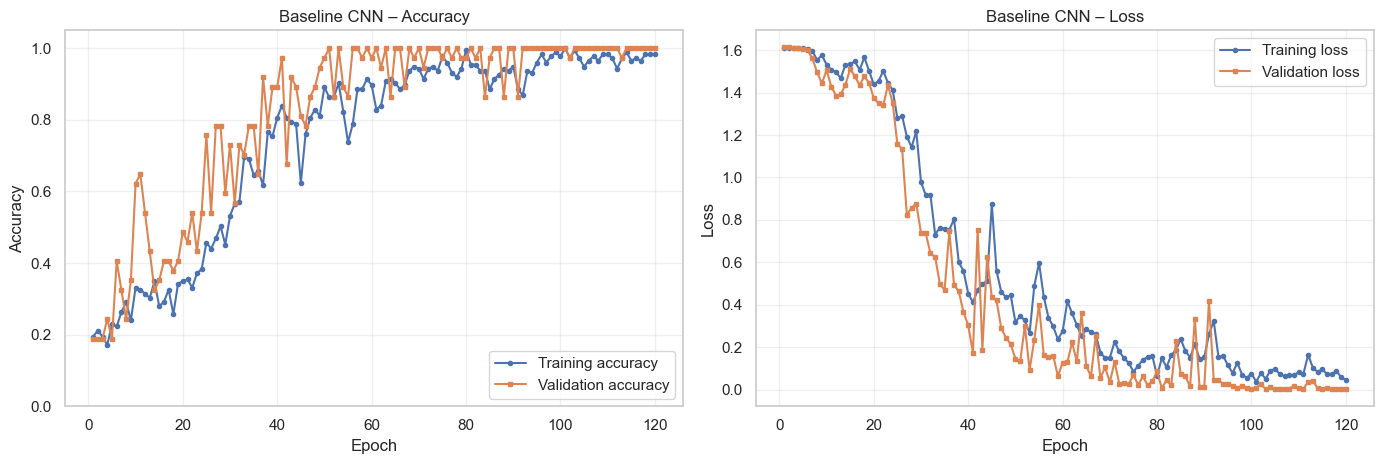

In [25]:
plot_training_history(experiments["Baseline"]["history"], title="Baseline CNN")

## 8. Hyperparameter Experiments

Four further configurations are trained. Each changes **one** factor at a time
against the baseline. Differences in validation performance are associated with
that change in this run, but do not alone establish a causal or statistically reliable effect:

| Experiment | Learning Rate | Batch Size | Dropout | Filters | What it tests |
|---|---:|---:|---:|---|---|
| Baseline | 0.001 | 32 | 0.3 | 32-64-128 | Reference configuration |
| Lower LR | 0.0001 | 32 | 0.3 | 32-64-128 | Does a 10× smaller step size train more stably, or just more slowly? |
| Higher Dropout | 0.001 | 32 | 0.5 | 32-64-128 | Does stronger regularization reduce overfitting on 175 training images? |
| Larger Model | 0.001 | 32 | 0.3 | 64-128-256 | Does more capacity help, or does it overfit the small dataset? |
| Larger Batch | 0.001 | 64 | 0.3 | 32-64-128 | Do fewer, smoother gradient updates per epoch help or hurt? |

All five runs use the same architecture family, the same 120-epoch budget, and the same
callbacks. Every run starts from the same seed and uses the same augmented training pipeline and
the same unaugmented validation set, so the comparison is fair.

In [26]:
experiments["Lower LR"] = run_experiment(
    "Lower LR", learning_rate=1e-4, batch_size=32, dropout=0.3,
    filters=(32, 64, 128), epochs=EPOCHS)


Experiment: Lower LR | device=cuda:0 | learning_rate=0.0001 | batch=32 | dropout=0.3 | max_epochs=120
Training parameter device: cuda:0
Epoch 1/120 | loss 1.6108 acc 0.2114 | val_loss 1.6138 val_acc 0.1892 | lr 0.0001
Epoch 2/120 | loss 1.6107 acc 0.1657 | val_loss 1.6137 val_acc 0.1892 | lr 0.0001
Epoch 3/120 | loss 1.6115 acc 0.2114 | val_loss 1.6134 val_acc 0.1892 | lr 0.0001
Epoch 4/120 | loss 1.6109 acc 0.1771 | val_loss 1.6134 val_acc 0.1892 | lr 0.0001
Epoch 5/120 | loss 1.6094 acc 0.2286 | val_loss 1.6132 val_acc 0.1892 | lr 0.0001
Epoch 6/120 | loss 1.6106 acc 0.1829 | val_loss 1.6130 val_acc 0.1892 | lr 0.0001
Epoch 7/120 | loss 1.6100 acc 0.2171 | val_loss 1.6127 val_acc 0.1892 | lr 0.0001
Epoch 8/120 | loss 1.6089 acc 0.2171 | val_loss 1.6123 val_acc 0.1892 | lr 0.0001
Epoch 9/120 | loss 1.6088 acc 0.2400 | val_loss 1.6118 val_acc 0.1892 | lr 0.0001
Epoch 10/120 | loss 1.6092 acc 0.1829 | val_loss 1.6109 val_acc 0.1892 | lr 0.0001
Epoch 11/120 | loss 1.6093 acc 0.2114 | va

In [27]:
experiments["Higher Dropout"] = run_experiment(
    "Higher Dropout", learning_rate=1e-3, batch_size=32, dropout=0.5,
    filters=(32, 64, 128), epochs=EPOCHS)


Experiment: Higher Dropout | device=cuda:0 | learning_rate=0.001 | batch=32 | dropout=0.5 | max_epochs=120
Training parameter device: cuda:0
Epoch 1/120 | loss 1.6115 acc 0.1657 | val_loss 1.6128 val_acc 0.1892 | lr 0.001
Epoch 2/120 | loss 1.6123 acc 0.1886 | val_loss 1.6123 val_acc 0.1892 | lr 0.001
Epoch 3/120 | loss 1.6108 acc 0.1829 | val_loss 1.6116 val_acc 0.1892 | lr 0.001
Epoch 4/120 | loss 1.6101 acc 0.2057 | val_loss 1.6119 val_acc 0.1892 | lr 0.001
Epoch 5/120 | loss 1.6090 acc 0.2343 | val_loss 1.6114 val_acc 0.1892 | lr 0.001
Epoch 6/120 | loss 1.6114 acc 0.1714 | val_loss 1.6112 val_acc 0.1892 | lr 0.001
Epoch 7/120 | loss 1.6089 acc 0.2343 | val_loss 1.6105 val_acc 0.1892 | lr 0.001
Epoch 8/120 | loss 1.6084 acc 0.2114 | val_loss 1.6086 val_acc 0.1892 | lr 0.001
Epoch 9/120 | loss 1.6058 acc 0.2686 | val_loss 1.6023 val_acc 0.3784 | lr 0.001
Epoch 10/120 | loss 1.5984 acc 0.2514 | val_loss 1.5696 val_acc 0.3784 | lr 0.001
Epoch 11/120 | loss 1.5718 acc 0.2800 | val_los

In [28]:
experiments["Larger Model"] = run_experiment(
    "Larger Model", learning_rate=1e-3, batch_size=32, dropout=0.3,
    filters=(64, 128, 256), epochs=EPOCHS)


Experiment: Larger Model | device=cuda:0 | learning_rate=0.001 | batch=32 | dropout=0.3 | max_epochs=120
Training parameter device: cuda:0
Epoch 1/120 | loss 1.6133 acc 0.1600 | val_loss 1.6088 val_acc 0.1892 | lr 0.001
Epoch 2/120 | loss 1.6108 acc 0.1886 | val_loss 1.6088 val_acc 0.3243 | lr 0.001
Epoch 3/120 | loss 1.6091 acc 0.1943 | val_loss 1.6032 val_acc 0.1351 | lr 0.001
Epoch 4/120 | loss 1.6156 acc 0.2114 | val_loss 1.5992 val_acc 0.1892 | lr 0.001
Epoch 5/120 | loss 1.6062 acc 0.1943 | val_loss 1.6080 val_acc 0.2162 | lr 0.001
Epoch 6/120 | loss 1.6095 acc 0.2057 | val_loss 1.6074 val_acc 0.2162 | lr 0.001
Epoch 7/120 | loss 1.6084 acc 0.2057 | val_loss 1.6062 val_acc 0.2162 | lr 0.001
Epoch 8/120 | loss 1.6082 acc 0.2000 | val_loss 1.6059 val_acc 0.2162 | lr 0.001
Epoch 9/120 | loss 1.6071 acc 0.2514 | val_loss 1.6024 val_acc 0.2162 | lr 0.001
Epoch 10/120 | loss 1.6026 acc 0.2686 | val_loss 1.5908 val_acc 0.4054 | lr 0.001
Epoch 11/120 | loss 1.5817 acc 0.3029 | val_loss 

In [29]:
experiments["Larger Batch"] = run_experiment(
    "Larger Batch", learning_rate=1e-3, batch_size=64, dropout=0.3,
    filters=(32, 64, 128), epochs=EPOCHS)


Experiment: Larger Batch | device=cuda:0 | learning_rate=0.001 | batch=64 | dropout=0.3 | max_epochs=120
Training parameter device: cuda:0
Epoch 1/120 | loss 1.6105 acc 0.1771 | val_loss 1.6142 val_acc 0.1892 | lr 0.001
Epoch 2/120 | loss 1.6115 acc 0.1943 | val_loss 1.6137 val_acc 0.1892 | lr 0.001
Epoch 3/120 | loss 1.6090 acc 0.2686 | val_loss 1.6122 val_acc 0.1892 | lr 0.001
Epoch 4/120 | loss 1.6121 acc 0.1714 | val_loss 1.6118 val_acc 0.1892 | lr 0.001
Epoch 5/120 | loss 1.6093 acc 0.1429 | val_loss 1.6098 val_acc 0.1892 | lr 0.001
Epoch 6/120 | loss 1.6064 acc 0.2229 | val_loss 1.6035 val_acc 0.1892 | lr 0.001
Epoch 7/120 | loss 1.6033 acc 0.1886 | val_loss 1.5974 val_acc 0.2432 | lr 0.001
Epoch 8/120 | loss 1.5956 acc 0.2514 | val_loss 1.5921 val_acc 0.2703 | lr 0.001
Epoch 9/120 | loss 1.5958 acc 0.2000 | val_loss 1.5909 val_acc 0.2162 | lr 0.001
Epoch 10/120 | loss 1.5972 acc 0.2171 | val_loss 1.5709 val_acc 0.2162 | lr 0.001
Epoch 11/120 | loss 1.5831 acc 0.2571 | val_loss 

## 9. Experiment Comparison

The table below collects every configuration and its results.

One column needs explaining. **`Best Val Acc`** is the highest validation accuracy
reached at *any* epoch, but that peak can be a one-epoch fluctuation — the validation
set holds only 37 images, so a single image is worth 2.7 percentage points.
EarlyStopping restores the weights from the **lowest validation loss** epoch, so the
model that is actually kept is described by **`Val Acc @ Best Epoch`** and
**`Min Val Loss`**. Those are the columns used for selection; `Best Val Acc` is still
reported for completeness, and `Best Train Acc` / `Train Acc @ Best Epoch` make the
train-validation gap (the overfitting signal) visible.

In [30]:
comparison_df = pd.DataFrame([run["result"] for run in experiments.values()])
comparison_df = comparison_df[["Experiment", "Learning Rate", "Batch Size", "Dropout",
                               "Filters", "Parameters", "Epochs Trained", "Best Epoch",
                               "Best Train Acc", "Train Acc @ Best Epoch",
                               "Val Acc @ Best Epoch", "Best Val Acc", "Min Val Loss",
                               "Train Time (s)"]]
display(comparison_df.style.format({
    "Learning Rate": "{:.4f}", "Dropout": "{:.2f}", "Parameters": "{:,}",
    "Best Train Acc": "{:.4f}", "Train Acc @ Best Epoch": "{:.4f}",
    "Val Acc @ Best Epoch": "{:.4f}", "Best Val Acc": "{:.4f}",
    "Min Val Loss": "{:.4f}", "Train Time (s)": "{:.1f}",
}).background_gradient(subset=["Val Acc @ Best Epoch"], cmap="Greens")
 .set_caption("Hyperparameter experiment comparison"))

,Experiment,Learning Rate,Batch Size,Dropout,Filters,Parameters,Epochs Trained,Best Epoch,Best Train Acc,Train Acc @ Best Epoch,Val Acc @ Best Epoch,Best Val Acc,Min Val Loss,Train Time (s)
0,Baseline,0.0010,32,0.30,32-64-128,"303,589",120,103,1.0000,0.9943,1.0000,1.0000,0.0025,200.2
1,Lower LR,0.0001,32,0.30,32-64-128,"303,589",120,119,0.9429,0.9429,1.0000,1.0000,0.0739,192.3
2,Higher Dropout,0.0010,32,0.50,32-64-128,"303,589",120,119,0.9886,0.9886,1.0000,1.0000,0.0036,110.6
3,Larger Model,0.0010,32,0.30,64-128-256,"1,177,797",120,99,1.0000,0.9771,1.0000,1.0000,0.0014,100.0
4,Larger Batch,0.0010,64,0.30,32-64-128,"303,589",110,85,0.9943,0.9600,1.0000,1.0000,0.0013,30.3


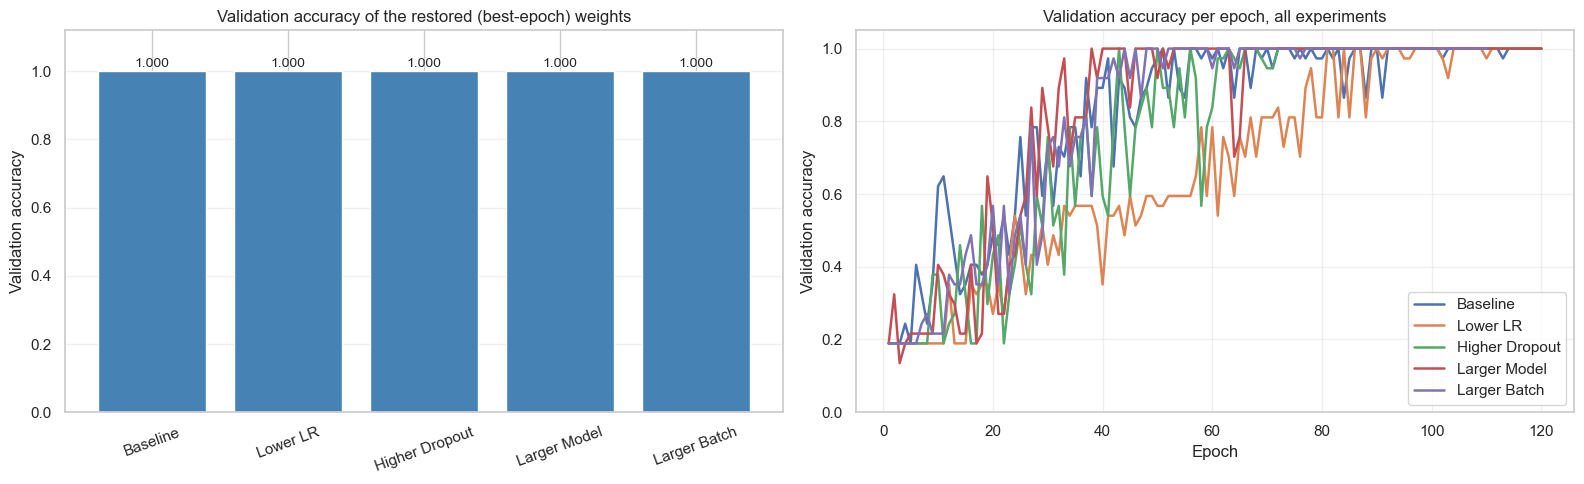

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

order = comparison_df.sort_values("Val Acc @ Best Epoch", ascending=False)
bars = axes[0].bar(order["Experiment"], order["Val Acc @ Best Epoch"], color="steelblue")
for bar, value in zip(bars, order["Val Acc @ Best Epoch"]):
    axes[0].text(bar.get_x() + bar.get_width() / 2, value + 0.012, f"{value:.3f}",
                 ha="center", fontsize=10)
axes[0].set_title("Validation accuracy of the restored (best-epoch) weights")
axes[0].set_ylabel("Validation accuracy"); axes[0].set_ylim(0, 1.12)
axes[0].tick_params(axis="x", rotation=20); axes[0].grid(True, axis="y", alpha=0.3)

for name, run in experiments.items():
    axes[1].plot(range(1, len(run["history"]["val_accuracy"]) + 1),
                 run["history"]["val_accuracy"], label=name, linewidth=1.8)
axes[1].set_title("Validation accuracy per epoch, all experiments")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation accuracy")
axes[1].set_ylim(0, 1.05); axes[1].legend(loc="lower right"); axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show(); plt.close(fig)

## 10. Selecting the Final Model

Selection uses **validation performance only** — the test set is not consulted, which
would otherwise leak test information into the model choice and inflate the final
reported metrics.

The rule applied below is:

1. Take the highest **`Val Acc @ Best Epoch`** — the validation accuracy of the
   weights EarlyStopping actually restored, not a transient peak from some other epoch.
2. If several experiments tie on validation accuracy (likely here, because the
   validation set holds only 37 images, so a single image is worth about 2.7
   percentage points), break the tie with the **lowest `Min Val Loss`**. Lower
   validation loss is a secondary criterion; it does not prove score calibration.
3. Exact ties prefer fewer parameters, then the experiment name for deterministic ordering.

In [32]:
ranked = comparison_df.sort_values(["Val Acc @ Best Epoch", "Min Val Loss", "Parameters", "Experiment"],
                                   ascending=[False, True, True, True]).reset_index(drop=True)
print("Experiments ranked by the validation accuracy of their restored weights, "
      "then by validation loss:")
display(ranked[["Experiment", "Val Acc @ Best Epoch", "Min Val Loss", "Best Val Acc",
                "Train Acc @ Best Epoch", "Epochs Trained", "Best Epoch"]])

top_accuracy = ranked.loc[0, "Val Acc @ Best Epoch"]
tied = ranked[np.isclose(ranked["Val Acc @ Best Epoch"], top_accuracy)]
SELECTED_NAME = ranked.loc[0, "Experiment"]
selected_run = experiments[SELECTED_NAME]
selected_model = selected_run["model"]
selected_config = selected_run["result"]

if len(tied) > 1:
    print(f"\n{len(tied)} experiments tied on validation accuracy ({top_accuracy:.4f}): "
          f"{list(tied['Experiment'])}")
    print(f"Tie broken by the lowest validation loss -> '{SELECTED_NAME}' "
          f"(val_loss {selected_config['Min Val Loss']:.4f}).")
else:
    print(f"\n'{SELECTED_NAME}' has the highest validation accuracy outright "
          f"({top_accuracy:.4f}); no tie-break was needed.")

print(f"\nSELECTED MODEL: {SELECTED_NAME}")
display(pd.DataFrame({"Setting": list(selected_config.keys()),
                      "Value": [str(v) for v in selected_config.values()]}))
print_model_summary(selected_model)

Experiments ranked by the validation accuracy of their restored weights, then by validation loss:


,Experiment,Val Acc @ Best Epoch,Min Val Loss,Best Val Acc,Train Acc @ Best Epoch,Epochs Trained,Best Epoch
0,Larger Batch,1.0,0.001335,1.0,0.960000,110,85
1,Larger Model,1.0,0.001361,1.0,0.977143,120,99
2,Baseline,1.0,0.002502,1.0,0.994286,120,103
3,Higher Dropout,1.0,0.003560,1.0,0.988571,120,119
4,Lower LR,1.0,0.073927,1.0,0.942857,120,119



5 experiments tied on validation accuracy (1.0000): ['Larger Batch', 'Larger Model', 'Baseline', 'Higher Dropout', 'Lower LR']
Tie broken by the lowest validation loss -> 'Larger Batch' (val_loss 0.0013).

SELECTED MODEL: Larger Batch


,Setting,Value
0,Experiment,Larger Batch
1,Learning Rate,0.001
2,Batch Size,64
3,Dropout,0.3
4,Filters,32-64-128
5,Epoch Budget,120
6,Patience,25
7,Dense Units,128
8,Recurrent Units,None
9,Parameters,303589


AttendanceCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.15, inplace=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout(p=0.15, inplace=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU()
    (14): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU()
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (17): Dropout(p=0.15, inplace=False)
  )
  (head): Sequential(
    (

## 10A. Three-Model Comparison: Controls Fixed Before Testing

Part A above compares **CNN hyperparameters**. Part B below compares the selected **CNN, SimpleRNN, and LSTM** configurations. All use the same arrays, encoded identities, seed 42, normalization, train-only augmentation, epoch ceiling, early stopping, and learning-rate schedule. Rows are **spatial sequences**, not temporal observations.

The recurrent baselines use the validation-selected CNN's batch size, learning rate, head dropout, and dense width. This makes training controls consistent with the selected CNN, including when Larger Batch wins. Hidden width is fixed at 64. Optional recurrent variants are disabled by default; configure them here before viewing any test results. CNN has a larger search budget, so this is a comparison of selected configurations, not a claim of equal tuning effort or matched parameter counts.

Deployment policy, fixed now: retain the validation-selected CNN as the intended spatial-image demonstration candidate. Use restored validation accuracy then validation loss for CNN selection (NN-10); document parameter count and validation-input latency below. No test score changes this choice. The heuristic score threshold is 0.90 with eight consistent frames and explicit consent/confirmation; it is not tuned against this test set.

Existing stored notebook outputs are historical. Newly added cells have never been executed. Restart and run top to bottom to produce a coherent new run. The default protocol remains stratified image-level 70/15/15; enabling the optional session split requires at least three sessions per identity and rerunning all models.


In [33]:
def build_recurrent_model(kind, units=64, dropout=0.3, learning_rate=1e-3,
                          dense_units=128, name=None):
    """Genuine nn.RNN (tanh) or nn.LSTM over spatial image rows."""
    model = RowRecurrentClassifier(kind, NUM_CLASSES, input_features=IMG_SIZE[1],
                                   units=units, dropout=dropout, dense_units=dense_units)
    model.name = name or kind.lower()
    return model

def build_rnn_model(**kwargs):
    return build_recurrent_model("RNN", **kwargs)

def build_lstm_model(**kwargs):
    return build_recurrent_model("LSTM", **kwargs)

COMMON_RECURRENT = dict(
    learning_rate=float(selected_config["Learning Rate"]),
    batch_size=int(selected_config["Batch Size"]),
    dropout=float(selected_config["Dropout"]),
    dense_units=int(selected_config["Dense Units"]),
    epochs=EPOCHS, patience=int(selected_config["Patience"]),
    recurrent_units=64,
)
# Optional examples: [{"recurrent_units": 128}, {"dropout": 0.5}]
# Every extra run uses the same split; select only with validation performance.
EXTRA_RECURRENT_CONFIGS = []

def train_rnn_model(name="RNN Baseline", **overrides):
    settings = {**COMMON_RECURRENT, **overrides}
    return run_experiment(name, model_builder=build_rnn_model, **settings)

def train_lstm_model(name="LSTM Baseline", **overrides):
    settings = {**COMMON_RECURRENT, **overrides}
    return run_experiment(name, model_builder=build_lstm_model, **settings)

print("Common recurrent settings:", COMMON_RECURRENT)
print_model_summary(build_rnn_model())
print_model_summary(build_lstm_model())


Common recurrent settings: {'learning_rate': 0.001, 'batch_size': 64, 'dropout': 0.3, 'dense_units': 128, 'epochs': 120, 'patience': 25, 'recurrent_units': 64}
RowRecurrentClassifier(
  (recurrent): RNN(128, 64, batch_first=True)
  (head): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=64, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=5, bias=True)
  )
)
Parameters: 21,381
Stored parameter device: cpu (the active training device is printed by the runner)
RowRecurrentClassifier(
  (recurrent): LSTM(128, 64, batch_first=True)
  (head): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=64, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=5, bias=True)
  )
)
Parameters: 58,629
Stored parameter device: cpu (the active training device is printed by the runner)


## 10B. SimpleRNN Training

A genuine SimpleRNN with 64 units compresses 128 image rows into a hidden state, followed by dropout, a ReLU dense head, and class softmax. Training reuses `run_experiment()` and `make_dataset()`; squeezing happens after image augmentation.


In [34]:
rnn_experiments = {"RNN Baseline": train_rnn_model()}
for index, settings in enumerate(EXTRA_RECURRENT_CONFIGS, start=1):
    name = f"RNN Variant {index}"
    rnn_experiments[name] = train_rnn_model(name, **settings)



Experiment: RNN Baseline | device=cuda:0 | learning_rate=0.001 | batch=64 | dropout=0.3 | max_epochs=120
Training parameter device: cuda:0
Epoch 1/120 | loss 1.6163 acc 0.1657 | val_loss 1.5829 val_acc 0.4324 | lr 0.001
Epoch 2/120 | loss 1.5750 acc 0.2457 | val_loss 1.5568 val_acc 0.2432 | lr 0.001
Epoch 3/120 | loss 1.5560 acc 0.2800 | val_loss 1.5266 val_acc 0.2973 | lr 0.001
Epoch 4/120 | loss 1.5385 acc 0.3257 | val_loss 1.4814 val_acc 0.3784 | lr 0.001
Epoch 5/120 | loss 1.4915 acc 0.4629 | val_loss 1.4155 val_acc 0.5135 | lr 0.001
Epoch 6/120 | loss 1.4346 acc 0.4171 | val_loss 1.3260 val_acc 0.7838 | lr 0.001
Epoch 7/120 | loss 1.3725 acc 0.4343 | val_loss 1.2155 val_acc 0.6757 | lr 0.001
Epoch 8/120 | loss 1.2869 acc 0.4857 | val_loss 1.1267 val_acc 0.5676 | lr 0.001
Epoch 9/120 | loss 1.1624 acc 0.4800 | val_loss 1.0895 val_acc 0.5405 | lr 0.001
Epoch 10/120 | loss 1.3517 acc 0.3943 | val_loss 1.0360 val_acc 0.5676 | lr 0.001
Epoch 11/120 | loss 1.1304 acc 0.4857 | val_loss 

## 10C. LSTM Training

A genuine LSTM uses input, forget, and output gates to retain information across spatial rows. Gated memory adds parameters and computation, but does not turn the still image into a video sequence. The data, controls, and callbacks match the SimpleRNN baseline.


In [35]:
lstm_experiments = {"LSTM Baseline": train_lstm_model()}
for index, settings in enumerate(EXTRA_RECURRENT_CONFIGS, start=1):
    name = f"LSTM Variant {index}"
    lstm_experiments[name] = train_lstm_model(name, **settings)

def select_validation_run(runs):
    return sorted(runs.values(), key=lambda run: (
        -run["result"]["Restored Val Accuracy"],
        run["result"]["Restored Val Loss"],
        run["result"]["Parameters"], run["name"]))[0]

architecture_runs = {
    "CNN": selected_run,
    "RNN": select_validation_run(rnn_experiments),
    "LSTM": select_validation_run(lstm_experiments),
}
validation_comparison = pd.DataFrame([
    {"Model": name, **run["result"]} for name, run in architecture_runs.items()
])
display(validation_comparison)
for name, run in architecture_runs.items():
    print(name, "selected using validation only:", run["name"])
    print_model_summary(run["model"])



Experiment: LSTM Baseline | device=cuda:0 | learning_rate=0.001 | batch=64 | dropout=0.3 | max_epochs=120
Training parameter device: cuda:0
Epoch 1/120 | loss 1.6099 acc 0.2514 | val_loss 1.6020 val_acc 0.3784 | lr 0.001
Epoch 2/120 | loss 1.5922 acc 0.3143 | val_loss 1.5815 val_acc 0.3243 | lr 0.001
Epoch 3/120 | loss 1.5721 acc 0.3086 | val_loss 1.5505 val_acc 0.3243 | lr 0.001
Epoch 4/120 | loss 1.5464 acc 0.3829 | val_loss 1.5029 val_acc 0.5405 | lr 0.001
Epoch 5/120 | loss 1.5080 acc 0.3771 | val_loss 1.4434 val_acc 0.4865 | lr 0.001
Epoch 6/120 | loss 1.4464 acc 0.4343 | val_loss 1.3644 val_acc 0.5405 | lr 0.001
Epoch 7/120 | loss 1.3806 acc 0.4229 | val_loss 1.2725 val_acc 0.4324 | lr 0.001
Epoch 8/120 | loss 1.3084 acc 0.4000 | val_loss 1.2098 val_acc 0.3784 | lr 0.001
Epoch 9/120 | loss 1.2320 acc 0.4171 | val_loss 1.1482 val_acc 0.4324 | lr 0.001
Epoch 10/120 | loss 1.1857 acc 0.4343 | val_loss 1.0446 val_acc 0.5135 | lr 0.001
Epoch 11/120 | loss 1.1080 acc 0.4457 | val_loss

,Model,Experiment,Learning Rate,Batch Size,Dropout,Filters,Epoch Budget,Patience,Dense Units,Recurrent Units,...,Train Acc @ Best Epoch,Val Acc @ Best Epoch,Restored Val Accuracy,Restored Val Loss,Best Val Acc,Min Val Loss,Train Time (s),Framework,Training Device,Precision
0,CNN,Larger Batch,0.001,64,0.3,32-64-128,120,25,128,NaN,...,0.960000,1.000000,1.000000,0.001335,1.0,0.001335,30.332142,PyTorch,cuda:0,float32
1,RNN,RNN Baseline,0.001,64,0.3,-,120,25,128,64.0,...,0.617143,0.945946,0.945946,0.433153,1.0,0.433153,3.322912,PyTorch,cuda:0,float32
2,LSTM,LSTM Baseline,0.001,64,0.3,-,120,25,128,64.0,...,0.685714,1.000000,1.000000,0.265528,1.0,0.265528,2.605237,PyTorch,cuda:0,float32


CNN selected using validation only: Larger Batch
AttendanceCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.15, inplace=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout(p=0.15, inplace=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU()
    (14): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU()
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (17): Dropout(p=0.1

## 10D. Deployment Decision and Timing Protocol

CNN is the predefined deployment family because convolution represents local 2D patterns directly. Validation chooses its configuration, with parameter count resolving exact residual ties. Complexity and measured latency document practicality; no field-reliability standard is asserted.

Timing includes an eager PyTorch forward call and softmax in float32. CUDA is synchronized before and after each measured call. Inputs are already on the selected device, so CPU/GPU transfer, image loading, detection, preprocessing, UI and disk I/O are excluded. All architectures use identical warm-up/repetition counts and the same device. Batch-one latency is distinct from batched throughput. Validation inputs are used, keeping efficiency decisions independent of the final test set.


In [36]:
import platform
import json
from datetime import datetime, timezone
from attendance_utils import DEFAULT_PREPROCESSING

TIMING_REPETITIONS = 20
TIMING_WARMUPS = 3
TIMING_BATCH_SIZE = min(32, len(X_val))
hardware_metadata = {
    "platform": platform.platform(), "processor": platform.processor(),
    "python": platform.python_version(), "pytorch": str(torch.__version__),
    "cuda_runtime": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
    "device": TRAIN_DEVICE, "gpu": torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else None,
    "gpu_memory_bytes": torch.cuda.get_device_properties(DEVICE).total_memory if DEVICE.type == "cuda" else None,
    "repetitions": TIMING_REPETITIONS, "warmups": TIMING_WARMUPS,
    "batch_size": TIMING_BATCH_SIZE, "inference_mode": "eager float32, softmax included, CUDA synchronized",
    "transfer_included": False, "preprocessing_included": False,
}
efficiency = {
    name: benchmark_model(run["model"], X_val, DEVICE, sequence=name != "CNN",
                          repetitions=TIMING_REPETITIONS, warmups=TIMING_WARMUPS,
                          batch_size=TIMING_BATCH_SIZE)
    for name, run in architecture_runs.items()
}
deployment_decision = {
    "architecture": "CNN", "configuration": SELECTED_NAME,
    "selection_rule": "CNN family predefined; restored validation accuracy descending, validation loss ascending; parameters then name break exact ties",
    "validation_accuracy": float(selected_config["Restored Val Accuracy"]),
    "validation_loss": float(selected_config["Restored Val Loss"]),
    "parameters": count_parameters(selected_model),
    "timing": efficiency["CNN"], "test_used_for_selection": False,
    "status": "Academic demonstration candidate; no independent field validation",
}
preprocessing_config = dict(DEFAULT_PREPROCESSING)
display(pd.DataFrame(efficiency).T)
display(pd.Series(deployment_decision))
print(json.dumps(hardware_metadata, indent=2))


,Inference Time (ms/image),Batch Time (ms),Batch Throughput (images/s)
CNN,2.16280,18.77965,1703.972119
RNN,0.39330,0.43085,74271.788338
LSTM,0.69775,0.72190,44327.469170


architecture                                                                                           CNN
configuration                                                                                 Larger Batch
selection_rule             CNN family predefined; restored validation accuracy descending, validation l...
validation_accuracy                                                                                    1.0
validation_loss                                                                                   0.001335
parameters                                                                                          303589
timing                     {'Inference Time (ms/image)': 2.1627999999509484, 'Batch Time (ms)': 18.7796...
test_used_for_selection                                                                              False
status                                   Academic demonstration candidate; no independent field validation
dtype: object

{
  "platform": "Windows-11-10.0.26300-SP0",
  "processor": "AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD",
  "python": "3.12.7",
  "pytorch": "2.14.1+cu126",
  "cuda_runtime": "12.6",
  "cudnn": 91002,
  "device": "cuda:0",
  "gpu": "NVIDIA GeForce RTX 3050 Ti Laptop GPU",
  "gpu_memory_bytes": 4294443008,
  "repetitions": 20,
  "warmups": 3,
  "batch_size": 32,
  "inference_mode": "eager float32, softmax included, CUDA synchronized",
  "transfer_included": false,
  "preprocessing_included": false
}


## 11. Final Evaluation on the Held-Out Test Set

The selected model now sees the test set for the first time. The test pipeline is
built with `augment=False`, so the images are exactly as preprocessed in NN-1.

Reported metrics:

- **Accuracy** — the overall proportion of correctly identified students.
- **Precision** — of the images predicted as student *k*, how many really were student
  *k*. Low precision in an attendance system means marking a student present who was
  not there.
- **Recall** — of the images that really were student *k*, how many were found. Low
  recall means failing to mark a present student.
- **F1-score** — the harmonic mean of precision and recall.

Both **macro** averages (every student counts equally) and **weighted** averages
(each student weighted by their number of test images) are reported. With a balanced
dataset the two are very close, but both are shown as required.

In [37]:
cnn_evaluation = evaluate_model(selected_model, X_test, y_test, DEVICE, batch_size=32)
test_loss, test_accuracy = cnn_evaluation["loss"], cnn_evaluation["accuracy"]
y_pred_proba = cnn_evaluation["probabilities"]
y_pred = np.argmax(y_pred_proba, axis=1)
y_pred_confidence = np.max(y_pred_proba, axis=1)

accuracy = accuracy_score(y_test, y_pred)
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average="macro", zero_division=0)
weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average="weighted", zero_division=0)

print(f"Selected model      : {SELECTED_NAME}")
print(f"Test images         : {len(y_test)}")
print(f"Correct predictions : {int((y_pred == y_test).sum())} / {len(y_test)}")
print(f"Test loss           : {test_loss:.4f}\n")

final_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score",
               "Precision", "Recall", "F1-score"],
    "Average": ["-", "Macro", "Macro", "Macro", "Weighted", "Weighted", "Weighted"],
    "Value": [accuracy, macro_precision, macro_recall, macro_f1,
              weighted_precision, weighted_recall, weighted_f1],
})
final_metrics["Value"] = final_metrics["Value"].round(4)
print("FINAL TEST-SET METRICS")
display(final_metrics)

Selected model      : Larger Batch
Test images         : 38
Correct predictions : 38 / 38
Test loss           : 0.0009

FINAL TEST-SET METRICS


,Metric,Average,Value
0,Accuracy,-,1.0
1,Precision,Macro,1.0
2,Recall,Macro,1.0
3,F1-score,Macro,1.0
4,Precision,Weighted,1.0
5,Recall,Weighted,1.0
6,F1-score,Weighted,1.0


## 12. Confusion Matrix

Rows are the **true** student, columns are the **predicted** student, and the class
labels are the real student-ID folder names from `dataset/`. Every value on the
diagonal is a correct identification; anything off the diagonal is a misidentified
student.

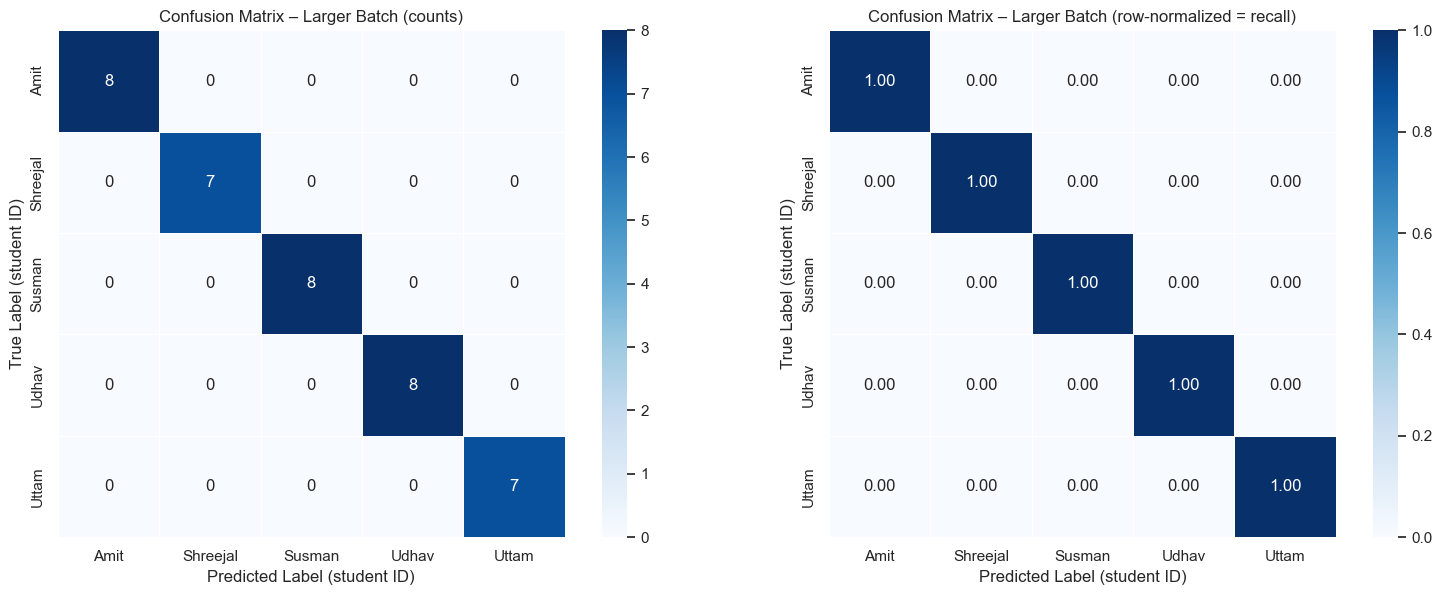

Confusion matrix as a table (rows = true student, columns = predicted student):


Predicted,Amit,Shreejal,Susman,Udhav,Uttam
True,,,,,
Amit,8,0,0,0,0
Shreejal,0,7,0,0,0
Susman,0,0,8,0,0
Udhav,0,0,0,8,0
Uttam,0,0,0,0,7



All 38 test images were classified correctly: the confusion matrix is purely diagonal, with no off-diagonal confusions between students.


In [38]:
cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=True, square=True,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0],
            linewidths=0.5, linecolor="white")
axes[0].set_title(f"Confusion Matrix – {SELECTED_NAME} (counts)")
axes[0].set_xlabel("Predicted Label (student ID)")
axes[0].set_ylabel("True Label (student ID)")

cm_normalized = cm.astype("float") / np.maximum(cm.sum(axis=1, keepdims=True), 1)
sns.heatmap(cm_normalized, annot=True, fmt=".2f", cmap="Blues", cbar=True, square=True,
            vmin=0, vmax=1, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1],
            linewidths=0.5, linecolor="white")
axes[1].set_title(f"Confusion Matrix – {SELECTED_NAME} (row-normalized = recall)")
axes[1].set_xlabel("Predicted Label (student ID)")
axes[1].set_ylabel("True Label (student ID)")

plt.tight_layout(); plt.show(); plt.close(fig)

print("Confusion matrix as a table (rows = true student, columns = predicted student):")
display(pd.DataFrame(cm, index=pd.Index(CLASS_NAMES, name="True"),
                     columns=pd.Index(CLASS_NAMES, name="Predicted")))

misclassified = int(cm.sum() - np.trace(cm))
if misclassified == 0:
    print(f"\nAll {len(y_test)} test images were classified correctly: the confusion matrix "
          f"is purely diagonal, with no off-diagonal confusions between students.")
else:
    print(f"\n{misclassified} of {len(y_test)} test images were misclassified. Off-diagonal pairs:")
    for true_index, predicted_index in zip(*np.where((cm > 0) & ~np.eye(NUM_CLASSES, dtype=bool))):
        print(f"  True {CLASS_NAMES[true_index]} -> predicted {CLASS_NAMES[predicted_index]}: "
              f"{cm[true_index, predicted_index]} image(s)")

## 13. Classification Report

Per-student precision, recall, F1-score, and support (the number of test images that
truly belong to that student).

In [39]:
report_text = classification_report(y_test, y_pred, labels=range(NUM_CLASSES),
                                    target_names=CLASS_NAMES, digits=4, zero_division=0)
print(f"Classification report – {SELECTED_NAME} on the held-out test set\n")
print(report_text)

report_dict = classification_report(y_test, y_pred, labels=range(NUM_CLASSES),
                                    target_names=CLASS_NAMES, output_dict=True,
                                    zero_division=0)
report_df = pd.DataFrame(report_dict).transpose()
report_df["support"] = report_df["support"].astype(int)
display(report_df.round(4))

Classification report – Larger Batch on the held-out test set

              precision    recall  f1-score   support

        Amit     1.0000    1.0000    1.0000         8
    Shreejal     1.0000    1.0000    1.0000         7
      Susman     1.0000    1.0000    1.0000         8
       Udhav     1.0000    1.0000    1.0000         8
       Uttam     1.0000    1.0000    1.0000         7

    accuracy                         1.0000        38
   macro avg     1.0000    1.0000    1.0000        38
weighted avg     1.0000    1.0000    1.0000        38



,precision,recall,f1-score,support
Amit,1.0,1.0,1.0,8
Shreejal,1.0,1.0,1.0,7
Susman,1.0,1.0,1.0,8
Udhav,1.0,1.0,1.0,8
Uttam,1.0,1.0,1.0,7
accuracy,1.0,1.0,1.0,1
macro avg,1.0,1.0,1.0,38
weighted avg,1.0,1.0,1.0,38


## 14. Training Curves for the Selected Model

Training versus validation accuracy and loss for the configuration that was selected.
The gap between the two curves is the overfitting signal: curves that stay close
together indicate the augmentation and dropout are holding overfitting in check, while
a validation loss that turns upward while the training loss keeps falling is the
classic overfitting pattern.

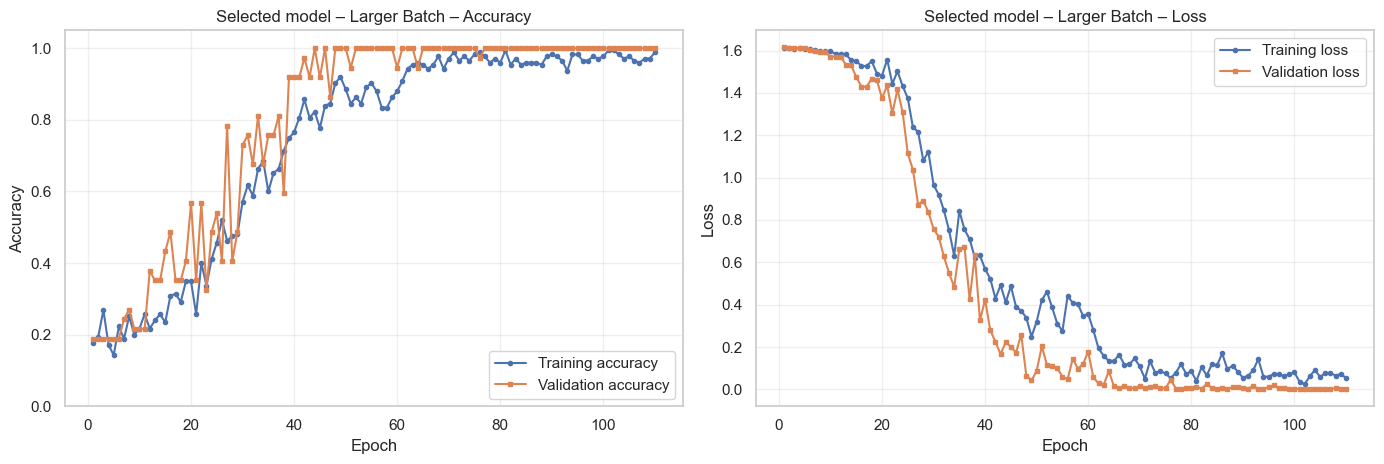

Epochs actually trained        : 110 (max was 120; EarlyStopping restored the weights from the best validation epoch)
Best validation-loss epoch     : 85
Final training accuracy        : 0.9886
Final validation accuracy      : 1.0000
Train - validation accuracy gap: -0.0114
Final training loss            : 0.0545
Final validation loss          : 0.0016
Minimum validation loss        : 0.0013

Interpretation: the training and validation curves stayed close together, so no substantial overfitting is visible in this run. Note that the training curve is measured on augmented images while the validation curve is measured on clean ones, which is why validation accuracy can sit at or above training accuracy here.


In [40]:
plot_training_history(selected_run["history"], title=f"Selected model – {SELECTED_NAME}")

history = selected_run["history"]
final_train_acc = history["accuracy"][-1]
final_val_acc = history["val_accuracy"][-1]
best_val_epoch = int(np.argmin(history["val_loss"])) + 1
gap = final_train_acc - final_val_acc

print(f"Epochs actually trained        : {len(history['loss'])} (max was {EPOCHS}; "
      f"EarlyStopping restored the weights from the best validation epoch)")
print(f"Best validation-loss epoch     : {best_val_epoch}")
print(f"Final training accuracy        : {final_train_acc:.4f}")
print(f"Final validation accuracy      : {final_val_acc:.4f}")
print(f"Train - validation accuracy gap: {gap:+.4f}")
print(f"Final training loss            : {history['loss'][-1]:.4f}")
print(f"Final validation loss          : {history['val_loss'][-1]:.4f}")
print(f"Minimum validation loss        : {min(history['val_loss']):.4f}")

if gap > 0.15:
    print("\nInterpretation: training accuracy is clearly above validation accuracy, "
          "so this run overfitted the small training set.")
elif history["val_loss"][-1] > min(history["val_loss"]) * 1.5:
    print("\nInterpretation: validation loss rose well above its minimum late in training, "
          "which is mild overfitting. EarlyStopping restored the best-epoch weights.")
else:
    print("\nInterpretation: the training and validation curves stayed close together, so no "
          "substantial overfitting is visible in this run. Note that the training curve is "
          "measured on augmented images while the validation curve is measured on clean ones, "
          "which is why validation accuracy can sit at or above training accuracy here.")

## 15. Per-Class Performance

Precision, recall, and F1-score for each student side by side. This shows whether the
classifier is equally reliable for every enrolled student, or whether particular
students are harder to recognize.

,class_name (student id),Precision,Recall,F1-score,Support
0,Amit,1.0,1.0,1.0,8
1,Shreejal,1.0,1.0,1.0,7
2,Susman,1.0,1.0,1.0,8
3,Udhav,1.0,1.0,1.0,8
4,Uttam,1.0,1.0,1.0,7


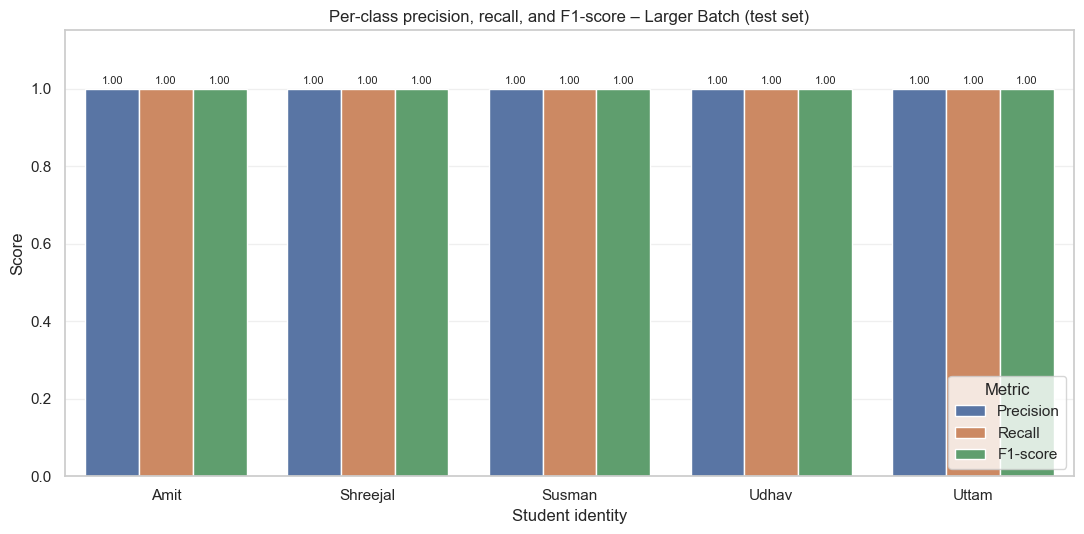

Every student reached the same F1-score (1.0000), so no student was measurably harder to classify on this test set.


In [41]:
per_class_precision, per_class_recall, per_class_f1, per_class_support = \
    precision_recall_fscore_support(y_test, y_pred, labels=range(NUM_CLASSES),
                                    average=None, zero_division=0)

per_class_df = pd.DataFrame({
    "class_name (student id)": CLASS_NAMES,
    "Precision": per_class_precision,
    "Recall": per_class_recall,
    "F1-score": per_class_f1,
    "Support": per_class_support.astype(int),
})
display(per_class_df.round(4))

plot_df = per_class_df.melt(id_vars="class_name (student id)",
                            value_vars=["Precision", "Recall", "F1-score"],
                            var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(data=plot_df, x="class_name (student id)", y="Score", hue="Metric", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_title(f"Per-class precision, recall, and F1-score – {SELECTED_NAME} (test set)")
ax.set_xlabel("Student identity"); ax.set_ylabel("Score"); ax.set_ylim(0, 1.15)
ax.legend(title="Metric", loc="lower right"); ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout(); plt.show(); plt.close(fig)

weakest = per_class_df.loc[per_class_df["F1-score"].idxmin()]
strongest = per_class_df.loc[per_class_df["F1-score"].idxmax()]
if np.isclose(weakest["F1-score"], strongest["F1-score"]):
    print(f"Every student reached the same F1-score ({strongest['F1-score']:.4f}), so no "
          f"student was measurably harder to classify on this test set.")
else:
    print(f"Strongest class: {strongest['class_name (student id)']} (F1 = {strongest['F1-score']:.4f})")
    print(f"Weakest class  : {weakest['class_name (student id)']} (F1 = {weakest['F1-score']:.4f})")

## 16. Prediction Examples

Test images with their true student, the predicted student, and the model's softmax
confidence. Correct predictions are titled in green and incorrect ones in red. If the
model made no mistakes on this test set, that is stated explicitly rather than
fabricating an error example.

Correct predictions  : 38 / 38
Incorrect predictions: 0 / 38


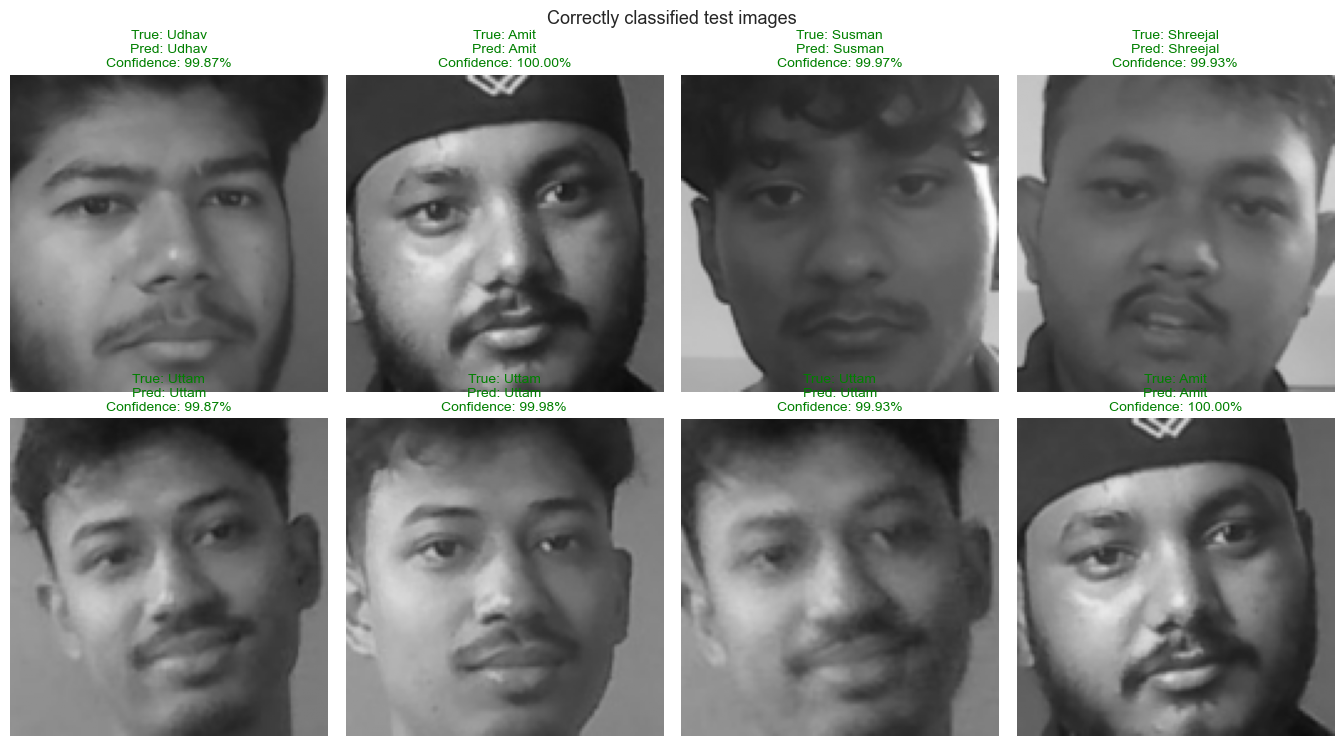


There are NO incorrect predictions on this test set: the selected model classified all 38 test images correctly, so no misclassified examples can be shown. No artificial error examples have been created.

Mean confidence on correct predictions  : 0.9991
Lowest confidence on any test image     : 0.9943 (true Susman, predicted Susman)


In [42]:
correct_indices = np.where(y_pred == y_test)[0]
incorrect_indices = np.where(y_pred != y_test)[0]
print(f"Correct predictions  : {len(correct_indices)} / {len(y_test)}")
print(f"Incorrect predictions: {len(incorrect_indices)} / {len(y_test)}")

def show_prediction_grid(indices, title, columns=4):
    """Display test images annotated with true class, predicted class, and confidence."""
    if len(indices) == 0:
        return
    rows = int(np.ceil(len(indices) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(3.4 * columns, 3.8 * rows), squeeze=False)
    for position, index in enumerate(indices):
        ax = axes[position // columns, position % columns]
        ax.imshow(X_test[index, :, :, 0], cmap="gray", vmin=0, vmax=1)
        is_correct = y_pred[index] == y_test[index]
        ax.set_title(f"True: {CLASS_NAMES[y_test[index]]}\n"
                     f"Pred: {CLASS_NAMES[y_pred[index]]}\n"
                     f"Confidence: {y_pred_confidence[index]:.2%}",
                     color="green" if is_correct else "red", fontsize=10)
        ax.axis("off")
    for position in range(len(indices), rows * columns):
        axes[position // columns, position % columns].axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout(); plt.show(); plt.close(fig)

rng = np.random.default_rng(RANDOM_STATE)
sample_correct = rng.choice(correct_indices, size=min(8, len(correct_indices)), replace=False)
sample_correct = np.sort(sample_correct)
show_prediction_grid(sample_correct, "Correctly classified test images")

if len(incorrect_indices) > 0:
    show_prediction_grid(incorrect_indices[:8], "Misclassified test images")
    print("\nAll misclassifications on the test set:")
    display(pd.DataFrame({
        "test_index": incorrect_indices,
        "true_class": [CLASS_NAMES[i] for i in y_test[incorrect_indices]],
        "predicted_class": [CLASS_NAMES[i] for i in y_pred[incorrect_indices]],
        "confidence": np.round(y_pred_confidence[incorrect_indices], 4),
    }))
else:
    print("\nThere are NO incorrect predictions on this test set: the selected model "
          f"classified all {len(y_test)} test images correctly, so no misclassified examples "
          "can be shown. No artificial error examples have been created.")

print(f"\nMean confidence on correct predictions  : {y_pred_confidence[correct_indices].mean():.4f}")
if len(incorrect_indices) > 0:
    print(f"Mean confidence on incorrect predictions: {y_pred_confidence[incorrect_indices].mean():.4f}")
print(f"Lowest confidence on any test image     : {y_pred_confidence.min():.4f} "
      f"(true {CLASS_NAMES[y_test[np.argmin(y_pred_confidence)]]}, "
      f"predicted {CLASS_NAMES[y_pred[np.argmin(y_pred_confidence)]]})")

## 17a. Metric Recap for the Report

This cell prints every number quoted in the written findings below in one block, so
the discussion can be checked against the values that were actually produced by this
run.

In [43]:
print("=" * 72)
print("RESULTS RECAP")
print("=" * 72)
print(f"Dataset          : {len(X)} images, {NUM_CLASSES} classes {CLASS_NAMES}")
print(f"Input shape      : {INPUT_SHAPE}, values scaled to 0-1")
print(f"Split            : {len(X_train)} train / {len(X_val)} validation / {len(X_test)} test")
print(f"Training device  : {TRAIN_DEVICE}")
print("-" * 72)
print("EXPERIMENTS (sorted by validation accuracy, then validation loss)")
print(ranked[["Experiment", "Learning Rate", "Batch Size", "Dropout", "Filters",
              "Epochs Trained", "Best Epoch", "Train Acc @ Best Epoch",
              "Val Acc @ Best Epoch", "Best Val Acc",
              "Min Val Loss"]].to_string(index=False))
print("-" * 72)
print(f"Selected model   : {SELECTED_NAME} "
      f"(val acc {selected_config['Val Acc @ Best Epoch']:.4f}, "
      f"val loss {selected_config['Min Val Loss']:.4f})")
print(f"Test accuracy    : {accuracy:.4f}")
print(f"Macro    P/R/F1  : {macro_precision:.4f} / {macro_recall:.4f} / {macro_f1:.4f}")
print(f"Weighted P/R/F1  : {weighted_precision:.4f} / {weighted_recall:.4f} / {weighted_f1:.4f}")
print(f"Test loss        : {test_loss:.4f}")
print(f"Misclassified    : {len(incorrect_indices)} of {len(y_test)} test images")
print("=" * 72)

RESULTS RECAP
Dataset          : 250 images, 5 classes ['Amit', 'Shreejal', 'Susman', 'Udhav', 'Uttam']
Input shape      : (128, 128, 1), values scaled to 0-1
Split            : 175 train / 37 validation / 38 test
Training device  : cuda:0
------------------------------------------------------------------------
EXPERIMENTS (sorted by validation accuracy, then validation loss)
    Experiment  Learning Rate  Batch Size  Dropout    Filters  Epochs Trained  Best Epoch  Train Acc @ Best Epoch  Val Acc @ Best Epoch  Best Val Acc  Min Val Loss
  Larger Batch         0.0010          64      0.3  32-64-128             110          85                0.960000                   1.0           1.0      0.001335
  Larger Model         0.0010          32      0.3 64-128-256             120          99                0.977143                   1.0           1.0      0.001361
      Baseline         0.0010          32      0.3  32-64-128             120         103                0.994286                

## 17. Experimental Findings

The discussion below is **generated from the variables produced by this run**, so every
number quoted is a value the notebook actually computed. Re-running the notebook
regenerates the text along with the results.

In [44]:
from IPython.display import Markdown

def pct(value):
    return f"{value * 100:.2f}%"

# --- effect of each hyperparameter, measured against the baseline ---
by_name = comparison_df.set_index("Experiment")
baseline_row = by_name.loc["Baseline"]

def delta_sentence(experiment, changed):
    row = by_name.loc[experiment]
    acc_delta = row["Val Acc @ Best Epoch"] - baseline_row["Val Acc @ Best Epoch"]
    loss_delta = row["Min Val Loss"] - baseline_row["Min Val Loss"]
    direction = "improved" if acc_delta > 0 else ("reduced" if acc_delta < 0 else "left unchanged")
    return (f"- **{changed}** ({experiment}): validation accuracy "
            f"{pct(row['Val Acc @ Best Epoch'])} vs the baseline's "
            f"{pct(baseline_row['Val Acc @ Best Epoch'])} ({acc_delta:+.4f}), validation loss "
            f"{row['Min Val Loss']:.4f} vs {baseline_row['Min Val Loss']:.4f} "
            f"({loss_delta:+.4f}). This change **{direction}** validation accuracy.")

# --- overfitting check on the selected run ---
selected_history = selected_run["history"]
selected_gap = (selected_config["Train Acc @ Best Epoch"]
                - selected_config["Val Acc @ Best Epoch"])
final_val_loss = selected_history["val_loss"][-1]
min_val_loss = min(selected_history["val_loss"])
loss_rebound = final_val_loss - min_val_loss

if selected_gap > 0.15:
    overfit_text = (f"training accuracy at the restored epoch "
                    f"({pct(selected_config['Train Acc @ Best Epoch'])}) sits "
                    f"{selected_gap:.4f} above validation accuracy "
                    f"({pct(selected_config['Val Acc @ Best Epoch'])}), which is a clear "
                    f"possible overfitting gap on a {len(X_train)}-image training set")
elif loss_rebound > 0.3:
    overfit_text = (f"the train-validation accuracy gap is small ({selected_gap:+.4f}), but "
                    f"validation loss rose from its minimum of {min_val_loss:.4f} to "
                    f"{final_val_loss:.4f} by the last epoch (+{loss_rebound:.4f}), which is "
                    f"mild late-training overfitting. EarlyStopping restored the "
                    f"best-epoch weights, which mitigates late-epoch degradation but does not prove generalization")
else:
    overfit_text = (f"no substantial overfitting is visible: the train-validation accuracy "
                    f"gap at the restored epoch is only {selected_gap:+.4f} and validation "
                    f"loss ended at {final_val_loss:.4f} against a minimum of "
                    f"{min_val_loss:.4f}. Note that training accuracy is measured on "
                    f"*augmented* images while validation accuracy is measured on clean "
                    f"ones, so the training curve can legitimately sit below the "
                    f"validation curve here")

# --- per-class difficulty ---
sorted_classes = per_class_df.sort_values("F1-score", ascending=False)
if np.isclose(sorted_classes["F1-score"].min(), sorted_classes["F1-score"].max()):
    class_text = (f"Every student reached an identical F1-score of "
                  f"{sorted_classes['F1-score'].iloc[0]:.4f}, so on this test set no student "
                  f"was measurably harder to classify than another.")
else:
    best_row = sorted_classes.iloc[0]
    worst_row = sorted_classes.iloc[-1]
    class_text = (f"Student **{best_row['class_name (student id)']}** was the easiest to "
                  f"recognize (F1 = {best_row['F1-score']:.4f}, precision "
                  f"{best_row['Precision']:.4f}, recall {best_row['Recall']:.4f}), while "
                  f"student **{worst_row['class_name (student id)']}** was the hardest "
                  f"(F1 = {worst_row['F1-score']:.4f}, precision {worst_row['Precision']:.4f}, "
                  f"recall {worst_row['Recall']:.4f}).")

# --- confusion matrix ---
off_diagonal = [(CLASS_NAMES[t], CLASS_NAMES[p], int(cm[t, p]))
                for t, p in zip(*np.where((cm > 0) & ~np.eye(NUM_CLASSES, dtype=bool)))]
if not off_diagonal:
    cm_text = (f"The confusion matrix is entirely diagonal: all {len(y_test)} test images "
               f"fell on the correct row and column, so no student was ever mistaken for "
               f"another on this test set.")
else:
    pairs = "; ".join(f"true **{t}** predicted as **{p}** ({n} image{'s' if n > 1 else ''})"
                      for t, p, n in off_diagonal)
    cm_text = (f"The confusion matrix shows {len(incorrect_indices)} off-diagonal "
               f"entr{'ies' if len(off_diagonal) > 1 else 'y'}: {pairs}. Every other test "
               f"image fell on the diagonal.")

worst_experiment = ranked.iloc[-1]

findings = f"""
### Effect of each hyperparameter

All four variants below change exactly one factor against the baseline
(lr {baseline_row['Learning Rate']}, batch {int(baseline_row['Batch Size'])},
dropout {baseline_row['Dropout']}, filters {baseline_row['Filters']}), which trained for
{int(baseline_row['Epochs Trained'])} epochs and reached
{pct(baseline_row['Val Acc @ Best Epoch'])} validation accuracy at its restored epoch
{int(baseline_row['Best Epoch'])}.

{delta_sentence("Lower LR", "Learning rate 0.001 -> 0.0001")}
{delta_sentence("Higher Dropout", "Dropout 0.3 -> 0.5")}
{delta_sentence("Larger Model", "Filters 32-64-128 -> 64-128-256")}
{delta_sentence("Larger Batch", "Batch size 32 -> 64")}

**Learning rate.** The lower learning rate reached
{pct(by_name.loc['Lower LR', 'Val Acc @ Best Epoch'])} validation accuracy against the
baseline's {pct(baseline_row['Val Acc @ Best Epoch'])}. With only
{int(np.ceil(len(X_train) / int(baseline_row['Batch Size'])))} gradient updates per epoch, a 10x smaller
step size changes optimization within the same epoch budget. Inspect both curves;
these observations alone do not establish whether a longer run would converge better.

**Dropout.** Raising dropout from 0.3 to 0.5 moved validation accuracy to
{pct(by_name.loc['Higher Dropout', 'Val Acc @ Best Epoch'])} and validation loss to
{by_name.loc['Higher Dropout', 'Min Val Loss']:.4f}. Stronger regularization may change
underfitting or overfitting; a single run cannot establish the cause of the difference.

**Model size.** The larger 64-128-256 network
({int(by_name.loc['Larger Model', 'Parameters']):,} parameters against the baseline's
{int(baseline_row['Parameters']):,}) reached
{pct(by_name.loc['Larger Model', 'Val Acc @ Best Epoch'])} validation accuracy and took
{by_name.loc['Larger Model', 'Train Time (s)']:.0f}s to train versus
{baseline_row['Train Time (s)']:.0f}s for the baseline.

**Batch size.** Increasing the batch to 64 reduces the number of updates per epoch and gave
{pct(by_name.loc['Larger Batch', 'Val Acc @ Best Epoch'])} validation accuracy.

### Strongest experiment

**{SELECTED_NAME}** performed best on the validation data, with
{pct(selected_config['Val Acc @ Best Epoch'])} validation accuracy at its restored epoch
({int(selected_config['Best Epoch'])} of {int(selected_config['Epochs Trained'])} trained)
and a minimum validation loss of {selected_config['Min Val Loss']:.4f}. The weakest was
**{worst_experiment['Experiment']}** at
{pct(worst_experiment['Val Acc @ Best Epoch'])} validation accuracy
(validation loss {worst_experiment['Min Val Loss']:.4f}) - a spread of
{(selected_config['Val Acc @ Best Epoch'] - worst_experiment['Val Acc @ Best Epoch']) * 100:.2f}
percentage points across the five configurations.

Selection used validation data only. The test set was evaluated afterwards and
gave {pct(accuracy)} accuracy with macro F1 {macro_f1:.4f} and weighted F1 {weighted_f1:.4f}.

### Did overfitting occur?

For the selected model, {overfit_text}.

### Which classes were easier or harder?

{class_text}

Macro-averaged precision, recall, and F1 on the test set were {macro_precision:.4f},
{macro_recall:.4f}, and {macro_f1:.4f}; the weighted averages were
{weighted_precision:.4f}, {weighted_recall:.4f}, and {weighted_f1:.4f}. The two sets of
averages may differ depending on class support and errors; the current test supports are
({', '.join(f'{name}: {int(count)}' for name, count in zip(CLASS_NAMES, per_class_df['Support']))}
images per student).

### What the confusion matrix showed

{cm_text}
"""

display(Markdown(findings))


### Effect of each hyperparameter

All four variants below change exactly one factor against the baseline
(lr 0.001, batch 32,
dropout 0.3, filters 32-64-128), which trained for
120 epochs and reached
100.00% validation accuracy at its restored epoch
103.

- **Learning rate 0.001 -> 0.0001** (Lower LR): validation accuracy 100.00% vs the baseline's 100.00% (+0.0000), validation loss 0.0739 vs 0.0025 (+0.0714). This change **left unchanged** validation accuracy.
- **Dropout 0.3 -> 0.5** (Higher Dropout): validation accuracy 100.00% vs the baseline's 100.00% (+0.0000), validation loss 0.0036 vs 0.0025 (+0.0011). This change **left unchanged** validation accuracy.
- **Filters 32-64-128 -> 64-128-256** (Larger Model): validation accuracy 100.00% vs the baseline's 100.00% (+0.0000), validation loss 0.0014 vs 0.0025 (-0.0011). This change **left unchanged** validation accuracy.
- **Batch size 32 -> 64** (Larger Batch): validation accuracy 100.00% vs the baseline's 100.00% (+0.0000), validation loss 0.0013 vs 0.0025 (-0.0012). This change **left unchanged** validation accuracy.

**Learning rate.** The lower learning rate reached
100.00% validation accuracy against the
baseline's 100.00%. With only
6 gradient updates per epoch, a 10x smaller
step size changes optimization within the same epoch budget. Inspect both curves;
these observations alone do not establish whether a longer run would converge better.

**Dropout.** Raising dropout from 0.3 to 0.5 moved validation accuracy to
100.00% and validation loss to
0.0036. Stronger regularization may change
underfitting or overfitting; a single run cannot establish the cause of the difference.

**Model size.** The larger 64-128-256 network
(1,177,797 parameters against the baseline's
303,589) reached
100.00% validation accuracy and took
100s to train versus
200s for the baseline.

**Batch size.** Increasing the batch to 64 reduces the number of updates per epoch and gave
100.00% validation accuracy.

### Strongest experiment

**Larger Batch** performed best on the validation data, with
100.00% validation accuracy at its restored epoch
(85 of 110 trained)
and a minimum validation loss of 0.0013. The weakest was
**Lower LR** at
100.00% validation accuracy
(validation loss 0.0739) - a spread of
0.00
percentage points across the five configurations.

Selection used validation data only. The test set was evaluated afterwards and
gave 100.00% accuracy with macro F1 1.0000 and weighted F1 1.0000.

### Did overfitting occur?

For the selected model, no substantial overfitting is visible: the train-validation accuracy gap at the restored epoch is only -0.0400 and validation loss ended at 0.0016 against a minimum of 0.0013. Note that training accuracy is measured on *augmented* images while validation accuracy is measured on clean ones, so the training curve can legitimately sit below the validation curve here.

### Which classes were easier or harder?

Every student reached an identical F1-score of 1.0000, so on this test set no student was measurably harder to classify than another.

Macro-averaged precision, recall, and F1 on the test set were 1.0000,
1.0000, and 1.0000; the weighted averages were
1.0000, 1.0000, and 1.0000. The two sets of
averages may differ depending on class support and errors; the current test supports are
(Amit: 8, Shreejal: 7, Susman: 8, Udhav: 8, Uttam: 7
images per student).

### What the confusion matrix showed

The confusion matrix is entirely diagonal: all 38 test images fell on the correct row and column, so no student was ever mistaken for another on this test set.


## 18. Limitations

These original notes describe the historical 250-image collection and default image-level protocol. Current sizes, hardware and protocol are printed at runtime; NN-40 provides the full comparative limitations. They are properties of the
dataset and the evaluation protocol, not of the code.

1. **The dataset is small.** 250 images across 5 students, of which only 175 are used
   for training — roughly 35 images per student. A CNN trained from scratch on that
   much data can memorize surface cues long before it learns a general representation
   of a face, which is exactly why the epoch budget, dropout, and augmentation
   settings mattered so much in the experiments above.

2. **Consecutive frames are near-duplicates.** The images were captured as webcam
   bursts, so neighbouring frames differ by milliseconds. They are not 250 independent
   observations; the *effective* sample size is far smaller than the file count
   suggests.

3. **Image-level splitting makes the evaluation optimistic.** Because no `session_id`
   was recorded, the 70/15/15 split is random at the image level, so near-identical
   frames can land on both sides of the train/test boundary. The reported test accuracy
   therefore measures "can the model re-identify frames from a session it has already
   seen", which is an easier question than the one an attendance system actually faces.
   This is the single largest caveat on the results.

4. **Lighting, pose, and background barely vary.** Each student was captured in one
   sitting, so background, clothing, illumination, camera distance, and expression are
   almost constant within a class. The model can reach high accuracy by keying on the
   background or on clothing rather than on the face.

5. **The test set is very small.** With 38 test images, one image is worth 2.63
   percentage points of accuracy, and each student contributes only 7–8 images. Per-class
   precision and recall are estimated from a handful of samples each, so their
   confidence intervals are wide and small differences between students are not
   statistically meaningful.

6. **High accuracy does not mean real-world robustness.** Nothing in this evaluation
   tests a different day, a different room, a different camera, glasses, a mask, a
   changed hairstyle, or a student who is not enrolled. A closed-set classifier also
   *must* assign one of the five known identities to any face it is shown, including a
   stranger's — it has no way to answer "not enrolled".

7. **Results are specific to this seed and this CPU run.** Seeds are fixed, but a
   different split seed would move the metrics, and the reported figures come from a
   single run rather than an averaged repetition.

## 19. Future Improvements

Ordered roughly by how much each would improve the honesty and the robustness of the
result, not by effort.

1. **Collect across multiple sessions.** Capture each student on several different days
   so that within-class variation reflects real conditions rather than one burst.
2. **Record `session_id` and use session-aware splitting.** The
   `session_aware_split()` function already written in EDA section 5 can then be used
   directly, giving an evaluation that is not inflated by near-duplicate frames. This is
   the single most valuable change.
3. **More images per student, and more students.** Both the training signal and the
   reliability of the test estimate scale with data.
4. **Deliberate variation in lighting, pose, distance, expression, and background.**
   Capturing with different backgrounds in particular removes the background shortcut.
5. **Face detection and alignment before training.** Cropping to the detected face and
   aligning on the eye positions removes background and scale as confounds, so the model
   is forced to use facial structure.
6. **Transfer learning.** Fine-tuning an ImageNet backbone (MobileNetV2, ResNet50,
   EfficientNet) on consistently prepared crops may improve a CNN trained from
   scratch, but this requires a separate controlled experiment rather than an assumed win.
7. **Face embeddings instead of classification.** A FaceNet/ArcFace-style embedding with
   a nearest-neighbour or cosine-similarity match would let a new student be enrolled by
   adding a few reference images, with no retraining, and gives a natural distance
   threshold for rejecting unenrolled faces.
8. **An "unknown" rejection path.** Either a confidence threshold on the softmax output
   or an embedding-distance threshold, so an unenrolled person is not forced into one of
   the five classes.
9. **Live webcam integration.** Wire the selected model into a capture loop that detects
   a face, preprocesses it identically to NN-1, predicts, applies the rejection
   threshold, and writes the attendance record — plus temporal smoothing over several
   consecutive frames before committing a mark.
10. **Cross-validation and repeated seeds.** Stratified k-fold, or the same experiment
    repeated over several seeds, would replace single-run point estimates with a mean
    and a spread.

## 20. Conclusion

This section is generated from the run's own variables, so the figures below match the
outputs above exactly.

In [45]:
conclusion = f"""
**What was implemented.** A convolutional neural network was built in PyTorch
{torch.__version__} to identify {NUM_CLASSES} enrolled students
({', '.join(CLASS_NAMES)}) from the same self-collected face dataset analysed in the Week 2
EDA. The {len(X)} images were resized to {IMG_SIZE[0]} x {IMG_SIZE[1]}, kept as single-channel
grayscale, scaled to 0-1, and label-encoded to integers, giving an input tensor of shape
{X.shape}. The data was split {len(X_train)}/{len(X_val)}/{len(X_test)}
({100 * len(X_train) / len(X):.0f}/{100 * len(X_val) / len(X):.0f}/{100 * len(X_test) / len(X):.0f})
using {SPLIT_PROTOCOL} and a fixed seed, and augmentation (flip, rotation, translation, zoom,
brightness) was applied to the training split only. The architecture stacks
Conv2d/MaxPool2d/Dropout blocks into adaptive average pooling and a linear head with inference softmax, trained
with Adam and CrossEntropyLoss on {TRAIN_DEVICE}.

**Hyperparameter experiments.** {len(experiments)} configurations were trained -
{', '.join(experiments)} - each changing one factor against the baseline, with
EarlyStopping and ReduceLROnPlateau. Validation accuracy across the five ranged from
{pct(ranked['Val Acc @ Best Epoch'].min())} to {pct(ranked['Val Acc @ Best Epoch'].max())}.

**Selected configuration.** **{SELECTED_NAME}** - learning rate
{selected_config['Learning Rate']}, batch size {int(selected_config['Batch Size'])}, dropout
{selected_config['Dropout']}, filters {selected_config['Filters']},
{int(selected_config['Parameters']):,} parameters. It trained for
{int(selected_config['Epochs Trained'])} epochs with the weights restored from epoch
{int(selected_config['Best Epoch'])}, where it scored
{pct(selected_config['Val Acc @ Best Epoch'])} validation accuracy at a validation loss of
{selected_config['Min Val Loss']:.4f}. Selection used validation metrics only; the test set
was held back until the final evaluation.

**Final test-set performance** ({len(y_test)} unseen images):

| Metric | Macro average | Weighted average |
|---|---:|---:|
| Precision | {macro_precision:.4f} | {weighted_precision:.4f} |
| Recall | {macro_recall:.4f} | {weighted_recall:.4f} |
| F1-score | {macro_f1:.4f} | {weighted_f1:.4f} |

Test accuracy was **{pct(accuracy)}** ({int((y_pred == y_test).sum())} of {len(y_test)} images
correct, test loss {test_loss:.4f}), with {len(incorrect_indices)} misclassified image(s).

**Main findings.** {SELECTED_NAME} gave the strongest validation performance of the five
configurations. {cm_text} {class_text}

**Main limitation.** The {pct(accuracy)} test accuracy requires independent field validation. The
historical images are webcam bursts. Under an image-level split, near-identical frames can
appear on both sides of the train/test boundary. The historical collection used a single
session per student with limited lighting/background variation. Session-aware evaluation and multi-session
collection - both described in NN-18 and NN-19, with the splitting function already written
in EDA section 5 - are required before this number can be read as a measure of real-world
attendance performance.
"""

display(Markdown(conclusion))


**What was implemented.** A convolutional neural network was built in PyTorch
2.14.1+cu126 to identify 5 enrolled students
(Amit, Shreejal, Susman, Udhav, Uttam) from the same self-collected face dataset analysed in the Week 2
EDA. The 250 images were resized to 128 x 128, kept as single-channel
grayscale, scaled to 0-1, and label-encoded to integers, giving an input tensor of shape
(250, 128, 128, 1). The data was split 175/37/38
(70/15/15)
using stratified image-level 70/15/15 and a fixed seed, and augmentation (flip, rotation, translation, zoom,
brightness) was applied to the training split only. The architecture stacks
Conv2d/MaxPool2d/Dropout blocks into adaptive average pooling and a linear head with inference softmax, trained
with Adam and CrossEntropyLoss on cuda:0.

**Hyperparameter experiments.** 5 configurations were trained -
Baseline, Lower LR, Higher Dropout, Larger Model, Larger Batch - each changing one factor against the baseline, with
EarlyStopping and ReduceLROnPlateau. Validation accuracy across the five ranged from
100.00% to 100.00%.

**Selected configuration.** **Larger Batch** - learning rate
0.001, batch size 64, dropout
0.3, filters 32-64-128,
303,589 parameters. It trained for
110 epochs with the weights restored from epoch
85, where it scored
100.00% validation accuracy at a validation loss of
0.0013. Selection used validation metrics only; the test set
was held back until the final evaluation.

**Final test-set performance** (38 unseen images):

| Metric | Macro average | Weighted average |
|---|---:|---:|
| Precision | 1.0000 | 1.0000 |
| Recall | 1.0000 | 1.0000 |
| F1-score | 1.0000 | 1.0000 |

Test accuracy was **100.00%** (38 of 38 images
correct, test loss 0.0009), with 0 misclassified image(s).

**Main findings.** Larger Batch gave the strongest validation performance of the five
configurations. The confusion matrix is entirely diagonal: all 38 test images fell on the correct row and column, so no student was ever mistaken for another on this test set. Every student reached an identical F1-score of 1.0000, so on this test set no student was measurably harder to classify than another.

**Main limitation.** The 100.00% test accuracy requires independent field validation. The
historical images are webcam bursts. Under an image-level split, near-identical frames can
appear on both sides of the train/test boundary. The historical collection used a single
session per student with limited lighting/background variation. Session-aware evaluation and multi-session
collection - both described in NN-18 and NN-19, with the splitting function already written
in EDA section 5 - are required before this number can be read as a measure of real-world
attendance performance.


## 21. Report Snapshot Checklist

Every output needed for the written report, with the cell that produces it:

| # | Output for the report | Where |
|---|---|---|
| 1 | Dataset & preprocessing summary (X/y shapes, classes, label mapping) | NN-1 |
| 2 | Split sizes and per-class distribution | NN-2 |
| 3 | Augmentation examples (training data only) | NN-4 |
| 4 | `print_model_summary(model)` — baseline architecture | NN-7 |
| 5 | Training output (per-epoch logs, EarlyStopping, ReduceLROnPlateau) | NN-7, NN-8 |
| 6 | Baseline accuracy and loss graphs | NN-7 |
| 7 | Hyperparameter comparison table | NN-9 |
| 8 | Experiment comparison graphs (bar chart + per-epoch curves) | NN-9 |
| 9 | Selected-model ranking, configuration, and `print_model_summary(model)` | NN-10 |
| 10 | Final test metrics (accuracy, macro and weighted P/R/F1) | NN-11 |
| 11 | Confusion matrix heatmap (counts and row-normalized) | NN-12 |
| 12 | Classification report (per-class P/R/F1/support) | NN-13 |
| 13 | Selected-model accuracy and loss graphs with interpretation | NN-14 |
| 14 | Per-class precision/recall/F1 bar chart | NN-15 |
| 15 | Correct and incorrect prediction examples with confidence | NN-16 |
| 16 | One-block metric recap | NN-17a |
| 17 | Experimental findings (generated from the real metrics) | NN-17 |
| 18 | Limitations | NN-18 |
| 19 | Future improvements | NN-19 |
| 20 | Conclusion (generated from the real metrics) | NN-20 |

**How to run:** select the Anaconda base kernel
(the Python 3.11 project environment described in README.md), then Run All from the top. The EDA
section builds `df`, `RANDOM_STATE`, and the class names that this section reuses, so the
notebook must be run in order. Runtime depends on hardware and early stopping; no duration is guaranteed.

## 22. Comparative Results Overview

RNN/LSTM training and the deployment policy were deliberately placed at NN-10A–D, **before** NN-11 evaluates the CNN test set. The remaining sections reuse the CNN predictions from NN-11 and evaluate each selected recurrent model once. Do not revise hyperparameters, threshold, or the deployment family after examining these results.

Historical Week 2 observations (250 grayscale 200 × 200 images, five identities, 50 per identity) describe the earlier collection only. Runtime dataset and split summaries are authoritative. Earlier CNN-only discussion is retained as the original assignment; the comparative discussion below extends it.


## 23–28. Training History Comparison

Each curve uses its own actual epoch count, so early-stopped runs are not padded. Training uses augmentation/dropout; validation uses clean images and inference mode. Gaps alone do not establish generalization to another capture session.


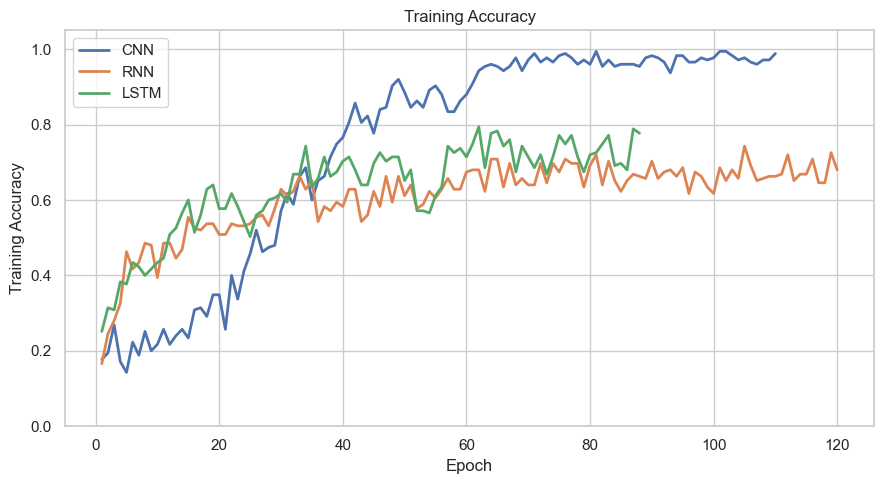

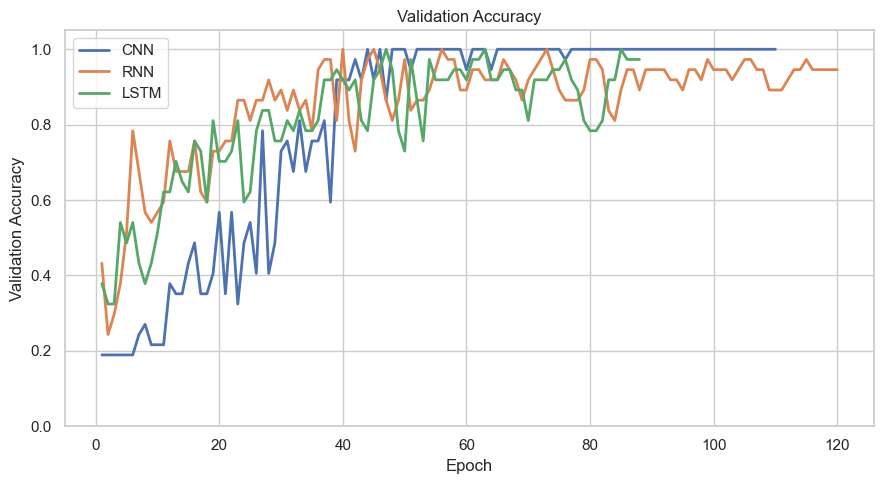

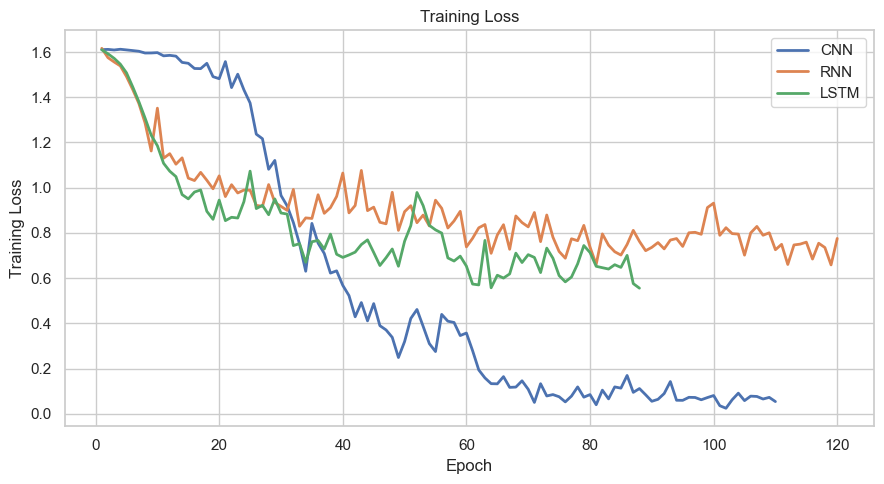

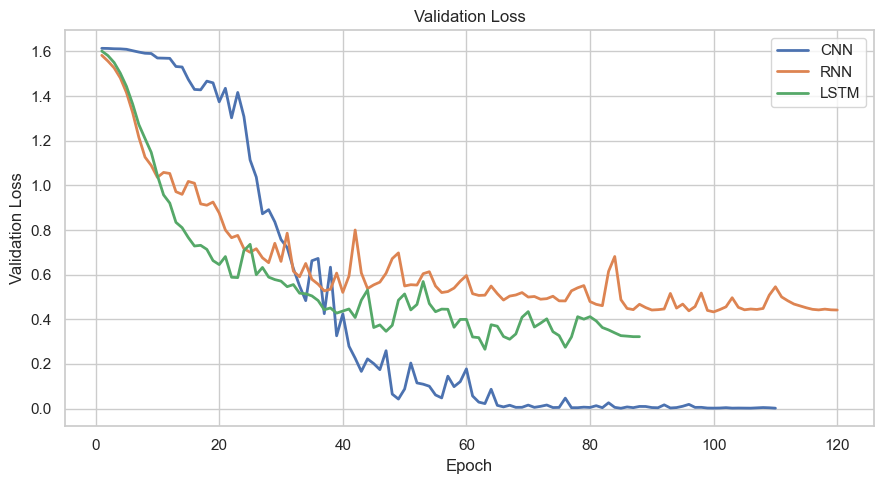

In [46]:
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
SAVE_FIGURES = True

def finish_figure(fig, filename):
    fig.tight_layout()
    if SAVE_FIGURES:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURES_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

for metric, title in [
    ("accuracy", "Training Accuracy"), ("val_accuracy", "Validation Accuracy"),
    ("loss", "Training Loss"), ("val_loss", "Validation Loss"),
]:
    fig, ax = plt.subplots(figsize=(9, 5))
    for name, run in architecture_runs.items():
        values = run["history"][metric]
        ax.plot(np.arange(1, len(values) + 1), values, label=name, linewidth=2)
    ax.set(title=title, xlabel="Epoch", ylabel=title)
    if "accuracy" in metric:
        ax.set_ylim(0, 1.05)
    ax.legend()
    finish_figure(fig, f"history_{metric}.png")


## 29. Final Test Evaluation and Majority Baseline

All configurations are frozen. Headline precision/recall/F1 use macro averaging over the same complete ordered class list. Weighted scores are also exported. A majority baseline chooses the most frequent **training** label (ties resolved by encoded label order) and never learns from test labels. It supplies context, not a deployable recognizer.


In [47]:
prediction_cache = {"CNN": y_pred_proba}
test_losses = {"CNN": float(test_loss)}
for name in ("RNN", "LSTM"):
    evaluation = evaluate_model(architecture_runs[name]["model"], X_test, y_test,
                                DEVICE, sequence=True, batch_size=32)
    prediction_cache[name] = evaluation["probabilities"]
    test_losses[name] = evaluation["loss"]

def metric_row(name, predicted, loss):
    macro = precision_recall_fscore_support(
        y_test, predicted, labels=range(NUM_CLASSES), average="macro", zero_division=0)
    weighted = precision_recall_fscore_support(
        y_test, predicted, labels=range(NUM_CLASSES), average="weighted", zero_division=0)
    return {"Model": name, "Accuracy": float(accuracy_score(y_test, predicted)),
            "Precision": float(macro[0]), "Recall": float(macro[1]), "F1-score": float(macro[2]),
            "Weighted Precision": float(weighted[0]), "Weighted Recall": float(weighted[1]),
            "Weighted F1-score": float(weighted[2]), "Test Loss": loss}

comparison_rows, per_class_rows, classification_reports = [], [], {}
for name, probabilities in prediction_cache.items():
    predicted = probabilities.argmax(axis=1)
    row = metric_row(name, predicted, test_losses[name])
    result = architecture_runs[name]["result"]
    row.update({"Parameters": result["Parameters"], "Training Time (s)": result["Train Time (s)"],
                **efficiency[name]})
    comparison_rows.append(row)
    values = precision_recall_fscore_support(
        y_test, predicted, labels=range(NUM_CLASSES), average=None, zero_division=0)
    for index, student in enumerate(CLASS_NAMES):
        per_class_rows.append({"Model": name, "Student ID": student,
                               "Precision": float(values[0][index]), "Recall": float(values[1][index]),
                               "F1-score": float(values[2][index]), "Support": int(values[3][index])})
    classification_reports[name] = classification_report(
        y_test, predicted, labels=range(NUM_CLASSES), target_names=CLASS_NAMES,
        zero_division=0, output_dict=True)
    print(name)
    print(classification_report(y_test, predicted, labels=range(NUM_CLASSES),
                                target_names=CLASS_NAMES, digits=4, zero_division=0))

model_comparison = pd.DataFrame(comparison_rows)
all_per_class_metrics = pd.DataFrame(per_class_rows)
majority_label = int(np.argmax(np.bincount(y_train, minlength=NUM_CLASSES)))
majority_metrics = metric_row(
    "Majority training class", np.full_like(y_test, majority_label), None)
display(pd.DataFrame([majority_metrics]))


CNN
              precision    recall  f1-score   support

        Amit     1.0000    1.0000    1.0000         8
    Shreejal     1.0000    1.0000    1.0000         7
      Susman     1.0000    1.0000    1.0000         8
       Udhav     1.0000    1.0000    1.0000         8
       Uttam     1.0000    1.0000    1.0000         7

    accuracy                         1.0000        38
   macro avg     1.0000    1.0000    1.0000        38
weighted avg     1.0000    1.0000    1.0000        38

RNN
              precision    recall  f1-score   support

        Amit     1.0000    1.0000    1.0000         8
    Shreejal     1.0000    1.0000    1.0000         7
      Susman     1.0000    1.0000    1.0000         8
       Udhav     1.0000    1.0000    1.0000         8
       Uttam     1.0000    1.0000    1.0000         7

    accuracy                         1.0000        38
   macro avg     1.0000    1.0000    1.0000        38
weighted avg     1.0000    1.0000    1.0000        38

LSTM
         

,Model,Accuracy,Precision,Recall,F1-score,Weighted Precision,Weighted Recall,Weighted F1-score,Test Loss
0,Majority training class,0.210526,0.042105,0.2,0.069565,0.044321,0.210526,0.073227,None


## 29A. Multiclass ROC-AUC Evaluation (CNN vs RNN vs LSTM)

ROC curves use the **held-out test labels and predicted class probabilities**, not hard class predictions. Since this is a five-class student-identification task, each student identity is evaluated using **one-vs-rest (OvR)** classification. The dotted diagonal represents chance discrimination (AUC = 0.5). The mean of the class-level AUC values gives **macro AUC**; micro AUC pools all class decisions. All three architectures use the same test set. A class lacking positive or negative test cases cannot have an OvR ROC curve, in which case the notebook marks macro AUC as undefined rather than inventing a result.

The following cell generates **one ROC figure per architecture**, a **combined micro-average ROC comparison**, and an **AUC summary chart**. Figures are written to `results/figures/`; numeric results are included in the comparison table and exported files.

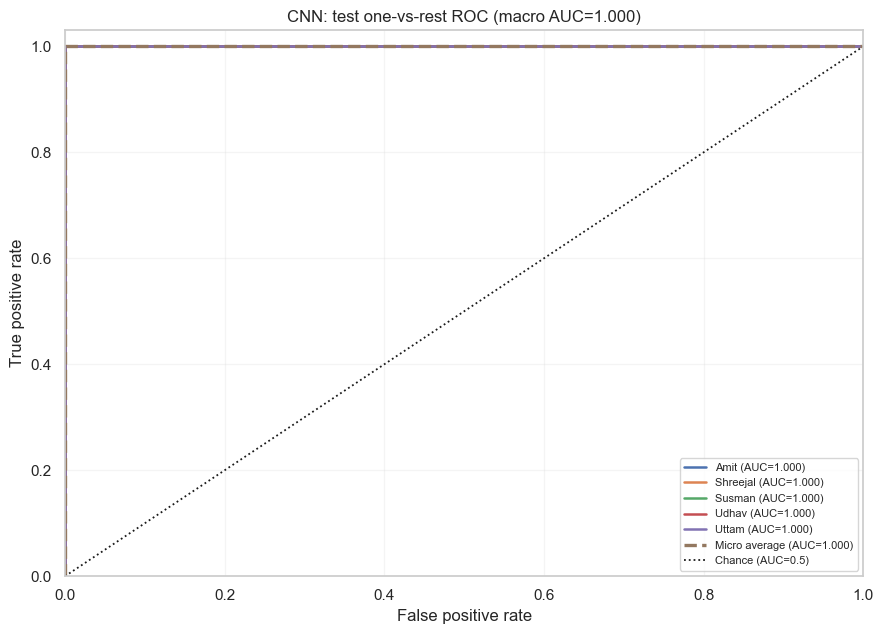

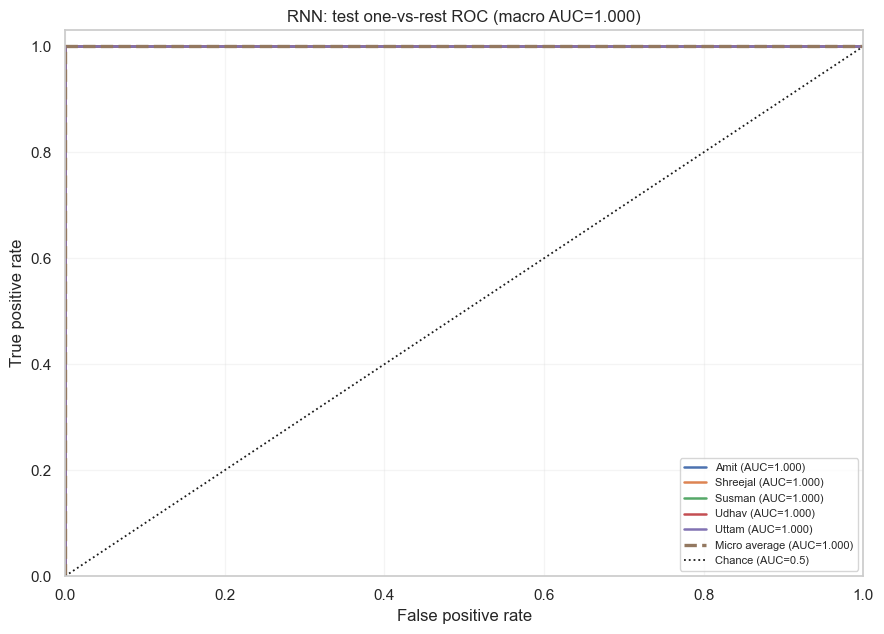

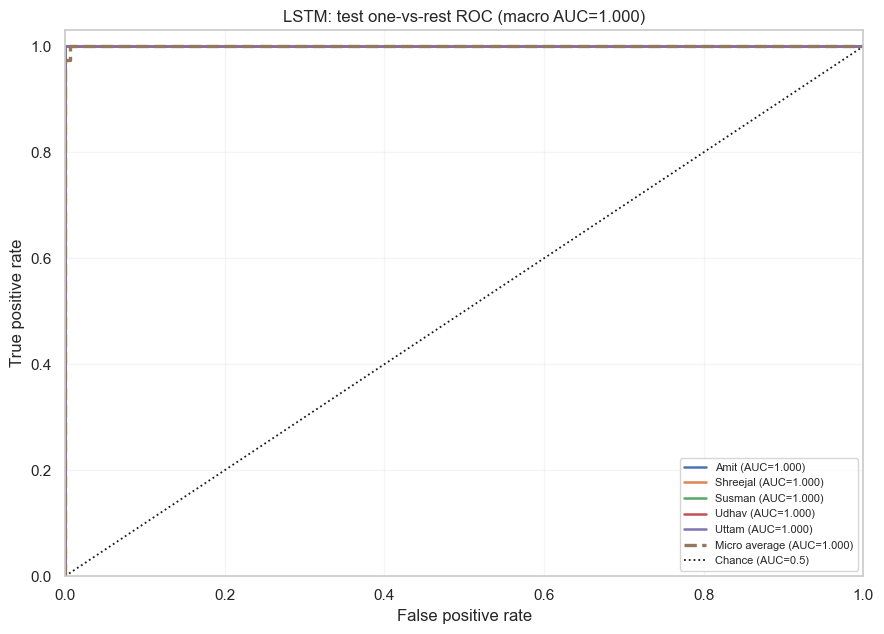

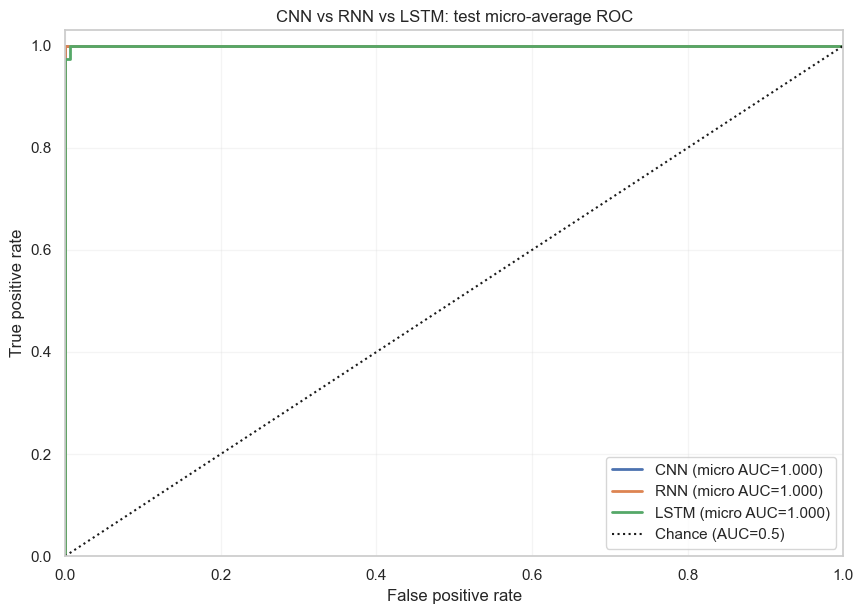

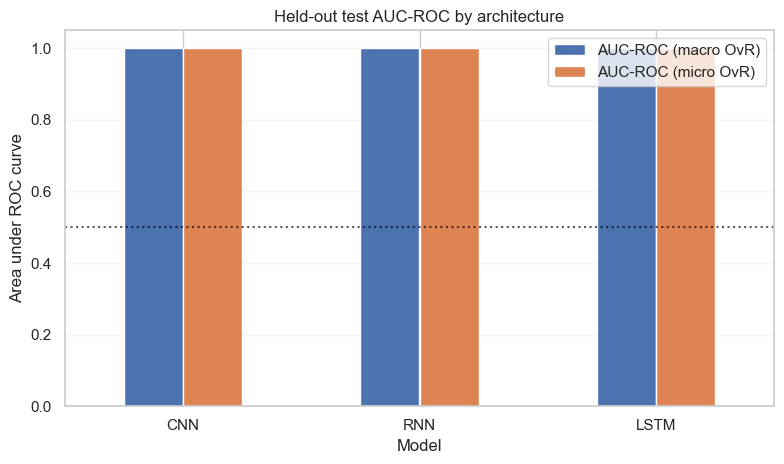

,Model,Accuracy,Precision,Recall,F1-score,AUC-ROC (macro OvR),AUC-ROC (micro OvR)
0,CNN,1.0000,1.000,1.0000,1.0000,1.0,1.0000
1,RNN,1.0000,1.000,1.0000,1.0000,1.0,1.0000
2,LSTM,0.9737,0.975,0.9714,0.9713,1.0,0.9998


,Model,Class,AUC-ROC (OvR)
0,CNN,Amit,1.0
1,CNN,Shreejal,1.0
2,CNN,Susman,1.0
3,CNN,Udhav,1.0
4,CNN,Uttam,1.0
5,RNN,Amit,1.0
6,RNN,Shreejal,1.0
7,RNN,Susman,1.0
8,RNN,Udhav,1.0
9,RNN,Uttam,1.0


In [48]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

roc_auc_rows = []
roc_curves = {}
y_test_array = np.asarray(y_test, dtype=int)
class_ids = np.arange(NUM_CLASSES)
y_test_binary = label_binarize(y_test_array, classes=class_ids)
# label_binarize returns one column for binary problems; this notebook is multiclass.
if y_test_binary.shape[1] != NUM_CLASSES:
    raise ValueError("Expected a multiclass, one-hot ground-truth matrix.")

for model_name, probabilities in prediction_cache.items():
    probabilities = np.asarray(probabilities, dtype=float)
    if probabilities.shape != (len(y_test_array), NUM_CLASSES):
        raise ValueError(f"Invalid class-probability shape for {model_name}: {probabilities.shape}")
    if not np.all(np.isfinite(probabilities)):
        raise ValueError(f"Non-finite probabilities for {model_name}")
    per_class = {}
    for class_index, class_name in enumerate(CLASS_NAMES):
        actual = y_test_binary[:, class_index]
        if np.unique(actual).size < 2:
            print(f"{model_name}: skipping {class_name!r} ROC (missing positives or negatives)")
            continue
        fpr, tpr, _ = roc_curve(actual, probabilities[:, class_index])
        score = float(auc(fpr, tpr))
        per_class[class_index] = (fpr, tpr, score)
        roc_auc_rows.append({"Model": model_name, "Class": str(class_name),
                             "AUC-ROC (OvR)": score})
    # Micro average is valid across all samples/classes when both outcomes occur.
    flat_truth, flat_proba = y_test_binary.ravel(), probabilities.ravel()
    micro_fpr, micro_tpr, _ = roc_curve(flat_truth, flat_proba)
    micro_auc = float(auc(micro_fpr, micro_tpr))
    # Require all classes for comparable macro scores.
    macro_auc = (float(np.mean([item[2] for item in per_class.values()]))
                 if len(per_class) == NUM_CLASSES else float('nan'))
    roc_curves[model_name] = {"classes": per_class, "micro": (micro_fpr, micro_tpr, micro_auc),
                              "macro_auc": macro_auc}
    row_index = model_comparison.index[model_comparison["Model"] == model_name]
    model_comparison.loc[row_index, "AUC-ROC (macro OvR)"] = macro_auc
    model_comparison.loc[row_index, "AUC-ROC (micro OvR)"] = micro_auc

    fig, ax = plt.subplots(figsize=(9, 6.5))
    for class_index, (fpr, tpr, score) in per_class.items():
        ax.plot(fpr, tpr, linewidth=1.8, label=f"{CLASS_NAMES[class_index]} (AUC={score:.3f})")
    ax.plot(micro_fpr, micro_tpr, '--', linewidth=2.4,
            label=f"Micro average (AUC={micro_auc:.3f})")
    ax.plot([0, 1], [0, 1], 'k:', linewidth=1.3, label='Chance (AUC=0.5)')
    title_suffix = f"macro AUC={macro_auc:.3f}" if np.isfinite(macro_auc) else "macro AUC undefined"
    ax.set(title=f"{model_name}: test one-vs-rest ROC ({title_suffix})",
           xlabel="False positive rate", ylabel="True positive rate",
           xlim=(0, 1), ylim=(0, 1.03))
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(alpha=0.2)
    finish_figure(fig, f"roc_auc_{model_name.lower()}.png")

fig, ax = plt.subplots(figsize=(8.8, 6.3))
for model_name, record in roc_curves.items():
    fpr, tpr, score = record["micro"]
    ax.plot(fpr, tpr, linewidth=2, label=f"{model_name} (micro AUC={score:.3f})")
ax.plot([0, 1], [0, 1], 'k:', label='Chance (AUC=0.5)')
ax.set(title="CNN vs RNN vs LSTM: test micro-average ROC",
       xlabel="False positive rate", ylabel="True positive rate",
       xlim=(0, 1), ylim=(0, 1.03))
ax.legend(loc="lower right")
ax.grid(alpha=0.2)
finish_figure(fig, "roc_auc_models_comparison.png")

fig, ax = plt.subplots(figsize=(8, 4.8))
auc_table = model_comparison.set_index("Model")[["AUC-ROC (macro OvR)", "AUC-ROC (micro OvR)"]]
auc_table.plot(kind="bar", ax=ax, rot=0)
ax.set(title="Held-out test AUC-ROC by architecture", ylabel="Area under ROC curve", ylim=(0, 1.05))
ax.axhline(0.5, linestyle=":", color="black", alpha=0.65)
ax.grid(axis="y", alpha=0.2)
finish_figure(fig, "roc_auc_summary.png")

roc_auc_per_class = pd.DataFrame(roc_auc_rows)
display(model_comparison[["Model", "Accuracy", "Precision", "Recall", "F1-score",
                          "AUC-ROC (macro OvR)", "AUC-ROC (micro OvR)"]].round(4))
display(roc_auc_per_class.round(4))


## 30. Architecture Comparison Table

Timing describes only the selected run's training duration, not the total tuning cost. Inference latency uses batch size one; batch throughput uses the common batch size recorded in the hardware metadata. Scores are displayed rounded but saved at full computed precision.


In [49]:
headline_columns = ["Model", "Accuracy", "Precision", "Recall", "F1-score",
                    "AUC-ROC (macro OvR)", "AUC-ROC (micro OvR)",
                    "Parameters", "Training Time (s)", "Inference Time (ms/image)"]
display(model_comparison[headline_columns].round(4))
display(model_comparison[["Model", "Weighted Precision", "Weighted Recall",
                          "Weighted F1-score", "Test Loss", "Batch Time (ms)",
                          "Batch Throughput (images/s)"]].round(4))
print("Whole CNN search training seconds:",
      sum(run["result"]["Train Time (s)"] for run in experiments.values()))
print("Whole recurrent search training seconds:",
      sum(run["result"]["Train Time (s)"] for run in
          [*rnn_experiments.values(), *lstm_experiments.values()]))


,Model,Accuracy,Precision,Recall,F1-score,AUC-ROC (macro OvR),AUC-ROC (micro OvR),Parameters,Training Time (s),Inference Time (ms/image)
0,CNN,1.0000,1.000,1.0000,1.0000,1.0,1.0000,303589,30.3321,2.1628
1,RNN,1.0000,1.000,1.0000,1.0000,1.0,1.0000,21381,3.3229,0.3933
2,LSTM,0.9737,0.975,0.9714,0.9713,1.0,0.9998,58629,2.6052,0.6977


,Model,Weighted Precision,Weighted Recall,Weighted F1-score,Test Loss,Batch Time (ms),Batch Throughput (images/s)
0,CNN,1.000,1.0000,1.0000,0.0009,18.7797,1703.9721
1,RNN,1.000,1.0000,1.0000,0.3740,0.4308,74271.7883
2,LSTM,0.977,0.9737,0.9735,0.2996,0.7219,44327.4692


Whole CNN search training seconds: 633.4556302000001
Whole recurrent search training seconds: 5.928149200000007


## 31. Confusion Matrices

All panels use the same identity ordering. Count matrices share a color scale, and normalized matrices share a 0–1 scale. The row-normalized diagonal is each student's recall.


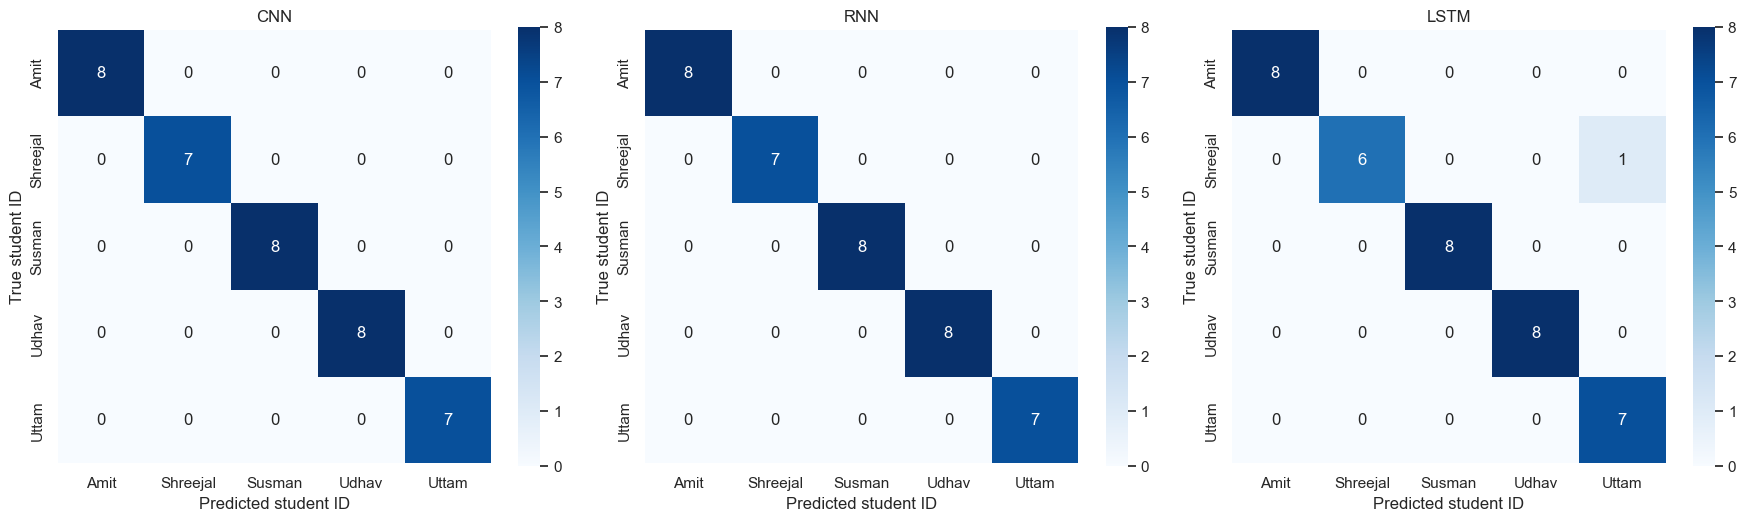

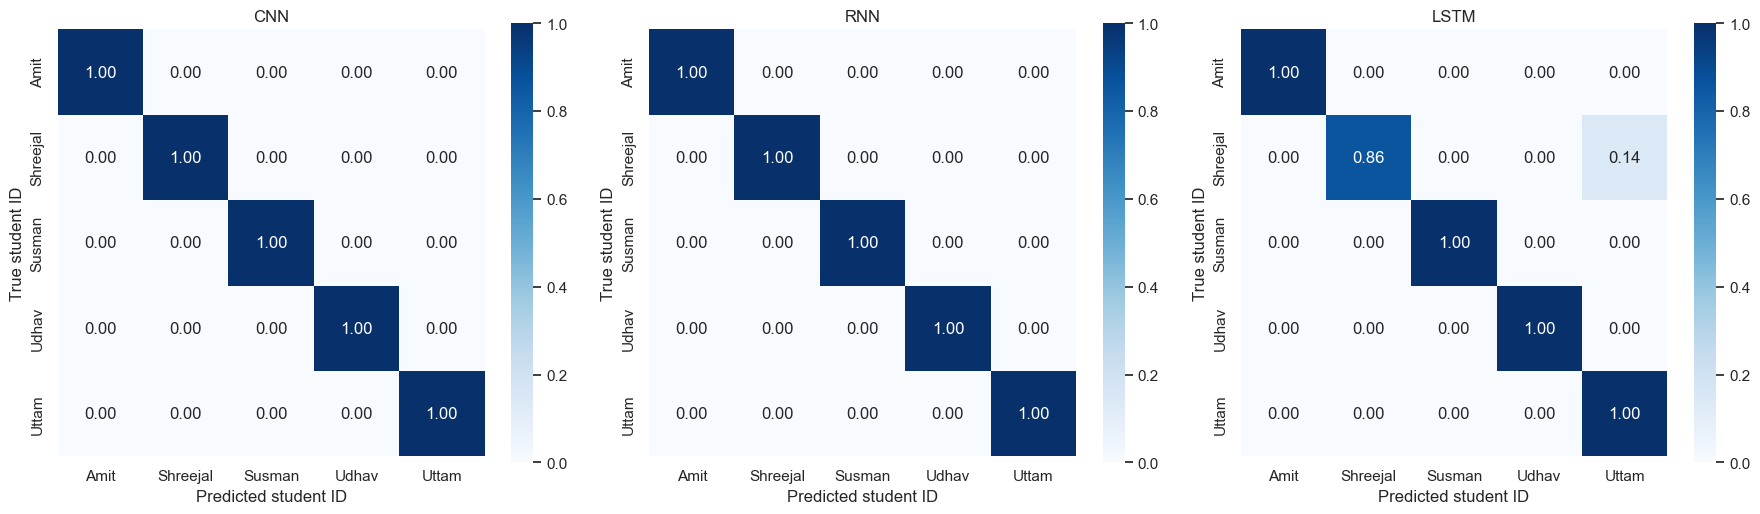

In [50]:
for normalized in (False, True):
    matrices = {
        name: confusion_matrix(y_test, scores.argmax(axis=1), labels=range(NUM_CLASSES))
        for name, scores in prediction_cache.items()
    }
    vmax = 1 if normalized else max(int(matrix.max()) for matrix in matrices.values())
    fig, axes = plt.subplots(1, 3, figsize=(max(18, NUM_CLASSES * 3), max(5, NUM_CLASSES * 0.8)))
    for ax, (name, matrix) in zip(axes, matrices.items()):
        values = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1) if normalized else matrix
        sns.heatmap(values, annot=True, fmt=".2f" if normalized else "d",
                    cmap="Blues", vmin=0, vmax=vmax, square=True, ax=ax,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
        ax.set(title=name, xlabel="Predicted student ID", ylabel="True student ID")
    finish_figure(fig, "confusion_normalized.png" if normalized else "confusion_counts.png")


## 32. Accuracy, Precision, Recall, and F1 Analysis

Macro metrics weight each identity equally; weighted metrics account for test support. Misidentifications can create false attendance, while missed identities can omit present students. Classification metrics alone do not measure the full detection, confirmation, and logging workflow.


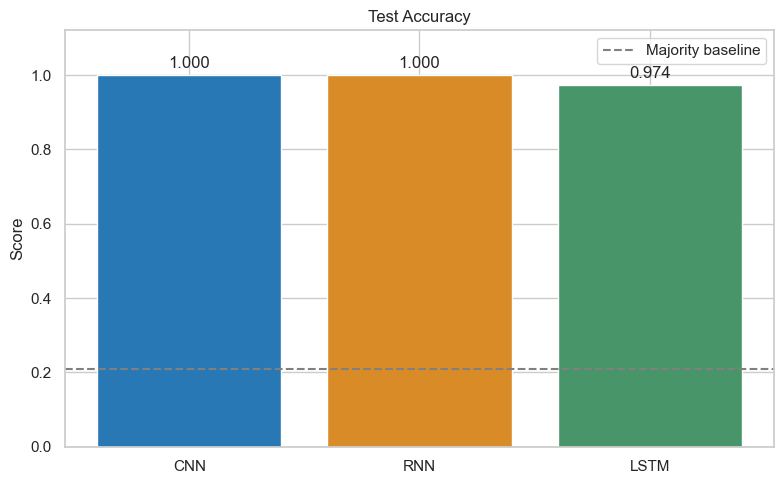

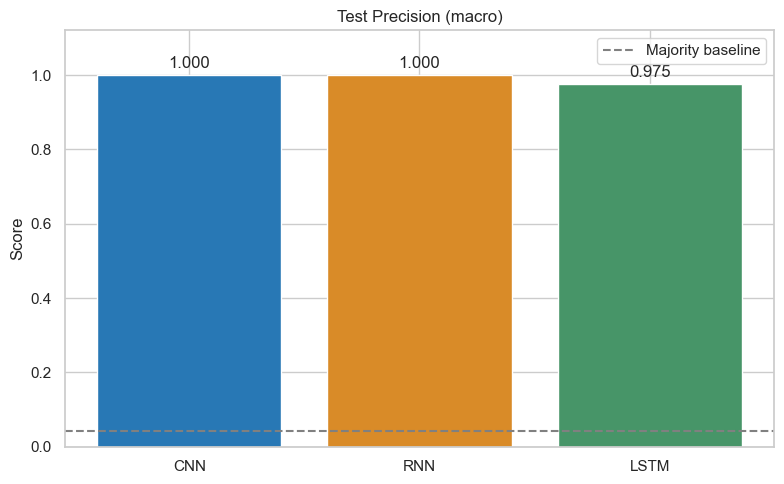

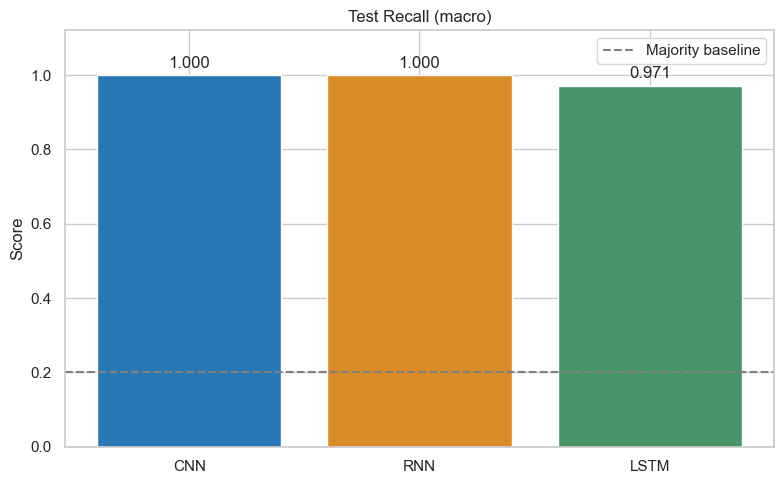

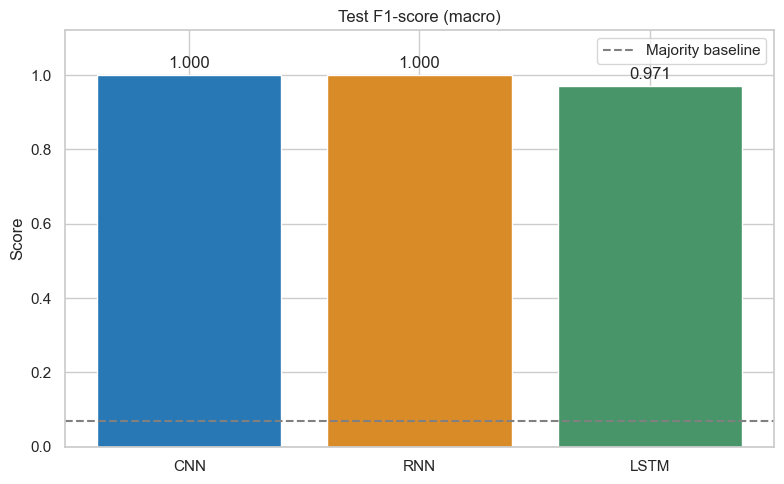

,Model,Student ID,Precision,Recall,F1-score,Support
0,CNN,Amit,1.000,1.0000,1.0000,8
1,CNN,Shreejal,1.000,1.0000,1.0000,7
2,CNN,Susman,1.000,1.0000,1.0000,8
3,CNN,Udhav,1.000,1.0000,1.0000,8
4,CNN,Uttam,1.000,1.0000,1.0000,7
5,RNN,Amit,1.000,1.0000,1.0000,8
6,RNN,Shreejal,1.000,1.0000,1.0000,7
7,RNN,Susman,1.000,1.0000,1.0000,8
8,RNN,Udhav,1.000,1.0000,1.0000,8
9,RNN,Uttam,1.000,1.0000,1.0000,7


In [51]:
for metric in ("Accuracy", "Precision", "Recall", "F1-score"):
    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(model_comparison["Model"], model_comparison[metric],
                  color=["#2878B5", "#D98B28", "#479568"])
    ax.bar_label(bars, fmt="%.3f", padding=3)
    baseline_value = majority_metrics[metric]
    ax.axhline(baseline_value, color="gray", linestyle="--", label="Majority baseline")
    ax.set(title=f"Test {metric}" + (" (macro)" if metric != "Accuracy" else ""),
           ylabel="Score", ylim=(0, 1.12))
    ax.legend()
    finish_figure(fig, f"test_{metric.lower()}.png")
display(all_per_class_metrics.round(4))


## 33. Training Time and Model Complexity

Model parameter count is not a complete measure of computation. Recurrent steps depend on earlier states; convolution can exploit parallel spatial operations. LSTM uses more gates than SimpleRNN. Actual speed depends on kernels, device, batch size, and implementation; use measured values below rather than assuming a winner.


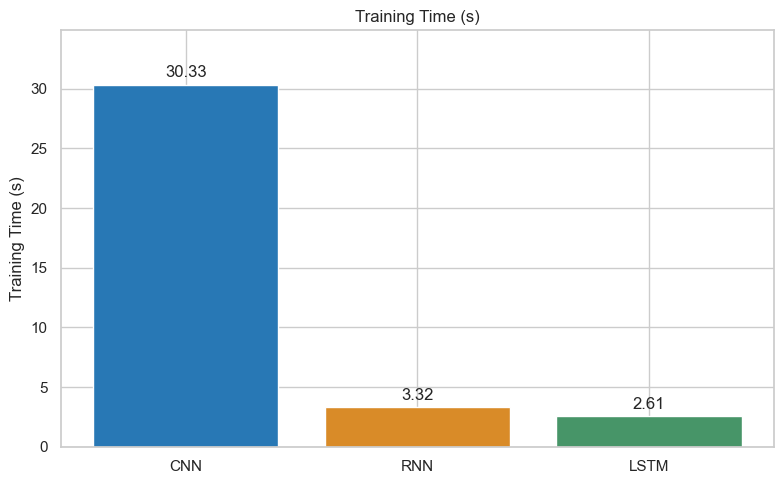

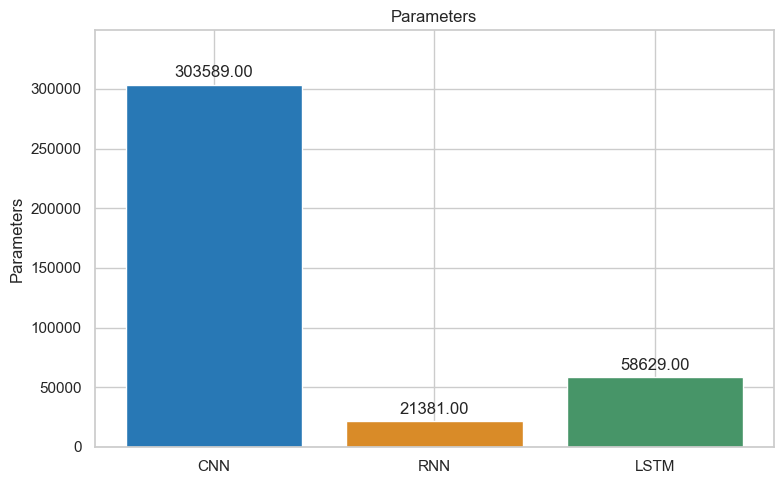

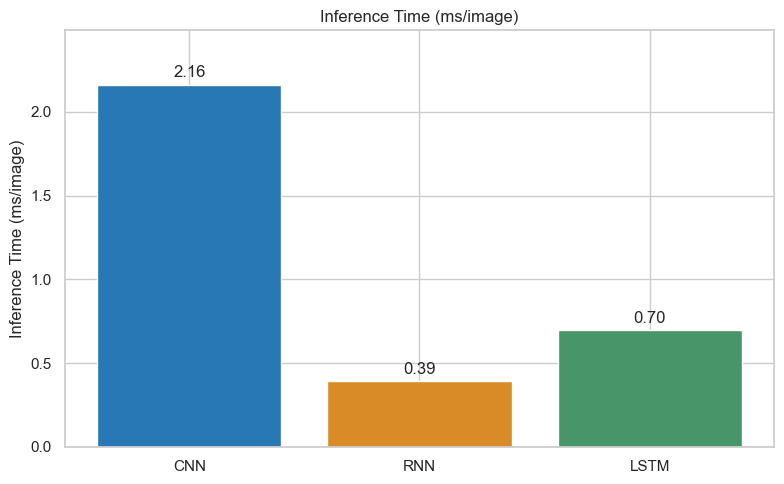

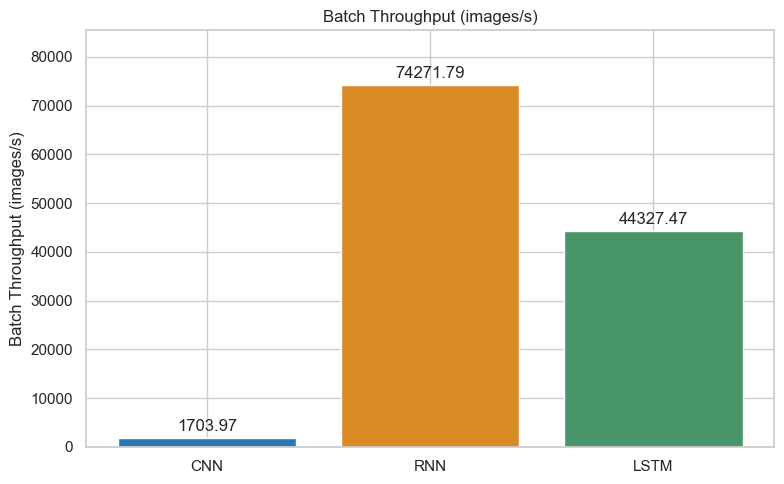

In [52]:
for metric, filename in [
    ("Training Time (s)", "training_time.png"),
    ("Parameters", "parameters.png"),
    ("Inference Time (ms/image)", "inference_latency.png"),
    ("Batch Throughput (images/s)", "batch_throughput.png"),
]:
    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(model_comparison["Model"], model_comparison[metric],
                  color=["#2878B5", "#D98B28", "#479568"])
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set(title=metric, ylabel=metric)
    ax.margins(y=0.15)
    finish_figure(fig, filename)


## 34. Why CNN Is Generally Appropriate for Face Images

**CNN.** Shared 3 × 3 convolutional filters learn local edges and textures in both image dimensions. Stacked blocks combine these into larger patterns, potentially including eyes, noses and facial contours. Pooling reduces resolution, while global average pooling limits the dense head's parameter count. Weight sharing reuses a detector across spatial positions. These properties give convolution a useful inductive bias for aligned face images, but do not establish that this trained model actually relies on facial rather than background cues.

**SimpleRNN.** Each row is a vector of 128 grayscale pixels. The network updates a 64-unit hidden state over 128 spatial steps, and the final state drives classification. It can learn cross-row relationships, but compressing an entire image into that state may lose detail. Adjacent columns are input features without the CNN's explicit local 2D weight sharing. Sequential state dependencies can limit parallel execution.

**LSTM.** Input, forget and output gates regulate a cell state and can preserve longer-range row information more effectively than a simple recurrence. This adds parameters and operations. Gated memory does not inherently supply the same local 2D structure as convolution, and longer-range sequence memory is not automatically the main difficulty in static face recognition.

These are architectural reasons to investigate CNN, not evidence of a guaranteed empirical win. On a small dataset, optimization, regularization, search budget, and capture-session similarity may dominate. Report ties and contrary results honestly.


In [53]:
best_test_accuracy = float(model_comparison["Accuracy"].max())
observed_test_leaders = model_comparison.loc[
    np.isclose(model_comparison["Accuracy"], best_test_accuracy), "Model"].tolist()
cnn_accuracy = float(model_comparison.set_index("Model").loc["CNN", "Accuracy"])
cnn_statement = (
    "CNN is among the observed test-accuracy leaders; this is consistent with its spatial inductive bias."
    if "CNN" in observed_test_leaders else
    "CNN did not achieve the highest test accuracy in this run. Its general spatial suitability does not override this observation."
)
display(Markdown(
    f"**Observed test leader(s):** {', '.join(observed_test_leaders)} "
    f"at {best_test_accuracy:.2%}. CNN test accuracy: {cnn_accuracy:.2%}. "
    f"{cnn_statement}\n\n"
    f"Majority baseline accuracy: {majority_metrics['Accuracy']:.2%}. "
    f"One test image changes accuracy by {100 / len(y_test):.2f} percentage points. "
    "This single-seed, small-sample comparison does not establish statistical superiority "
    "or reliable real-world attendance. Timing and per-class errors must also be discussed."
))


**Observed test leader(s):** CNN, RNN at 100.00%. CNN test accuracy: 100.00%. CNN is among the observed test-accuracy leaders; this is consistent with its spatial inductive bias.

Majority baseline accuracy: 21.05%. One test image changes accuracy by 2.63 percentage points. This single-seed, small-sample comparison does not establish statistical superiority or reliable real-world attendance. Timing and per-class errors must also be discussed.

## 35. Final Deployment Model Decision

The deployment decision was frozen at NN-10D before any new test evaluation. The CNN configuration comes from restored validation accuracy, then validation loss, within the predefined CNN deployment family. The same decision records parameter count and measured validation-input latency for practical review. It is a demonstration candidate, not a claim that it is always the fastest, smallest or most accurate model. Test leaders are reported separately above and do not change the saved model.

If operational validation shows poor latency or accuracy, revise the design and evaluate on a fresh, independent collection; do not repeatedly tune against this final test set.


In [54]:
assert deployment_decision["configuration"] == SELECTED_NAME
assert deployment_decision["test_used_for_selection"] is False
display(pd.Series(deployment_decision))


architecture                                                                                           CNN
configuration                                                                                 Larger Batch
selection_rule             CNN family predefined; restored validation accuracy descending, validation l...
validation_accuracy                                                                                    1.0
validation_loss                                                                                   0.001335
parameters                                                                                          303589
timing                     {'Inference Time (ms/image)': 2.1627999999509484, 'Batch Time (ms)': 18.7796...
test_used_for_selection                                                                              False
status                                   Academic demonstration candidate; no independent field validation
dtype: object

## 36. Save and Reload the Final PyTorch CNN

After training/evaluation, this cell saves `models/attendance_cnn.pt` as a CPU-portable tensor state dictionary, along with the ordered labels, preprocessing, exact CNN architecture configuration, confidence policy and experiment metadata. Loading reconstructs the model from JSON and uses `torch.load(..., weights_only=True)`.

This format replaces the previous Keras bundle. Existing `.keras` files are left untouched but are not compatible with these PyTorch demos. Retrain all experiments and regenerate the full four-file PyTorch bundle; do not mix old metadata or results. Re-running this cell replaces the generated PyTorch bundle.


In [55]:
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
torch.save({key: value.detach().cpu() for key, value in selected_model.state_dict().items()},
           MODEL_DIR / "attendance_cnn.pt")
(MODEL_DIR / "class_names.json").write_text(
    json.dumps(CLASS_NAMES, indent=2, ensure_ascii=False), encoding="utf-8")
(MODEL_DIR / "preprocessing_config.json").write_text(
    json.dumps(preprocessing_config, indent=2), encoding="utf-8")
model_metadata = {
    "project": "TECH 405 Smart Attendance System", "student": "Amit",
    "framework": "pytorch", "format_version": 1,
    "architecture_config": selected_model.model_config,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "selection": deployment_decision, "hardware": hardware_metadata,
    "random_seed": RANDOM_STATE, "split_protocol": SPLIT_PROTOCOL,
    "dataset_images": len(X), "number_of_classes": NUM_CLASSES,
    "split_sizes": {"train": len(X_train), "validation": len(X_val), "test": len(X_test)},
    "split_indices": {"train": train_indices.tolist(), "validation": val_indices.tolist(),
                      "test": test_indices.tolist()},
    "source_order_sha256": hashlib.sha256(
        "\n".join(model_df["filepath"].astype(str)).encode("utf-8")).hexdigest(),
    "model_sha256": hashlib.sha256((MODEL_DIR / "attendance_cnn.pt").read_bytes()).hexdigest(),
    "preprocessing_note": "Pillow grayscale L; bilinear stretch to 128x128; float32 / 255; source arrays HWC, model tensors NCHW.",
    "crop_note": "Training uses supplied face images; Haar crops may introduce a distribution shift.",
    "limitations": ["No validated open-set recognition", "No liveness or anti-spoofing",
                    "No independent field validation", "Biometric consent required"],
}
(MODEL_DIR / "model_metadata.json").write_text(
    json.dumps(model_metadata, indent=2, ensure_ascii=False), encoding="utf-8")
from attendance_utils import load_bundle, predict_face
loaded_model, loaded_names, loaded_config = load_bundle(MODEL_DIR)
print("Saved and reloaded:", MODEL_DIR / "attendance_cnn.pt")


Saved and reloaded: c:\Users\Asus\OneDrive\Pictures\Smart_Attendance_System\models\attendance_cnn.pt


## 37. Single-Image Prediction

Set `FACE_IMAGE_PATH` to a tightly cropped face image with the enrolled person's consent. This path-based upload equivalent shows the top three uncalibrated softmax scores. A score below the configured threshold is rejected as Unknown. A stranger may still receive a high known-class score; threshold rejection is **not** validated open-set recognition. This cell never marks attendance.


In [56]:
FACE_IMAGE_PATH = None  # Example: PROJECT_ROOT / "private_demo" / "face.jpg"
if FACE_IMAGE_PATH is None:
    print("Set FACE_IMAGE_PATH to a consented face crop, then rerun this cell.")
else:
    image_path = Path(FACE_IMAGE_PATH).expanduser()
    if not image_path.is_absolute():
        image_path = PROJECT_ROOT / image_path
    try:
        result = predict_face(loaded_model, loaded_names, loaded_config, image_path)
        with Image.open(image_path) as face:
            plt.figure(figsize=(4, 4))
            plt.imshow(face.convert("L"), cmap="gray")
            plt.title(f"{result['student_id']} | softmax score {result['confidence']:.3f}")
            plt.axis("off")
            plt.show()
        display(pd.DataFrame(result["top_classes"], columns=["Student ID", "Softmax score"]))
        print("Heuristic accepted:", result["accepted"], "— no attendance written.")
    except (OSError, ValueError) as exc:
        print(f"Cannot predict this image: {exc}")


Set FACE_IMAGE_PATH to a consented face crop, then rerun this cell.


## 38. Local Live Attendance Demonstration

Use a local terminal, after NN-36 creates the model bundle:

```text
python live_attendance.py
```

The script first explains consent and asks the enrolled student to enter their own ID to opt in. It detects faces using OpenCV's Haar cascade, converts the detected BGR crop to RGB for Pillow, and applies the same grayscale/resize/normalization as training. The detector only finds a face; the CNN classifies identity.

Show exactly one face. Eight consecutive sufficiently confident predictions for the opted-in ID enable a visible confirmation prompt. Press **C** only after the student verifies the displayed identity; the preview freezes for a typed confirmation before writing. Press **N** to switch students and **Q** to quit. Multiple faces, missing faces, uncertain scores or an identity change reset acceptance. CSV logging prevents the same student/date from being marked twice. Dates use the configured Asia/Katmandu local timezone.

This heuristic is not liveness detection. Printed photos and replayed videos can fool it. Enrollment consent must cover collection and model training; demo opt-in does not retroactively grant that consent. Provide a manual attendance alternative.

Colab's `cv2.VideoCapture(0)` generally addresses the remote runtime, not the user's local camera. Download the model bundle and run this script locally. Haar crops can differ from collected image crops; inspect that mismatch on new consented validation images before relying on a demonstration.


## 39. Export Real Results

This cell writes results only from the current execution. Exports, labels, figures, model files and notebook outputs may contain private student information. They are ignored by Git; review and anonymize before public sharing. No fabricated results or empty result tables are distributed.


In [57]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
model_comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
roc_auc_per_class.to_csv(RESULTS_DIR / "roc_auc_per_class.csv", index=False)
all_per_class_metrics.to_csv(RESULTS_DIR / "per_class_metrics.csv", index=False)
experiment_configurations = pd.DataFrame([
    {"Model": family, **run["result"]}
    for family, runs in [("CNN", experiments), ("RNN", rnn_experiments), ("LSTM", lstm_experiments)]
    for run in runs.values()
])
experiment_configurations.to_csv(RESULTS_DIR / "experiment_configurations.csv", index=False)
validation_comparison.to_csv(RESULTS_DIR / "validation_comparison.csv", index=False)
summary = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "model_comparison": model_comparison.to_dict(orient="records"),
    "roc_auc_per_class": roc_auc_per_class.to_dict(orient="records"),
    "majority_baseline": majority_metrics, "classification_reports": classification_reports,
    "observed_test_leaders": observed_test_leaders,
    "deployment_decision": deployment_decision, "hardware": hardware_metadata,
    "split_protocol": SPLIT_PROTOCOL, "seed": RANDOM_STATE,
    "cnn_search_runs": len(experiments),
    "rnn_search_runs": len(rnn_experiments), "lstm_search_runs": len(lstm_experiments),
}
(RESULTS_DIR / "summary.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
print("Exported actual results to", RESULTS_DIR)


Exported actual results to c:\Users\Asus\OneDrive\Pictures\Smart_Attendance_System\results


## 40. Academic Discussion

### Abstract
This TECH 405 project investigates enrolled-student face classification for an opt-in attendance demonstration. It extends the original image EDA and five CNN experiments with SimpleRNN and LSTM baselines on identical splits. Validation selects model configurations; the held-out test set supplies accuracy, macro and weighted precision/recall/F1, per-class reports and confusion matrices. Parameter counts and measured training/inference cost complement predictive performance. The local demo combines face detection, uncertainty rejection, consistent predictions and explicit attendance confirmation. Insert only the runtime findings printed below in the submitted abstract.

### Introduction
Manual attendance consumes class time and can contain recording errors. Face recognition is investigated as an optional assistance mechanism, with human confirmation and a manual alternative. Its convenience must be considered alongside misidentification and biometric privacy risks.

### Problem Statement
Given a grayscale face crop, predict one of the enrolled identity labels. The training task is closed-set classification, not recognition of arbitrary new identities, calibrated verification or liveness detection. The end-to-end demo also depends on a separate face detector and the enrolled student's confirmation.

### Objectives
Preserve the EDA, implement three genuine architectures under shared controls, compare predictive quality and efficiency, select a transparent deployment candidate, persist its inference contract, and demonstrate consented CSV attendance without claiming production readiness.

### Dataset Description
The historical collection contained 250 grayscale images in five student folders, 50 per student, originally 200 × 200. Current counts, labels, balance, resolution and quality checks are computed by EDA and NN-1; those outputs supersede historical descriptions. Runtime additions may change the number of enrolled identities. Files must have been collected with permission. Consecutive capture frames are correlated and are not independent samples.

### Methodology
The loader converts with Pillow to grayscale, resizes bilinearly to 128 × 128, divides float32 pixels by 255, and encodes folder labels once. The default is the original seed-42 stratified 70/15/15 image split. All architectures share its exact indices. An explicitly enabled session-aware alternative assigns entire sessions within each identity and requires at least three sessions per identity. Neither protocol by itself guarantees that all near-duplicates or background shortcuts have been eliminated. Corrupt files and exact duplicates cause a pretraining stop for manual resolution.

Train-only flips, rotations, translation, zoom and brightness adjustments run before recurrent channel squeezing. EarlyStopping restores the minimum-validation-loss epoch. Restored validation accuracy then loss determine configuration selection. Five CNN experiments are preserved; recurrent variants are optional. Different search budgets and parameter counts constrain causal claims about architecture.

### CNN Architecture
Three configurable blocks each apply two ReLU 3 × 3 convolutions, max pooling and dropout. Global average pooling feeds a ReLU dense layer, head dropout and class logits with inference softmax. Filter widths, dropout, learning rate and batch-size variations follow the original experiments. NN-10 prints the actual selected architecture.

### RNN Architecture
The simple `nn.RNN` processes 128 spatial rows, each with 128 features, into a default 64-unit hidden state. Dropout and a ReLU dense head precede class logits; softmax is applied during inference. This is genuine simple recurrence; the image does not contain temporal observations.

### LSTM Architecture
LSTM uses a default 64-unit gated recurrent state over the same rows. Its gates can retain longer-range row information, with additional parameter and compute costs. The post-recurrence head matches the RNN baseline.

### Experimental Setup
Seed 42, actual library versions, CPU/GPU devices and platform are recorded. Epoch budget and stopping and scheduling controls match the selected CNN; actual early-stopping lengths may differ. Recurrent baselines use the selected CNN's batch size, learning rate, dense width and head dropout. Single-image synchronized eager-call latency and batched throughput are measured separately on validation images using three warm-ups and twenty repetitions. The synchronized fit timer includes augmentation, validation, scheduler/logging work and best-weight snapshots, but excludes initial model construction/transfer and later restored-weight evaluation. Seeds improve reproducibility but do not guarantee bitwise identity across hardware.

### Results and Discussion
Use the computed tables and generated paragraph below. Discuss per-class errors, score ties, learning curves and measured latency, not just the highest accuracy. Training/validation gaps are affected by augmentation and dropout. A high test score can reflect session or background similarity. No additional hyperparameter choice may use this test result. A single run cannot establish statistical superiority.

### Why CNN Is Appropriate
Local two-dimensional filtering, shared weights and hierarchical feature composition align naturally with spatial face patterns. This is an architectural rationale, not a guarantee that CNN wins this particular test. NN-34 explicitly reports whether the actual results agree.

### Live Demonstration
Consented enrollment provides labelled face crops before training. Haar detection locates a face; the saved CNN predicts a label. Low scores are shown as Unknown, and only consistent predictions matching the opted-in student's ID enable confirmation. The student verifies the visible identity before a dated CSV record is appended. This demonstration does not validate the entire pipeline's field reliability.

### Limitations
Small class/sample counts, possibly five enrolled identities in the historical collection, burst-frame correlation, train/test similarity, lighting and camera variation, cropping/detector errors, background shortcuts and overfitting limit generalization. Unseen students may receive confident enrolled labels. Softmax scores are not calibrated probabilities. There is no genuine independent field evaluation and no validated unknown-person rejection. Printed-photo and video-replay attacks are not reliably detected. Biometric consent, limited local access, retention/deletion arrangements and a manual alternative are required. Do not publish identifiable face images, IDs, model bundles, attendance records or unredacted screenshots.

### Future Improvements
Collect consented multi-day/session data with session identifiers, evaluate across cameras and lighting, compare consistent aligned crops, collect a separate unknown-person validation set, measure calibration and false acceptance/rejection, repeat experiments over seeds and sessions, assess lightweight transfer learning or embeddings, and evaluate presentation-attack defenses independently. These require new evidence; better performance is not guaranteed.

### Sources for Implementation
[PyTorch installation](https://pytorch.org/get-started/locally/) documents CUDA builds and platform support. [Saving/loading models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html) explains state dictionaries. [ReduceLROnPlateau](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html) documents the scheduler. These sources support implementation details, not claims about this dataset's results.


In [58]:
result_sentences = []
for row in model_comparison.to_dict(orient="records"):
    result_sentences.append(
        f"**{row['Model']}**: accuracy {row['Accuracy']:.2%}; macro precision/recall/F1 "
        f"{row['Precision']:.4f}/{row['Recall']:.4f}/{row['F1-score']:.4f}; "
        f"{row['Parameters']:,} parameters; selected-run training "
        f"{row['Training Time (s)']:.1f} s; batch-one latency "
        f"{row['Inference Time (ms/image)']:.2f} ms.")
display(Markdown(
    f"Current data: **{len(X)} images, {NUM_CLASSES} enrolled identities**, "
    f"split **{len(X_train)}/{len(X_val)}/{len(X_test)}** under {SPLIT_PROTOCOL}.\n\n"
    + "\n\n".join(result_sentences)
    + f"\n\nObserved test leader(s): **{', '.join(observed_test_leaders)}**. "
    + f"Predefined deployment candidate: **CNN / {SELECTED_NAME}**, selected using validation. "
    + cnn_statement
))


Current data: **250 images, 5 enrolled identities**, split **175/37/38** under stratified image-level 70/15/15.

**CNN**: accuracy 100.00%; macro precision/recall/F1 1.0000/1.0000/1.0000; 303,589 parameters; selected-run training 30.3 s; batch-one latency 2.16 ms.

**RNN**: accuracy 100.00%; macro precision/recall/F1 1.0000/1.0000/1.0000; 21,381 parameters; selected-run training 3.3 s; batch-one latency 0.39 ms.

**LSTM**: accuracy 97.37%; macro precision/recall/F1 0.9750/0.9714/0.9713; 58,629 parameters; selected-run training 2.6 s; batch-one latency 0.70 ms.

Observed test leader(s): **CNN, RNN**. Predefined deployment candidate: **CNN / Larger Batch**, selected using validation. CNN is among the observed test-accuracy leaders; this is consistent with its spatial inductive bias.

## 41. Conclusion

The completed implementation supports EDA, common preprocessing, five preserved CNN experiments, genuine SimpleRNN and LSTM baselines, validation-based configuration choices and a held-out comparison with efficiency measurements. The saved CNN is the predefined spatial-image demonstration candidate. The preceding generated paragraph supplies the actual findings once this notebook runs; no empirical winner is assumed beforehand.

The local demo illustrates detection, prediction, uncertainty handling and confirmed opt-in attendance. A small image-level test cannot establish real-world reliability, unknown-person rejection or spoof resistance. Independent session/camera evaluation and an explicit biometric-data policy are prerequisites to considering use beyond an academic demonstration.
